**Import Data**

In [1]:
import pandas as pd
import numpy as np

In [2]:
inputs_test_with_ref_cat = pd.read_pickle('inputs_test_with_ref_cat.pkl')
df_scorecard = pd.read_pickle('df_score_card.pkl')

In [3]:
# We also need the new population and it comprises borrowers from 2015 and can be located in 'loan_data_2015.csv'

loan_data_backup = pd.read_csv("D:/DEO DESKTOP FOLDER/WEBSITE/CREDIT RISK MODELLING/loan_data_2015.csv", low_memory=False) 

In [4]:
loan_data = loan_data_backup.copy()

**Explore Data** 

In [6]:
loan_data.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,68444620,73334399,35000,35000,35000.0,60 months,11.99,778.38,C,C1,Foreign Service Officer,10+ years,MORTGAGE,128000.0,Source Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,home_improvement,Home improvement,200xx,DC,6.46,0.0,Feb-90,0.0,46.0,NaN,17.0,0.0,14277,27.4,46.0,w,35000.0,35000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Jan-16,Jan-16,0.0,56.0,1,INDIVIDUAL,NaN,NaN,NaN,0.0,321.0,146867.0,1.0,11.0,0.0,0.0,28.0,35367.0,49.3,0.0,1.0,5020.0,40.1,52200.0,1.0,4.0,0.0
1,68547583,73437441,8650,8650,8650.0,36 months,5.32,260.50,A,A1,Associate Consultant,< 1 year,MORTGAGE,100000.0,Not Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,credit_card,Credit card refinancing,462xx,IN,7.28,0.0,Jul-01,0.0,NaN,NaN,15.0,0.0,7158,26.7,24.0,w,8650.0,8650.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Jan-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,165450.0,0.0,1.0,1.0,1.0,11.0,24041.0,88.8,0.0,3.0,3081.0,57.9,26800.0,1.0,0.0,5.0
2,67849662,72708407,4225,4225,4225.0,36 months,14.85,146.16,C,C5,mechanic,5 years,RENT,35000.0,Source Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,debt_consolidation,Debt consolidation,672xx,KS,15.22,2.0,Jul-11,0.0,18.0,NaN,6.0,0.0,1058,24.6,6.0,w,4225.0,4225.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Jan-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,4888.0,0.0,1.0,0.0,0.0,47.0,3830.0,21.9,0.0,0.0,367.0,22.4,4300.0,0.0,0.0,0.0
3,68506885,73396712,10000,10000,10000.0,60 months,11.99,222.40,C,C1,CARDIOVASCULAR TECH,10+ years,RENT,42500.0,Not Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,debt_consolidation,Debt consolidation,460xx,IN,31.04,0.0,Dec-98,1.0,NaN,NaN,10.0,0.0,5812,40.9,23.0,w,10000.0,10000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Jan-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,41166.0,1.0,3.0,0.0,2.0,13.0,35354.0,75.5,1.0,1.0,3118.0,67.4,14200.0,1.0,1.0,1.0
4,68341763,72928789,20000,20000,20000.0,60 months,10.78,432.66,B,B4,truck driver,10+ years,MORTGAGE,63000.0,Not Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,home_improvement,NaN,605xx,IL,10.78,0.0,Aug-00,0.0,NaN,NaN,6.0,0.0,7869,56.2,18.0,w,20000.0,20000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Jan-16,Dec-15,0.0,NaN,1,JOINT,71000.0,13.85,Not Verified,0.0,0.0,189699.0,0.0,1.0,0.0,4.0,19.0,10827.0,72.8,0.0,2.0,2081.0,64.7,14000.0,2.0,5.0,1.0


In [7]:
loan_data.columns

Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose',
       'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs',
       'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq',
       'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'initial_list_status', 'out_prncp',
       'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
       'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'mths_since_last_major_derog', 'policy_code', 'application_type',
       'annual_inc_joint', 'dti_joint', 'verification_status_joint',
    

In [8]:
loan_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421094 entries, 0 to 421093
Data columns (total 74 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           421094 non-null  int64  
 1   member_id                    421094 non-null  int64  
 2   loan_amnt                    421094 non-null  int64  
 3   funded_amnt                  421094 non-null  int64  
 4   funded_amnt_inv              421094 non-null  float64
 5   term                         421094 non-null  object 
 6   int_rate                     421094 non-null  float64
 7   installment                  421094 non-null  float64
 8   grade                        421094 non-null  object 
 9   sub_grade                    421094 non-null  object 
 10  emp_title                    397220 non-null  object 
 11  emp_length                   397277 non-null  object 
 12  home_ownership               421094 non-null  object 
 13 

**General Preprocessing**
**Preprocessing few continuous variables**

In [9]:
loan_data['emp_length'].unique()

array(['10+ years', '< 1 year', '5 years', '3 years', '4 years', nan,
       '2 years', '8 years', '9 years', '1 year', '6 years', '7 years'],
      dtype=object)

In [10]:
loan_data[~loan_data['emp_length'].duplicated()].sample(5)

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
8,68426831,73316657,11950,11950,11950.0,36 months,13.44,405.18,C,C3,Veterinary Tecnician,4 years,RENT,34000.0,Source Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,debt_consolidation,Debt consolidation,300xx,GA,10.20,0.0,Oct-87,0.0,NaN,NaN,5.0,0.0,8822,68.4,6.0,w,11950.0,11950.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Jan-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,12798.0,0.0,1.0,0.0,0.0,338.0,3976.0,99.4,0.0,0.0,4522.0,75.7,12900.0,0.0,0.0,0.0
9,68377020,73266845,15000,15000,15000.0,36 months,5.32,451.73,A,A1,NaN,NaN,RENT,80000.0,Not Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,debt_consolidation,Debt consolidation,236xx,VA,20.18,0.0,Apr-93,1.0,35.0,NaN,30.0,0.0,41593,21.4,47.0,w,15000.0,15000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,330562.0,1.0,1.0,0.0,0.0,54.0,55536.0,NaN,2.0,6.0,2491.0,21.4,194800.0,1.0,1.0,3.0
12,68585839,73475629,17475,17475,17475.0,36 months,13.99,597.17,C,C4,Software Testing Analyst,2 years,RENT,39750.0,Not Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,debt_consolidation,Debt consolidation,604xx,IL,23.58,0.0,May-02,0.0,27.0,NaN,7.0,0.0,10987,52.3,13.0,w,17475.0,17475.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,32365.0,0.0,3.0,0.0,1.0,18.0,21378.0,73.1,1.0,2.0,9131.0,64.4,21000.0,1.0,0.0,3.0
0,68444620,73334399,35000,35000,35000.0,60 months,11.99,778.38,C,C1,Foreign Service Officer,10+ years,MORTGAGE,128000.0,Source Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,home_improvement,Home improvement,200xx,DC,6.46,0.0,Feb-90,0.0,46.0,NaN,17.0,0.0,14277,27.4,46.0,w,35000.0,35000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Jan-16,Jan-16,0.0,56.0,1,INDIVIDUAL,NaN,NaN,NaN,0.0,321.0,146867.0,1.0,11.0,0.0,0.0,28.0,35367.0,49.3,0.0,1.0,5020.0,40.1,52200.0,1.0,4.0,0.0
2,67849662,72708407,4225,4225,4225.0,36 months,14.85,146.16,C,C5,mechanic,5 years,RENT,35000.0,Source Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,debt_consolidation,Debt consolidation,672xx,KS,15.22,2.0,Jul-11,0.0,18.0,NaN,6.0,0.0,1058,24.6,6.0,w,4225.0,4225.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Jan-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,4888.0,0.0,1.0,0.0,0.0,47.0,3830.0,21.9,0.0,0.0,367.0,22.4,4300.0,0.0,0.0,0.0


In [11]:
loan_data['emp_length_int'] = loan_data['emp_length'].str.replace(r'\+ years', '',regex=True)
loan_data['emp_length_int'] = loan_data['emp_length_int'].str.replace('< 1 year', str(0))
loan_data['emp_length_int'] = loan_data['emp_length_int'].str.replace('n/a', str(0))
loan_data['emp_length_int'] = loan_data['emp_length_int'].str.replace(' years', '')
loan_data['emp_length_int'] = loan_data['emp_length_int'].str.replace(' year', '')

In [12]:
loan_data['emp_length_int'] = pd.to_numeric(loan_data['emp_length_int'])

In [13]:
type(loan_data['emp_length_int'][0])

numpy.float64

**HOMEWORK:** PREPROCESS earliest_cr_line VARIABLE 

In [14]:
type(loan_data['earliest_cr_line'])

pandas.core.series.Series

In [15]:
type(loan_data['earliest_cr_line'][0])

str

In [16]:
loan_data['earliest_cr_line_date'] = pd.to_datetime(loan_data['earliest_cr_line'], format = '%b-%y')

In [17]:
type(loan_data['earliest_cr_line_date'][0]) 

pandas._libs.tslibs.timestamps.Timestamp

In [18]:
pd.to_datetime('2017-12-01') - loan_data['earliest_cr_line_date'].sample(3)

30021   4597 days
77646   4992 days
28004   6392 days
Name: earliest_cr_line_date, dtype: timedelta64[ns]

In [19]:
loan_data['mths_since_earliest_cr_line'] = round(
    pd.to_numeric((pd.to_datetime('2017-12-01')-loan_data['earliest_cr_line_date'])/np.timedelta64(30,'D')))

In [20]:
loan_data['mths_since_earliest_cr_line'].describe()

count    421094.000000
mean        230.673481
std          99.557666
min        -621.000000
25%         169.000000
50%         215.000000
75%         281.000000
max         596.000000
Name: mths_since_earliest_cr_line, dtype: float64

In [21]:
loan_data['issue_d'].head()

0    Dec-15
1    Dec-15
2    Dec-15
3    Dec-15
4    Dec-15
Name: issue_d, dtype: object

In [22]:
loan_data.loc[:, ['earliest_cr_line', 'earliest_cr_line_date', 'mths_since_earliest_cr_line']][loan_data['mths_since_earliest_cr_line']<0].head(5)

,earliest_cr_line,earliest_cr_line_date,mths_since_earliest_cr_line
254,Jan-57,2057-01-01,-476.0
618,Aug-64,2064-08-01,-568.0
648,Jul-68,2068-07-01,-616.0
1808,Jan-65,2065-01-01,-573.0
2583,Sep-64,2064-09-01,-569.0


In [23]:
loan_data['mths_since_earliest_cr_line'][loan_data['mths_since_earliest_cr_line']<0] = loan_data['mths_since_earliest_cr_line'].max()

C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2340731311.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  loan_data['mths_since_earliest_cr_line'][loan_data['mths_since_earliest_cr_line']<0] = loan_data['mths_since_earliest_cr_line'].ma

In [24]:
loan_data['mths_since_earliest_cr_line'][loan_data['mths_since_earliest_cr_line']<0] = max(loan_data['mths_since_earliest_cr_line'])

C:\Users\USER\AppData\Local\Temp\ipykernel_3412\723178854.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  loan_data['mths_since_earliest_cr_line'][loan_data['mths_since_earliest_cr_line']<0] = max(loan_data['mths_since_earliest_cr_line']

In [25]:
min(loan_data['mths_since_earliest_cr_line'])

62.0

>>> Term Variable 

In [26]:
def clean_term(term_series):
    """Clean term column and convert to numeric"""
    # Handle the string conversions
    cleaned = (term_series.str.replace(r'\+ months', '', regex=True)
                         .str.replace('< 1 month', '0')
                         .str.replace('n/a', '0')
                         .str.replace(r"months?|[+]", "", regex=True)
                         .fillna('0')
                         .replace(np.nan, '0')
                        .str.strip()
              )

    
    # Convert to numeric, coercing errors to NaN
    return pd.to_numeric(cleaned, errors='coerce').fillna(0)

loan_data['term_int'] = clean_term(loan_data['term'])

print("First few values:")
print(loan_data[['term', 'term_int']].head())
print("Data types:")
loan_data['term_int'].dtype

First few values:
         term  term_int
0   60 months        60
1   36 months        36
2   36 months        36
3   60 months        60
4   60 months        60
Data types:


dtype('int64')

**HOMEWORK:** Calculate time since loan was issued 

In [27]:
f'"# Instead of "2017-12-01", use "2017-12-02"\
ref = pd.Timestamp("2017-12-02")\
\
# Or use end of month\
ref = pd.Timestamp("2017-12-31")"'


loan_data['issue_d_date'] = pd.to_datetime(loan_data['issue_d'], format = '%b-%y')

pd.to_datetime("2017-11-01")-loan_data['issue_d_date']

'''loan_data['mths_since_issue_d'] = round(
    pd.to_numeric((pd.to_datetime("2017-11-01")-loan_data['issue_d_date'])/np.timedelta64(1,'M'))) # rounding is simply to get whole numbers '''


loan_data['mths_since_issue_d'] = round(
    pd.to_numeric((pd.to_datetime("2017-11-01")-loan_data['issue_d_date'])/np.timedelta64(30,'D'))) #instead of dividing by 30 just directly get difference in months 

print(loan_data['mths_since_issue_d'].describe())

# we are interested in issue date and months since issue date hence below we show the issue date string, issue date Timestamp and months since issue date
#The mask is only for observations were months since issue is negative ie <0


print(loan_data.loc[:, ['issue_d', 'issue_d_date', 'mths_since_issue_d']][loan_data['mths_since_issue_d']<0])
min(loan_data['mths_since_issue_d'])

count    421094.000000
mean         28.189079
std           3.613435
min          23.000000
25%          25.000000
50%          28.000000
75%          32.000000
max          34.000000
Name: mths_since_issue_d, dtype: float64
Empty DataFrame
Columns: [issue_d, issue_d_date, mths_since_issue_d]
Index: []


23.0

In [28]:
loan_data['mths_since_issue_d'].unique()

array([23., 24., 25., 26., 27., 28., 29., 30., 32., 33., 34.])

In [29]:
loan_data['issue_d_date'] = pd.to_datetime(loan_data['issue_d'], format='%b-%y')
ref = pd.to_datetime("2017-11-01")

loan_data['mths_since_issue_d'] = (
    (ref.year - loan_data['issue_d_date'].dt.year) * 12 + 
    (ref.month - loan_data['issue_d_date'].dt.month) -
    (ref.day < loan_data['issue_d_date'].dt.day).astype(int)
)

print(loan_data['mths_since_issue_d'].describe())
print(loan_data.loc[:, ['issue_d', 'issue_d_date', 'mths_since_issue_d']][loan_data['mths_since_issue_d'] < 0])

# Fix negative values
mask = loan_data['mths_since_issue_d'] < 0
loan_data.loc[mask, 'mths_since_issue_d'] = loan_data['mths_since_issue_d'].max()

count    421094.000000
mean         28.044629
std           3.458162
min          23.000000
25%          25.000000
50%          28.000000
75%          31.000000
max          34.000000
Name: mths_since_issue_d, dtype: float64
Empty DataFrame
Columns: [issue_d, issue_d_date, mths_since_issue_d]
Index: []


In [30]:
loan_data.loc[
    loan_data['mths_since_issue_d'] < 0,
    'mths_since_issue_d'
] = max(loan_data['mths_since_issue_d'])

In [31]:
import gc
gc.collect()

124

** **PREPROCESSING FEW DISCRETE VARIABLES** *

In [32]:
loan_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421094 entries, 0 to 421093
Data columns (total 80 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   id                           421094 non-null  int64         
 1   member_id                    421094 non-null  int64         
 2   loan_amnt                    421094 non-null  int64         
 3   funded_amnt                  421094 non-null  int64         
 4   funded_amnt_inv              421094 non-null  float64       
 5   term                         421094 non-null  object        
 6   int_rate                     421094 non-null  float64       
 7   installment                  421094 non-null  float64       
 8   grade                        421094 non-null  object        
 9   sub_grade                    421094 non-null  object        
 10  emp_title                    397220 non-null  object        
 11  emp_length                

**RECOMMENDED CREATE NEW DATA FRAME TO STORE ALL NEW DUMMY VARIABLES TO THE LONE DATAFRAME FROM WHICH TO CONCATENATE TO THE LOAN DATAFRAME
EFFECTIVELY WE WILL APPEND THE COLUMNS WITH THE DUMMY VARIABLES TO THE COLUMNS OF THE LOAN DATAFRAME**

In [33]:
loan_data.grade.head()

0    C
1    A
2    C
3    C
4    B
Name: grade, dtype: object

In [34]:
pd.get_dummies(loan_data['grade']).head()

,A,B,C,D,E,F,G
0,False,False,True,False,False,False,False
1,True,False,False,False,False,False,False
2,False,False,True,False,False,False,False
3,False,False,True,False,False,False,False
4,False,True,False,False,False,False,False


In [35]:
pd.get_dummies(loan_data['grade'], dtype=int).head()

,A,B,C,D,E,F,G
0,0,0,1,0,0,0,0
1,1,0,0,0,0,0,0
2,0,0,1,0,0,0,0
3,0,0,1,0,0,0,0
4,0,1,0,0,0,0,0


In [36]:
pd.get_dummies(loan_data['grade'],  prefix = 'deo_grade', prefix_sep = '=', dtype=int).head()

,deo_grade=A,deo_grade=B,deo_grade=C,deo_grade=D,deo_grade=E,deo_grade=F,deo_grade=G
0,0,0,1,0,0,0,0
1,1,0,0,0,0,0,0
2,0,0,1,0,0,0,0
3,0,0,1,0,0,0,0
4,0,1,0,0,0,0,0


In [37]:
                   
loan_data_dummies = pd.concat([
    pd.get_dummies(loan_data['grade'], prefix='grade', prefix_sep=':::'),
    pd.get_dummies(loan_data['sub_grade'], prefix='sub_grade', prefix_sep=':::'),
    pd.get_dummies(loan_data['verification_status'], prefix='verification_status', prefix_sep=':::'),
    pd.get_dummies(loan_data['home_ownership'], prefix='home_ownership', prefix_sep=':'),
    pd.get_dummies(loan_data['loan_status'], prefix='loan_status', prefix_sep=':::'),
    pd.get_dummies(loan_data['purpose'], prefix='purpose', prefix_sep=':::'),
    pd.get_dummies(loan_data['addr_state'], prefix='addr_state', prefix_sep=':'),
    pd.get_dummies(loan_data['initial_list_status'], prefix='initial_list_status', prefix_sep=':::')
], axis=1)

           


In [38]:
loan_data_dummies = pd.concat([loan_data, loan_data_dummies], axis=1)

In [39]:
loan_data['loan_status'].value_counts() # Counts per loan status

# loan_data[['loan_status']]     # DataFrame → shape (93257, 1)
# loan_data['loan_status']       # Series → shape (93257,)


loan_status
Current               377553
Fully Paid             22984
Issued                  8460
Late (31-120 days)      4691
In Grace Period         3107
Charged Off             2773
Late (16-30 days)       1139
Default                  387
Name: count, dtype: int64

In [40]:
loan_data = pd.concat([loan_data, loan_data_dummies], axis=1)

**Check for missing Values and Clean**

In [41]:
loan_data.isnull().head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,term_int,issue_d_date,mths_since_issue_d,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,term_int,issue_d_date,mths_since_issue_d,grade:::A,grade:::B,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,sub_grade:::A1,sub_grade:::A2,sub_grade:::A3,sub_grade:::A4,sub_grade:::A5,sub_grade:::B1,sub_grade:::B2,sub_grade:::B3,sub_grade:::B4,sub_grade:::B5,sub_grade:::C1,sub_grade:::C2,sub_grade:::C3,sub_grade:::C4,sub_grade:::C5,sub_grade:::D1,sub_grade:::D2,sub_grade:::D3,sub_grade:::D4,sub_grade:::D5,sub_grade:::E1,sub_grade:::E2,sub_grade:::E3,sub_grade:::E4,sub_grade:::E5,sub_grade:::F1,sub_grade:::F2,sub_grade:::F3,sub_grade:::F4,sub_grade:::F5,sub_grade:::G1,sub_grade:::G2,sub_grade:::G3,sub_grade:::G4,sub_grade:::G5,verification_status:::Not Verified,verification_status:::Source Verified,verification_status:::Verified,home_ownership:ANY,home_ownership:MORTGAGE,home_ownership:OWN,home_ownership:RENT,loan_status:::Charged Off,loan_status:::Current,loan_status:::Default,loan_status:::Fully Paid,loan_status:::In Grace Period,loan_status:::Issued,loan_status:::Late (16-30 days),loan_status:::Late (31-120 days),purpose:::car,purpose:::credit_card,purpose:::debt_consolidation,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,addr_state:AK,addr_state:AL,addr_state:AR,addr_state:AZ,addr_state:CA,addr_state:CO,addr_state:CT,addr_state:DC,addr_state:DE,addr_state:FL,addr_state:GA,addr_state:HI,addr_state:IL,addr_state:IN,addr_state:KS,addr_state:KY,addr_state:LA,addr_state:MA,addr_state:MD,addr_state:ME,addr_state:MI,addr_state:MN,addr_state:MO,addr_state:MS,addr_state:MT,addr_state:NC,addr_state:ND,addr_state:NE,addr_state:NH,addr_state:NJ,addr_state:NM,addr_state:NV,addr_state:NY,addr_state:OH,addr_state:OK,addr_state:OR,addr_state:PA,addr_state:RI,addr_state:SC,addr_state:SD,addr_state:TN,addr_state:TX,addr_state:U

In [42]:
loan_data.isna().head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,term_int,issue_d_date,mths_since_issue_d,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,term_int,issue_d_date,mths_since_issue_d,grade:::A,grade:::B,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,sub_grade:::A1,sub_grade:::A2,sub_grade:::A3,sub_grade:::A4,sub_grade:::A5,sub_grade:::B1,sub_grade:::B2,sub_grade:::B3,sub_grade:::B4,sub_grade:::B5,sub_grade:::C1,sub_grade:::C2,sub_grade:::C3,sub_grade:::C4,sub_grade:::C5,sub_grade:::D1,sub_grade:::D2,sub_grade:::D3,sub_grade:::D4,sub_grade:::D5,sub_grade:::E1,sub_grade:::E2,sub_grade:::E3,sub_grade:::E4,sub_grade:::E5,sub_grade:::F1,sub_grade:::F2,sub_grade:::F3,sub_grade:::F4,sub_grade:::F5,sub_grade:::G1,sub_grade:::G2,sub_grade:::G3,sub_grade:::G4,sub_grade:::G5,verification_status:::Not Verified,verification_status:::Source Verified,verification_status:::Verified,home_ownership:ANY,home_ownership:MORTGAGE,home_ownership:OWN,home_ownership:RENT,loan_status:::Charged Off,loan_status:::Current,loan_status:::Default,loan_status:::Fully Paid,loan_status:::In Grace Period,loan_status:::Issued,loan_status:::Late (16-30 days),loan_status:::Late (31-120 days),purpose:::car,purpose:::credit_card,purpose:::debt_consolidation,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,addr_state:AK,addr_state:AL,addr_state:AR,addr_state:AZ,addr_state:CA,addr_state:CO,addr_state:CT,addr_state:DC,addr_state:DE,addr_state:FL,addr_state:GA,addr_state:HI,addr_state:IL,addr_state:IN,addr_state:KS,addr_state:KY,addr_state:LA,addr_state:MA,addr_state:MD,addr_state:ME,addr_state:MI,addr_state:MN,addr_state:MO,addr_state:MS,addr_state:MT,addr_state:NC,addr_state:ND,addr_state:NE,addr_state:NH,addr_state:NJ,addr_state:NM,addr_state:NV,addr_state:NY,addr_state:OH,addr_state:OK,addr_state:OR,addr_state:PA,addr_state:RI,addr_state:SC,addr_state:SD,addr_state:TN,addr_state:TX,addr_state:U

In [43]:
loan_data.isna().sum().head()

id                 0
member_id          0
loan_amnt          0
funded_amnt        0
funded_amnt_inv    0
dtype: int64

In [44]:
loan_data.isnull().astype(int).head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,term_int,issue_d_date,mths_since_issue_d,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,term_int,issue_d_date,mths_since_issue_d,grade:::A,grade:::B,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,sub_grade:::A1,sub_grade:::A2,sub_grade:::A3,sub_grade:::A4,sub_grade:::A5,sub_grade:::B1,sub_grade:::B2,sub_grade:::B3,sub_grade:::B4,sub_grade:::B5,sub_grade:::C1,sub_grade:::C2,sub_grade:::C3,sub_grade:::C4,sub_grade:::C5,sub_grade:::D1,sub_grade:::D2,sub_grade:::D3,sub_grade:::D4,sub_grade:::D5,sub_grade:::E1,sub_grade:::E2,sub_grade:::E3,sub_grade:::E4,sub_grade:::E5,sub_grade:::F1,sub_grade:::F2,sub_grade:::F3,sub_grade:::F4,sub_grade:::F5,sub_grade:::G1,sub_grade:::G2,sub_grade:::G3,sub_grade:::G4,sub_grade:::G5,verification_status:::Not Verified,verification_status:::Source Verified,verification_status:::Verified,home_ownership:ANY,home_ownership:MORTGAGE,home_ownership:OWN,home_ownership:RENT,loan_status:::Charged Off,loan_status:::Current,loan_status:::Default,loan_status:::Fully Paid,loan_status:::In Grace Period,loan_status:::Issued,loan_status:::Late (16-30 days),loan_status:::Late (31-120 days),purpose:::car,purpose:::credit_card,purpose:::debt_consolidation,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,addr_state:AK,addr_state:AL,addr_state:AR,addr_state:AZ,addr_state:CA,addr_state:CO,addr_state:CT,addr_state:DC,addr_state:DE,addr_state:FL,addr_state:GA,addr_state:HI,addr_state:IL,addr_state:IN,addr_state:KS,addr_state:KY,addr_state:LA,addr_state:MA,addr_state:MD,addr_state:ME,addr_state:MI,addr_state:MN,addr_state:MO,addr_state:MS,addr_state:MT,addr_state:NC,addr_state:ND,addr_state:NE,addr_state:NH,addr_state:NJ,addr_state:NM,addr_state:NV,addr_state:NY,addr_state:OH,addr_state:OK,addr_state:OR,addr_state:PA,addr_state:RI,addr_state:SC,addr_state:SD,addr_state:TN,addr_state:TX,addr_state:U

In [45]:
pd.options.display.max_rows = None
pd.options.display.max_columns = None
loan_data.isnull().sum().head()

id                 0
member_id          0
loan_amnt          0
funded_amnt        0
funded_amnt_inv    0
dtype: int64

In [46]:
pd.options.display.max_rows = 10

In [47]:
loan_data['total_rev_hi_lim'].isnull().sum().head()

total_rev_hi_lim    0
total_rev_hi_lim    0
dtype: int64

In [48]:
 loan_data.loc[:, 'total_rev_hi_lim'].fillna(loan_data['funded_amnt'], inplace = True)

In [49]:
'''
What pandas sees internally is:

Take loan_data['total_rev_hi_lim']

That creates a temporary object (a copy-like view)

Now you are modifying that temporary object “in place”

But that temporary object is NOT guaranteed to be the original dataframe column.

So pandas warns:

"I cannot guarantee you're modifying the real dataframe."

That is what “chained assignment” means.

You selected something.
Then you modified it.
But pandas is not sure it's the original.
'''


loan_data['total_rev_hi_lim'].fillna(loan_data['funded_amnt'], inplace = True)

C:\Users\USER\AppData\Local\Temp\ipykernel_3412\703853975.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  loan_data['total_rev_hi_lim'].fillna(loan_data['funded_amnt'], inplace = True)


In [50]:
'''
Now the second mistake you made:

You tried:

loan_data['total_rev_hi_lim'] = loan_data.loc[:, 'total_rev_hi_lim'].fillna(loan_data['funded_amnt'], inplace=True)

This is wrong for a different reason.

When you use inplace=True, the method returns None.

So this part:

.fillna(..., inplace=True)

returns:

None

So you are effectively doing:

loan_data['total_rev_hi_lim'] = None

That’s completely wrong.

Never combine:

assignment =

with inplace=True

Pick one method. Not both.
'''


loan_data['total_rev_hi_lim'] = loan_data.loc[:, 'total_rev_hi_lim'].fillna(loan_data['funded_amnt'], inplace = True)

PART 1 — What does “returns None” actually mean?

In Python, every function returns something.

Example:

x = 5

What does this return? Nothing useful. So Python gives back a special value called:

None

Think of None as:

“Nothing useful was returned.”

It is not zero.
It is not empty.
It literally means: no value.

Now let’s look at fillna.

Case 1 — inplace=False (default)

new_series = loan_data['total_rev_hi_lim'].fillna(loan_data['funded_amnt'])

Here’s what happens:

Pandas creates a NEW filled version.

It RETURNS that new Series.

You store it in new_series.

So something useful is returned.

Case 2 — inplace=True

loan_data['total_rev_hi_lim'].fillna(loan_data['funded_amnt'], inplace=True)

Here’s what happens:

Pandas tries to modify the object directly.

It does NOT create a new object.

Because it modified directly, there is nothing new to return.

So it returns None.

Why return None?

To prevent this mistake:

loan_data['total_rev_hi_lim'] = loan_data['total_rev_hi_lim'].fillna(..., inplace=True)

If it returned the filled Series, people would accidentally overwrite data incorrectly.

So pandas design says:

If you modify in place → return None.

Now your question:

What happens if inplace=False?

Then this works:

loan_data['total_rev_hi_lim'] = loan_data['total_rev_hi_lim'].fillna(loan_data['funded_amnt'])

Because fillna() returns a new filled column.

That is the correct modern way.

PART 2 — Why not use .loc version?

You asked:

Why not:

loan_data['total_rev_hi_lim'] = loan_data.loc[:, 'total_rev_hi_lim'].fillna(...)

Answer:

You CAN.

It works.

But it is unnecessary.

loan_data['total_rev_hi_lim'] already selects the column cleanly.

.loc[:, 'col'] means:

“All rows, column col.”

That is the same thing.

So it's just extra typing.

Next one:

Why not:

loan_data[:, 'total_rev_hi_lim'] = ...

Because this is illegal in pandas.

[:, 'col'] is NumPy slicing.

Pandas requires .loc for that style.

Correct pandas slicing is:

loan_data.loc[:, 'total_rev_hi_lim']

Without .loc, it breaks.

Next:

Why not:

loan_data['total_rev_hi_lim'] = loan_data['total_rev_hi_lim'].copy().fillna(...)

You CAN.

But .copy() is unnecessary here.

Because fillna() already creates a new object when inplace=False.

So you're copying twice.

It’s redundant.

PART 3 — What is the cleanest correct solution?

This is the correct modern solution:

loan_data['total_rev_hi_lim'] = loan_data['total_rev_hi_lim'].fillna(loan_data['funded_amnt'])

That’s it.

No inplace.
No loc.
No copy.

Clear and future-proof.

In [51]:
loan_data['total_rev_hi_lim'] = loan_data['total_rev_hi_lim'].fillna(loan_data['funded_amnt'])

In [52]:
loan_data['total_rev_hi_lim'] = loan_data['total_rev_hi_lim'].fillna(loan_data['funded_amnt'], inplace = False)

In [53]:
loan_data['total_rev_hi_lim'].isnull().sum()

total_rev_hi_lim    421094
total_rev_hi_lim    421094
dtype: int64

**HomeWork: has** Impute the missing values for other relevant variables 

inplace=True is not useless.

But it is:

Mostly unnecessary

Often misunderstood

Increasingly discouraged

Being phased out in many pandas operations

That’s different from “useless.”

Let’s break this cleanly.

1️⃣ What inplace=True was originally meant for

Years ago, memory mattered more.

If you did:

df = df.fillna(0)

It:

Created a new object

Returned it

Reassigned it

People thought this used more memory.

So pandas allowed:

df.fillna(0, inplace=True)

Which modifies the dataframe directly.

That was the idea:
“Modify without making a copy.”

2️⃣ Why it became problematic

Two big reasons.

Problem 1 — It does NOT always save memory

Internally, pandas often still makes copies even when inplace=True.

So the memory-saving benefit is mostly a myth.

Problem 2 — View vs Copy ambiguity

When you write:

df['col'].fillna(..., inplace=True)

You are not modifying the full dataframe.

You are modifying a possibly temporary object.

Pandas cannot always guarantee:

Is this column:

A direct view?

A detached copy?

So pandas warns you.

That’s the famous “SettingWithCopyWarning.”

3️⃣ Is inplace=True broken?

Not exactly.

This is safe:

df.fillna(0, inplace=True)

Because you are modifying the whole dataframe.

There’s no chained indexing.
No intermediate object.

But this is unsafe:

df['col'].fillna(0, inplace=True)

Because df['col'] might not be the original structure.

4️⃣ Why pandas is moving away from it

In newer versions (and especially future pandas 3.0):

Many inplace arguments are being deprecated.

Some already removed.

The library maintainers recommend reassignment instead.

Why?

Because this is clearer:

df[col] = df[col].fillna(0)

It is explicit.
It avoids ambiguity.
It avoids warnings.
It is easier to reason about.

5️⃣ So what is the professional rule?

In real-world modeling code:

Just don’t use inplace=True.

There is almost never a good reason.

Use reassignment.

It is:

Clearer

Safer

Future-proof

More readable in production pipelines

6️⃣ Now answer this carefully

Is this safe?

df.fillna(0, inplace=True)

Yes.

Is this safe?

df['col'].fillna(0, inplace=True)

No — potentially unsafe.

That difference is the whole story.

Now let me stress-test your understanding properly:

If you write:

subset = df[df['grade'] == 'A']
subset.fillna(0, inplace=True)

In [227]:
loan_data['annual_inc'] = loan_data['annual_inc'].fillna(
    loan_data['annual_inc'].mean()
)

In [55]:

loan_data['mths_since_earliest_cr_line'] = loan_data['mths_since_earliest_cr_line'].fillna(0, inplace =False)
loan_data['acc_now_delinq'] = loan_data['acc_now_delinq'].fillna(0, inplace = False)
loan_data['total_acc'] = loan_data['total_acc'].fillna(0, inplace = False)
loan_data['pub_rec'] = loan_data['pub_rec'].fillna(0, inplace = False)
loan_data['open_acc'] = loan_data['open_acc'].fillna(0, inplace = False)
loan_data['inq_last_6mths'] = loan_data['inq_last_6mths'].fillna(0, inplace = False)
loan_data['delinq_2yrs'] = loan_data['delinq_2yrs'].fillna(0, inplace = False)
loan_data['emp_length_int'] = loan_data['emp_length_int'].fillna(0, inplace = False)


**PD MODEL**  **PROBABILITY DISTRIBUTION**

**EXPECTED LOSS** = Probability of default (PD) * Loss Given Default (LGD) * Exposure At Default (EAD)

lets start with our PD model... Start by Choosing the Dependent Variables

Default Definition : **Good :** Performed well 

**Bad:** Defaulted ~~(~~ (Over 90 days due on a loan) ~~)~~, Committed Fraud

Rules 
* PG model should be easy to apply so that someone who has does know statistics can easily understand
* Hence, Independent variables should be dummy variables , binary categorical variables or indicator variables, including the ones with continuous data like income, hence even with continuous variablesin order to include them as independent variables in a typical probability of default model , we need to turn them into categories and dummy variables 
* 
Logistic Regression model for good or bad, non default and default prediction and only dummy variables as independent variables 

**Dependent Variable of PD model** (Default and Non-Default)

In [56]:
loan_data.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,term_int,issue_d_date,mths_since_issue_d,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,term_int,issue_d_date,mths_since_issue_d,grade:::A,grade:::B,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,sub_grade:::A1,sub_grade:::A2,sub_grade:::A3,sub_grade:::A4,sub_grade:::A5,sub_grade:::B1,sub_grade:::B2,sub_grade:::B3,sub_grade:::B4,sub_grade:::B5,sub_grade:::C1,sub_grade:::C2,sub_grade:::C3,sub_grade:::C4,sub_grade:::C5,sub_grade:::D1,sub_grade:::D2,sub_grade:::D3,sub_grade:::D4,sub_grade:::D5,sub_grade:::E1,sub_grade:::E2,sub_grade:::E3,sub_grade:::E4,sub_grade:::E5,sub_grade:::F1,sub_grade:::F2,sub_grade:::F3,sub_grade:::F4,sub_grade:::F5,sub_grade:::G1,sub_grade:::G2,sub_grade:::G3,sub_grade:::G4,sub_grade:::G5,verification_status:::Not Verified,verification_status:::Source Verified,verification_status:::Verified,home_ownership:ANY,home_ownership:MORTGAGE,home_ownership:OWN,home_ownership:RENT,loan_status:::Charged Off,loan_status:::Current,loan_status:::Default,loan_status:::Fully Paid,loan_status:::In Grace Period,loan_status:::Issued,loan_status:::Late (16-30 days),loan_status:::Late (31-120 days),purpose:::car,purpose:::credit_card,purpose:::debt_consolidation,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,addr_state:AK,addr_state:AL,addr_state:AR,addr_state:AZ,addr_state:CA,addr_state:CO,addr_state:CT,addr_state:DC,addr_state:DE,addr_state:FL,addr_state:GA,addr_state:HI,addr_state:IL,addr_state:IN,addr_state:KS,addr_state:KY,addr_state:LA,addr_state:MA,addr_state:MD,addr_state:ME,addr_state:MI,addr_state:MN,addr_state:MO,addr_state:MS,addr_state:MT,addr_state:NC,addr_state:ND,addr_state:NE,addr_state:NH,addr_state:NJ,addr_state:NM,addr_state:NV,addr_state:NY,addr_state:OH,addr_state:OK,addr_state:OR,addr_state:PA,addr_state:RI,addr_state:SC,addr_state:SD,addr_state:TN,addr_state:TX,addr_state:U

In [57]:
loan_data.columns.duplicated()


array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [58]:
loan_data.columns.duplicated().astype('uint8')


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=uint8)

In [59]:
loan_data = loan_data.loc[:, ~loan_data.columns.duplicated()]
sorted(loan_data.columns.values)


['acc_now_delinq',
 'addr_state',
 'addr_state:AK',
 'addr_state:AL',
 'addr_state:AR',
 'addr_state:AZ',
 'addr_state:CA',
 'addr_state:CO',
 'addr_state:CT',
 'addr_state:DC',
 'addr_state:DE',
 'addr_state:FL',
 'addr_state:GA',
 'addr_state:HI',
 'addr_state:IL',
 'addr_state:IN',
 'addr_state:KS',
 'addr_state:KY',
 'addr_state:LA',
 'addr_state:MA',
 'addr_state:MD',
 'addr_state:ME',
 'addr_state:MI',
 'addr_state:MN',
 'addr_state:MO',
 'addr_state:MS',
 'addr_state:MT',
 'addr_state:NC',
 'addr_state:ND',
 'addr_state:NE',
 'addr_state:NH',
 'addr_state:NJ',
 'addr_state:NM',
 'addr_state:NV',
 'addr_state:NY',
 'addr_state:OH',
 'addr_state:OK',
 'addr_state:OR',
 'addr_state:PA',
 'addr_state:RI',
 'addr_state:SC',
 'addr_state:SD',
 'addr_state:TN',
 'addr_state:TX',
 'addr_state:UT',
 'addr_state:VA',
 'addr_state:VT',
 'addr_state:WA',
 'addr_state:WI',
 'addr_state:WV',
 'addr_state:WY',
 'all_util',
 'annual_inc',
 'annual_inc_joint',
 'application_type',
 'collection_r

In [60]:
loan_data['loan_status'].unique()

array(['Issued', 'Current', 'Fully Paid', 'In Grace Period',
       'Late (16-30 days)', 'Late (31-120 days)', 'Charged Off',
       'Default'], dtype=object)

In [61]:
loan_data['loan_status'].value_counts() # Counts per loan status

loan_status
Current               377553
Fully Paid             22984
Issued                  8460
Late (31-120 days)      4691
In Grace Period         3107
Charged Off             2773
Late (16-30 days)       1139
Default                  387
Name: count, dtype: int64

In [62]:
loan_data['loan_status'].count() # Total Number of counts

np.int64(421094)

In [63]:
loan_data['loan_status'].value_counts()/loan_data['loan_status'].count() #Proportion of the accounts by status 

loan_status
Current               0.896600
Fully Paid            0.054582
Issued                0.020091
Late (31-120 days)    0.011140
In Grace Period       0.007378
Charged Off           0.006585
Late (16-30 days)     0.002705
Default               0.000919
Name: count, dtype: float64

In [64]:
loan_data['good_bad'] = np.where(loan_data['loan_status'].isin(['Charged Off', 'Default', 'Late (31-120 days)', 'Does not meet the credit policy. Status:Charged Off']), 0, 1)

In [65]:
loan_data['good_bad'].head() 

0    1
1    1
2    1
3    1
4    1
Name: good_bad, dtype: int64

****Data Preparation**** Splitting Data  py package sklearn has good method to split data into train and test

>>> **To assess population stability, we dont really need to train and test dataset so at this point we have successfully performed the general data preprocessing***  so now we can delete or comment out all data related to the splitting part

>>> >>> Now its time to start creating dummy variables for discrete and continuous independent variables

**DATA PREPARATION:** AN example   prepr will mean preprocessing

In [66]:
#df_inputs_prepr = loan_data_inputs_train 
#df_targets_prepr = loan_data_targets_train

''' WHEN CREATING SUITABLE DUMMIES FOR  OUR STATISTICAL MODEL USE EXPRESSION ABOVE FOR TRAIN DATA USE ABOVE (WE USE TRAIN DATASET TO BUILD OUR MODEL0
AND WHEN PREPROCESSING THE TEST DATA DUMMIES TURN THE ABOVE TO THE BELOW: (USE TEST DATASET TO TEST IT )'''


#df_inputs_prepr = loan_data_inputs_test # Used only to test and assess a model estimated on training data
#df_targets_prepr = loan_data_targets_test # WOE will be calculated and visulaised but we dont care at all but we dont care about them since 
# it does not make any changes in the data at all , simply ignore the output of these steps 

'''
There is one thing we need to be careful about however , after initially running the code the train df_inputs_prepr contains all the variables needed
to train the model so we should avoid overwriting the train df, backup the train data hene we let loan_data_inputs_train = df_inputs_prepr inside 
the preprocessing part

'''

'\nThere is one thing we need to be careful about however , after initially running the code the train df_inputs_prepr contains all the variables needed\nto train the model so we should avoid overwriting the train df, backup the train data hene we let loan_data_inputs_train = df_inputs_prepr inside \nthe preprocessing part\n\n'

**DATA PREPARATION:**  This where we change train and test data from...

In [67]:
#loan_data_inputs_train, loan_data_inputs_test, loan_data_targets_train, loan_data_targets_test = train_test_split(loan_data.drop('good_bad',axis=1), loan_data['good_bad'], test_size=.2, random_state=42)

# df_inputs_prepr = loan_data_inputs_test # Used only to test and assess a model estimated on training data
# df_targets_prepr = loan_data_targets_test # WOE will be calculated and visulaised but we dont care at all but we dont care about them since 
# it does not make any changes in the data at all , simply ignore the output of these steps

'''
# before exploration and preprocessing asssign train dataframe to a new working dataframe 
Comment out the above when training
'''


'\n# before exploration and preprocessing asssign train dataframe to a new working dataframe \nComment out the above when training\n'

In [68]:
''' AT THIS POINT WE NEITHER HAVEloan_data_inputs_test NOR loan_data_inputs_train  BECAUSE WE DIDNT SPLIT WE ARE SIMPLY USING loan_data'''

df_inputs_prepr = loan_data.drop('good_bad', axis = 1) # before exploration and preprocessing asssign train dataframe to a new working dataframe
df_targets_prepr = loan_data['good_bad'] # in psi we are choosing not to use loan_data_inputs_train and loan_data_targets_train 


In [69]:
df_inputs_prepr['grade'].unique()

array(['C', 'A', 'B', 'F', 'D', 'E', 'G'], dtype=object)

In [70]:
df1 = pd.concat([df_inputs_prepr['grade'], df_targets_prepr], axis=1)  # exploring grade with target output of interest i.e good or bad borrower
df1.head()

,grade,good_bad
0,C,1
1,A,1
2,C,1
3,C,1
4,B,1


In [71]:
df1.groupby('grade')

In [72]:
df1.groupby('grade')['good_bad']

In [73]:
df1.groupby('grade', as_index = False)['good_bad'].count().head()

,grade,good_bad
0,A,73335
1,B,117606
2,C,120567
3,D,62654
4,E,34948


In [74]:
df1.groupby('grade')['good_bad'].count().reset_index().head()
#gives the same table as as_index=False result:

,grade,good_bad
0,A,73335
1,B,117606
2,C,120567
3,D,62654
4,E,34948


In [75]:
df1.groupby('grade', as_index = True)['good_bad'].count().head()
# returns a Series with index 'grade'


grade
A     73335
B    117606
C    120567
D     62654
E     34948
Name: good_bad, dtype: int64

In [76]:
df1.groupby('grade')['good_bad'].count().head()
# returns a DataFrame:

grade
A     73335
B    117606
C    120567
D     62654
E     34948
Name: good_bad, dtype: int64

In [77]:
df1.groupby('grade', as_index=False)['good_bad'].count().reset_index().head()
# returns a DataFrame:

,index,grade,good_bad
0,0,A,73335
1,1,B,117606
2,2,C,120567
3,3,D,62654
4,4,E,34948


In [78]:
df1.groupby('grade', as_index=True)['good_bad'].count().reset_index().head()
# returns a DataFrame:

,grade,good_bad
0,A,73335
1,B,117606
2,C,120567
3,D,62654
4,E,34948


In [79]:
df1.groupby('grade')['good_bad'].count().reset_index().head()
#gives the same table as as_index=False result:

,grade,good_bad
0,A,73335
1,B,117606
2,C,120567
3,D,62654
4,E,34948


In [80]:
df1.groupby('grade')['good_bad'].count().reset_index(name='deogoodbad')

,grade,deogoodbad
0,A,73335
1,B,117606
2,C,120567
3,D,62654
4,E,34948
5,F,9817
6,G,2167


In [81]:
df1.groupby('grade')['good_bad'].mean().head()

grade
A    0.996359
B    0.991097
C    0.982541
D    0.967488
E    0.956936
Name: good_bad, dtype: float64

In [82]:
df1.groupby('grade')['good_bad'].mean().count()

np.int64(7)

In [83]:

'''
df1.columns.values[0] → 'grade'

But there are two columns named 'grade'

groupby cannot use a column that is duplicated → ValueError

How to fix:

Remove duplicates:

df1 = df1.loc[:, ~df1.columns.duplicated()]


Or rename columns before grouping:

df1.columns = ['grade','good_bad','children','good_bad_pct']


Then you can safely do:

df1.groupby('grade')['good_bad'].count()
df1.groupby('grade')['good_bad'].mean()

'''

df1.columns
# Index(['grade','good_bad','grade','good_bad'], dtype='object

Index(['grade', 'good_bad'], dtype='object')

In [84]:
df1 = df1.loc[:, ~df1.columns.duplicated()]

assert not df1.columns.duplicated().any()


In [85]:
df1.index.duplicated()

array([False, False, False, ..., False, False, False])

In [86]:
df2 = df1.loc[ ~df1.index.duplicated(), ~df1.columns.duplicated()]

In [87]:
df1.groupby(df1.columns.values[0], as_index = False)[df1.columns.values[1]].count().head()


,grade,good_bad
0,A,73335
1,B,117606
2,C,120567
3,D,62654
4,E,34948


In [88]:
  df1.groupby(df1.columns.values[0], as_index = False)[df1.columns.values[1]].mean().head()
#Proportion of good borrowers are = to average of good_bad and portion of bad borrowers = 1 - proportion of good borrowers

,grade,good_bad
0,A,0.996359
1,B,0.991097
2,C,0.982541
3,D,0.967488
4,E,0.956936


In [89]:
df1.head()

,grade,good_bad
0,C,1
1,A,1
2,C,1
3,C,1
4,B,1


In [90]:
df1 = pd.concat([
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].count(),
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].mean().reset_index(drop=True)
], axis=1)


'''
df1 = pd.concat([
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].count().reset_index(drop=True),
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].mean().reset_index(drop=True)
], axis=1)

OR 

df1 = pd.concat([
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].count().reset_index(drop=True).rename(columns={df1.columns.values[1]: 
    'n_obs'}),
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].mean().reset_index(drop=True).rename(columns={df1.columns.values[1]: 
    'mean'})
], axis=1)


df1 = pd.concat([
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].count().rename(columns={df1.columns.values[1]: 'n_obs'}),
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].mean().reset_index(drop=True).rename(columns={df1.columns.values[1]: 
    'prop_good'})
], axis=1)


df1.columns = [df1.columns[0], 'n_obs', 'mean']


count_df = df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].count()
mean_df = df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].mean()

# Convert to DataFrame with proper column names
count_df = count_df.rename(columns={count_df.columns[1]: 'n_obs'}).reset_index(drop=True)
mean_df = mean_df.rename(columns={mean_df.columns[1]: 'prop_good'}).reset_index(drop=True)[['prop_good']]

df1 = pd.concat([count_df, mean_df], axis=1)
'''
df1.head()

,grade,good_bad,grade,good_bad
0,A,73335,A,0.996359
1,B,117606,B,0.991097
2,C,120567,C,0.982541
3,D,62654,D,0.967488
4,E,34948,E,0.956936


In [91]:

df2 = pd.DataFrame({
    'Category': ['A', 'A', 'B', 'B', 'B'],
    'Values': [10, 15, 10, 20, 30],
    'Other': [1, 2, 3, 4, 5]
})

# Example 1: Apply a SINGLE function to a SINGLE column
result = df2.groupby('Category')['Values'].agg('mean')
# Output:
# A    12.5
# B    20.0

# Example 2: Apply MULTIPLE functions to a SINGLE column
result = df2.groupby('Category')['Values'].agg(['mean', 'std', 'count'])
# Output:
#         mean        std  count
# A       12.5   3.535534      2
# B       20.0  10.000000      3

# Example 3: Apply DIFFERENT functions to DIFFERENT columns
result = df2.groupby('Category').agg({'Values': 'sum', 'Other': 'mean'})
# Output:
#           Values  Other
# Category
# A             25    1.5
# B             60    4.0




count_df = df.groupby(group_col)[target_col].count().to_frame('n_obs').reset_index()
mean_df  = df.groupby(group_col)[target_col].mean().to_frame('prop_good').reset_index()

df1 = count_df.merge(mean_df, on=group_col)   # robust join on key



PART 3 — Your pd.concat pattern: how to write it correctly using rename and to_frame (you prefer this style)

You tried:

df1 = pd.concat([
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].count().reset_index(drop=True).rename(‘n_obs'),
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].mean().to_frame(name=’prop_good').reset_index(drop=True)
], axis=1)


Problems:

You reused df1 as both the source and target (confusing).

rename() was used incorrectly depending on whether you had a Series or DataFrame.

reset_index(drop=True) removes the group keys; aligning by index is fragile if group order differs.

In [92]:
'''df1 = pd.concat([
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].count().reset_index(drop=True, names=['n_obs']),
    df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].mean().reset_index(drop=True, names=['n_obs', 'prop_good'])
], axis=1)

print(df1) '''

# ===========================================================================================================================

'''
grp = df1.groupby('grade')['good_bad']
df1 = grp.agg(n_obs='size', n_good='sum', prop_good='mean').reset_index()

# or 
count_s = df1.groupby('grade')['good_bad'].count().rename('n_obs')
mean_s  = df1.groupby('grade')['good_bad'].mean().rename('prop_good')
df1 = pd.concat([count_s, mean_s], axis=1).reset_index()

#or
count_df = df1.groupby('grade')['good_bad'].count().reset_index(name='n_obs')
mean_df  = df1groupby('grade')['good_bad'].mean().reset_index(name='prop_good')
df1 = pd.merge(count_df, mean_df, on='grade')




df1 '''



"\ngrp = df1.groupby('grade')['good_bad']\ndf1 = grp.agg(n_obs='size', n_good='sum', prop_good='mean').reset_index()\n\n# or \ncount_s = df1.groupby('grade')['good_bad'].count().rename('n_obs')\nmean_s  = df1.groupby('grade')['good_bad'].mean().rename('prop_good')\ndf1 = pd.concat([count_s, mean_s], axis=1).reset_index()\n\n#or\ncount_df = df1.groupby('grade')['good_bad'].count().reset_index(name='n_obs')\nmean_df  = df1groupby('grade')['good_bad'].mean().reset_index(name='prop_good')\ndf1 = pd.merge(count_df, mean_df, on='grade')\n\n\n\n\ndf1 "

In [93]:
df1.head()

,grade,good_bad,grade,good_bad
0,A,73335,A,0.996359
1,B,117606,B,0.991097
2,C,120567,C,0.982541
3,D,62654,D,0.967488
4,E,34948,E,0.956936


**Why this .agg() failed**

You wrote:

df2 = df1.groupby(df1.columns.values[0]).agg({'n_obs': 'sum', 'prop_good': 'mean'})


And got:

Column(s) ['n_obs', 'prop_good'] do not exist

Correct. Because .agg({}) does NOT create new names like that.

Think of .agg() like this

It expects:

"Which real column should I summarize?"

But you gave it:

n_obs → not a real column
prop_good → not a real column


So pandas says:

These columns don’t exist!


***When does .agg({}) work?***

This works only when the keys are real columns:

Example dataframe:

grade   good_bad   income
A       1          10
A       0          20
B       1          30


This works:

df.groupby('grade').agg({
    'good_bad': 'mean',
    'income': 'sum'
})


Because both columns exist.

**✅ The correct way to name columns during creation**

This is the modern correct version:

df = df.groupby(discrete_variable_name).agg(
    n_obs=(good_bad_variable_df.name, 'count'),
    prop_good=(good_bad_variable_df.name, 'mean')
).reset_index()


This means:

Create a new column called n_obs using count
Create a new column called prop_good using mean

That’s why this version works.

In [94]:
df1 = df1.iloc[:, [0,1,3]]
df1.head()

,grade,good_bad,good_bad
0,A,73335,0.996359
1,B,117606,0.991097
2,C,120567,0.982541
3,D,62654,0.967488
4,E,34948,0.956936


In [95]:
df1.columns = [df1.columns.values[0], 'n_obs', 'prop_good'] #Names of columns: second has no. of observations , 
# total good and bad borrowers per grade , third proportion of good borrowers 
df1.head()

,grade,n_obs,prop_good
0,A,73335,0.996359
1,B,117606,0.991097
2,C,120567,0.982541
3,D,62654,0.967488
4,E,34948,0.956936


In [96]:
#Calculation of the number of good borrowers and the number of bad borrowers by grade group

df1['n_good'] = df1['prop_good'] * df1['n_obs']
df1['n_bad'] = (1 - df1['prop_good']) * df1['n_obs']
df1.head()

,grade,n_obs,prop_good,n_good,n_bad
0,A,73335,0.996359,73068.0,267.0
1,B,117606,0.991097,116559.0,1047.0
2,C,120567,0.982541,118462.0,2105.0
3,D,62654,0.967488,60617.0,2037.0
4,E,34948,0.956936,33443.0,1505.0


In [97]:
# Calculate the proportions of good borrowers and bad borrowers for each grade

df1['prop_n_good'] = df1['n_good'] / df1['n_good'].sum()

# The percentage of bad borrowers in the respective grade category equals the number of bad borrowers in the respective category divided by total number of bad borrowers
df1['prop_n_bad'] = df1['n_bad'] / df1['n_bad'].sum()

df1.head()

,grade,n_obs,prop_good,n_good,n_bad,prop_n_good,prop_n_bad
0,A,73335,0.996359,73068.0,267.0,0.176816,0.034008
1,B,117606,0.991097,116559.0,1047.0,0.282059,0.133359
2,C,120567,0.982541,118462.0,2105.0,0.286664,0.268119
3,D,62654,0.967488,60617.0,2037.0,0.146686,0.259457
4,E,34948,0.956936,33443.0,1505.0,0.080928,0.191695


**Weight of Evidence (WoE)** measures how much a particular group (a bin of a feature) shifts the odds of the event we care about (e.g., default) compared to the whole population — it’s the log of the ratio of goods-to-bads proportions in the bin versus overall, and it’s used to transform categorical/continuous variables into numbers that play nicely in logistic models and scorecards.

WoE is a way to convert a raw feature (like “income”) into a number that tells you how much that feature “evidence” supports the person being GOOD (repays) vs BAD (defaults).Definition → Purpose → Analogy → Use cases (short map)

Definition: WoE_bin = ln( (prop_good_in_bin) / (prop_bad_in_bin) ) where prop_good_in_bin = n_good_bin / total_good and prop_bad_in_bin = n_bad_bin / total_bad.

**Weight of Evidence =
👉 How much a group of people gives evidence for GOOD vs BAD.**

**We take:

how many good people are in that group

how many bad people are in that group

Then compare them.**

If a group has more good people, it pushes us toward “safe borrower.”
If a group has more bad people, it pushes us toward “risky borrower.”

WOE gives this push a number.

**Why is it called “WEIGHT of Evidence”?**

Because:

Evidence = the information from the data (good vs bad ratio)

Weight = how strong this evidence is
(big number = strong push, small number = weak push)

It literally means:

“The strength of evidence that this group gives toward good or bad.”


        Why do we use WOE? (Beginner logic)

**Because banks, insurance companies, telecoms, hospitals, and many businesses want to make decisions like:**

Is this customer risky?

Will this person pay back?

Will this patient get better?

Will this user churn/leave?

Is this transaction fraud?

But raw data like “income = 50,000” doesn’t directly say “good” or “bad.”

WOE translates raw data into evidence.
Purpose: create a numeric, monotonic, interpretable encoding for bins that reflects predictive power for binary targets (good/bad).

Analogy: WoE is like a “signal strength” telling you whether being in this bin increases or decreases the chance of being “good” vs “bad” (positive WoE → more goods; negative → more bads).

High-level uses: credit scorecards, feature selection (IV), binning guidance, logistic regression input encoding, population stability/monitoring, business segmentation, model explainability.

3️⃣ It handles uneven data automatically

Even if some groups have many people and others few, WOE adjusts correctly.

4. **The Magic of WOE (Why professionals love it)**

WOE has 3 magical properties:

1️⃣ It makes all variables move in the same direction.

WOE always increases when risk decreases
and decreases when risk increases.

So the model becomes easier, more stable.

2️⃣ It turns categories into numbers.

Group like:

“Grade A”

“Grade B”

“Grade C”

becomes:

WOE(A) = +1.50

WOE(B) = +0.30

WOE(C) = –0.80

Numbers are easier for ML models.

**Edge cases & practical fixes**

Zero counts: If n_good_b = 0 or n_bad_b = 0 then prop_good_b or prop_bad_b = 0 and ln(…/0) is infinite. Fix: smoothing — add a tiny value (ε) to counts (Laplace smoothing), or combine bins so none have zero events.

e.g., prop_good_b = (n_good_b + 0.5) / (total_good + 0.5 * n_bins) — or simply add 1e-6.

Very small bins: bins with very few rows produce noisy WoE. Enforce a minimum bin size or combine adjacent bins. (This is where coarse/fine classing matters.)

Monotonicity: for continuous variables we often want WoE monotonic versus target (helps with logistic). If not monotonic, consider re-binning.

Missing values: treat NaN as its own bin and compute WoE for it.

Duplicate categories: treat categories individually or group rare categories together.



📘 6. What can WOE be used for? (5+ Real Applications)

I’ll explain these again later in deeper detail, but here are the top 5 industries.

1️⃣ Credit scoring (banks, microfinance, fintech)

Use WOE to decide:

Will borrower repay?

How risky is this customer?

WOE converts grade, income, employment, and age into model-ready evidence.

2️⃣ Fraud detection (mobile money, banking)

WOE can identify:

transactions that look suspicious

phone numbers with suspicious history

merchants with abnormal behavior

Because fraud patterns shift good/bad ratios heavily.

3️⃣ Insurance underwriting

Examples:

Car accidents

Health claims

Life insurance mortality

WOE helps measure risk based on:

age

gender

driving history

claim patterns

4️⃣ Customer churn prediction

Examples:

Telecom subscribers leaving MTN/Airtel

App users uninstalling an app

Streaming service members cancelling

WOE converts behavior into risk indicators.

5️⃣ Marketing segmentation

WOE helps marketers group customers by:

likelihood to buy

likelihood to upgrade

lifetime value

Evidence-based targeting.

Extra: WOE is also used in

🌾 Agriculture (predict crop failure)

🏥 Medicine (disease risk)

🏭 Manufacturing (machine failure)

🚓 Crime analytics

🛍️ Retail forecasting

WOE is a universal tool.

In [98]:
df1['WoE'] = np.log(df1['prop_n_good']/df1['prop_n_bad'])
df1.head()

,grade,n_obs,prop_good,n_good,n_bad,prop_n_good,prop_n_bad,WoE
0,A,73335,0.996359,73068.0,267.0,0.176816,0.034008,1.648502
1,B,117606,0.991097,116559.0,1047.0,0.282059,0.133359,0.749074
2,C,120567,0.982541,118462.0,2105.0,0.286664,0.268119,0.066882
3,D,62654,0.967488,60617.0,2037.0,0.146686,0.259457,-0.570298
4,E,34948,0.956936,33443.0,1505.0,0.080928,0.191695,-0.862345


**#Useful to sort result by weight of evidence starting with the the category with the lowest weight , so that we can see**
# categories where borrowers have the highest default rate first 

df1 = df1.sort_values(['WoE'])
df1 = df1.reset_index(drop = True)
df1

In [99]:
df1['n_obs%'] = df1['n_obs'] / df1['n_obs'].sum()
df1.head()

,grade,n_obs,prop_good,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%
0,A,73335,0.996359,73068.0,267.0,0.176816,0.034008,1.648502,0.174154
1,B,117606,0.991097,116559.0,1047.0,0.282059,0.133359,0.749074,0.279287
2,C,120567,0.982541,118462.0,2105.0,0.286664,0.268119,0.066882,0.286318
3,D,62654,0.967488,60617.0,2037.0,0.146686,0.259457,-0.570298,0.148789
4,E,34948,0.956936,33443.0,1505.0,0.080928,0.191695,-0.862345,0.082993


In [100]:
# Also nice to calculate the differences in the  proportion of good loans in two subsequent categories and the diff in 
# WoE btn 2 subsequent categories 

df1['diff_prop_good'] = df1['prop_good'].diff().abs()
df1['diff_WoE']= df1['WoE'].diff().abs() #subtracts value of one row for that above.. absolute to avoid negative values so that we see how much WoE 
# will increase from one class to the next 

'''
❌ These two measure COMPLETELY different things
🔹 prop_good = Purity measure

“How clean is this grade? Is it high-risk or low-risk?”

🔹 prop_n_good = Size contribution measure

“How big is this grade relative to total good borrowers?”
3. Why .diff() must be applied to prop_good (or WoE)

The .diff() logic is used for checking monotonicity.

We want to check:

“Does risk consistently increase or decrease as grades go from A → B → C → … ?”

Risk = % good
So monotonicity = changes in prop_good

❌ Using prop_n_good.diff() makes no sense because:

prop_n_good depends on how MANY borrowers are in each grade

not the RISK of each grade

it jumps around based on population counts

it does NOT track increasing/decreasing risk

It is a size measure, not a risk measure.

So the differences would be meaningless.
'''
df1.head()

,grade,n_obs,prop_good,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE
0,A,73335,0.996359,73068.0,267.0,0.176816,0.034008,1.648502,0.174154,NaN,NaN
1,B,117606,0.991097,116559.0,1047.0,0.282059,0.133359,0.749074,0.279287,0.005262,0.899428
2,C,120567,0.982541,118462.0,2105.0,0.286664,0.268119,0.066882,0.286318,0.008557,0.682192
3,D,62654,0.967488,60617.0,2037.0,0.146686,0.259457,-0.570298,0.148789,0.015053,0.637180
4,E,34948,0.956936,33443.0,1505.0,0.080928,0.191695,-0.862345,0.082993,0.010552,0.292048


In [101]:


# **Calculation of the proportion of observations that falls in each grade**

print(df1['n_obs'].head())
print(df1['n_obs'].sum())
# print(df1['n_obs'].count())
# print(df1['n_obs'].count()/df1['n_obs'].sum())


df1['prop_n_obs'] = df1['n_obs'] / df1['n_obs'].sum()

df1.head()


0     73335
1    117606
2    120567
3     62654
4     34948
Name: n_obs, dtype: int64
421094


,grade,n_obs,prop_good,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,prop_n_obs
0,A,73335,0.996359,73068.0,267.0,0.176816,0.034008,1.648502,0.174154,NaN,NaN,0.174154
1,B,117606,0.991097,116559.0,1047.0,0.282059,0.133359,0.749074,0.279287,0.005262,0.899428,0.279287
2,C,120567,0.982541,118462.0,2105.0,0.286664,0.268119,0.066882,0.286318,0.008557,0.682192,0.286318
3,D,62654,0.967488,60617.0,2037.0,0.146686,0.259457,-0.570298,0.148789,0.015053,0.637180,0.148789
4,E,34948,0.956936,33443.0,1505.0,0.080928,0.191695,-0.862345,0.082993,0.010552,0.292048,0.082993


In [102]:
# Calculating information value = sum of proportion of good borrowers for the respective category minus proportion of bad loans for the respective 
# category , multipliesd by the WoE for respective category

df1['IV'] = (df1['prop_n_good'] -df1['prop_n_bad'])* df1['WoE']
df1['IV'] = df1['IV'].sum()
df1.head()

,grade,n_obs,prop_good,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,prop_n_obs,IV
0,A,73335,0.996359,73068.0,267.0,0.176816,0.034008,1.648502,0.174154,NaN,NaN,0.174154,0.633941
1,B,117606,0.991097,116559.0,1047.0,0.282059,0.133359,0.749074,0.279287,0.005262,0.899428,0.279287,0.633941
2,C,120567,0.982541,118462.0,2105.0,0.286664,0.268119,0.066882,0.286318,0.008557,0.682192,0.286318,0.633941
3,D,62654,0.967488,60617.0,2037.0,0.146686,0.259457,-0.570298,0.148789,0.015053,0.637180,0.148789,0.633941
4,E,34948,0.956936,33443.0,1505.0,0.080928,0.191695,-0.862345,0.082993,0.010552,0.292048,0.082993,0.633941


In [103]:
gc.collect()

0

In [104]:
""" variables come from dfs df_inputs_prepr and df_targets_prepr : Good to Start with Independent Variables .. lets name independent variable df is df,
followed by 
discrete local dependent variable and local outcome variable dataframe, these are all local variables and they will be only used 
by this function"""
# The following function works with its parameters (local variables) not references to our data hence making expression in brackets work for any variables
#df variable before execution of first function line is still the source independent dataframe we pass to the function

def explanation_woe_discrete(df, discrete_variable_name, good_bad_variable_df): #
    
    #Remember when we concatenated independent variable with dependent variable to get index, grade , good_bad for grade variabe calculations
    # i.e. df1 = pd.concat([df_inputs_prepr['grade'], df_targets_prepr],axis =1)
    df = pd.concat([df[discrete_variable_name], good_bad_variable_df], axis = 1) 

    '''#Step 2 df1.groupby(df1.columns.values[0], as_index = False)[df1.columns.values[1]].count
    df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count '''  # this was a redundant step

    #step 3 df1 = pd.concat([
   # df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].count(),
   # df1.groupby(df1.columns.values[0], as_index=False)[df1.columns.values[1]].mean().reset_index(drop=True)
   #], axis=1)
    df = pd.concat([
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)
    ], axis=1)

    # Do same for all functions that followed after 


In [105]:
def woe_discrete(df, discrete_variable_name, good_bad_variable_df):

    df = pd.concat([df[discrete_variable_name], good_bad_variable_df], axis = 1) 
    
    df = pd.concat([
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)
    ], axis=1)

    df = df.iloc[:, [0,1,3]]
    df.columns = [df.columns.values[0], 'n_obs', 'prop_good']

    df['prop_n_obs'] = df['n_obs'] / df['n_obs'].sum()
    
    df['n_good'] = df['prop_good'] * df['n_obs']
    df['n_bad'] = (1 - df['prop_good']) * df['n_obs']
    
    df['prop_n_good'] = df['n_good'] / df['n_good'].sum()
    df['prop_n_bad'] = df['n_bad'] / df['n_bad'].sum()

    df['WoE'] = np.log(df['prop_n_good']/df['prop_n_bad'])
    df = df.sort_values(['WoE'])
    df = df.reset_index(drop = True)

    df['n_obs%'] = df['n_obs'] / df['n_obs'].sum()
    
    df['diff_prop_good'] = df['prop_good'].diff().abs()
    df['diff_WoE']= df['WoE'].diff().abs()

    df['average_WoE']= df['WoE'].fillna(0)

    df['average_WoE']= df['average_WoE'].sum() / 50
    
    
    df['IV'] = (df['prop_n_good'] -df['prop_n_bad'])* df['WoE']
    df['IV'] = df['IV'].sum()   
    return df

In [106]:
# Checking to see if function works right 

df_temp = woe_discrete(df_inputs_prepr, 'grade', df_targets_prepr)
df_temp.head()

,grade,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,average_WoE,IV
0,G,2167,0.904015,0.005146,1959.0,208.0,0.004741,0.026493,-1.720744,0.005146,NaN,NaN,-0.04115,0.633941
1,F,9817,0.930529,0.023313,9135.0,682.0,0.022106,0.086868,-1.368556,0.023313,0.026514,0.352187,-0.04115,0.633941
2,E,34948,0.956936,0.082993,33443.0,1505.0,0.080928,0.191695,-0.862345,0.082993,0.026407,0.506211,-0.04115,0.633941
3,D,62654,0.967488,0.148789,60617.0,2037.0,0.146686,0.259457,-0.570298,0.148789,0.010552,0.292048,-0.04115,0.633941
4,C,120567,0.982541,0.286318,118462.0,2105.0,0.286664,0.268119,0.066882,0.286318,0.015053,0.637180,-0.04115,0.633941


**Preprocessing Discrete Variables**

**Visualising Results**

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns # A nice skin for matplotlib
#to override  default matplotlib look, we use SNS dot set
sns.set()

In [108]:
#Since we will create plots for all discrete functions, we will this time directly write a function that visualises the data
# Use WoE df from above, visualise categories of the independent variable on the x axis and the woe on the y axis
# in case too many variables , degrees to rotate the labels of the x axis variable compared to displaying them horizontally which is zero degrees
# since wont be used everytime we need to set default values e.g. to 0. Values of the independent variable must be displayed on x
#hence their dtype must be suitabe to display, hence for instance always ensure that they are strings 

#Pro tip Matplotib may not fare wel with Dataframes and strings , but performs well with numpy arrays. because it is optimised to work with Numpy 
# and scipy to prevent. Hence lets turn results of this expression into an array with numpy array method
# Whatever data type independent variable is its labels will always be turned into text strings ordered in an array suitable for plotting

# y variable is the WoE, its always a numeric variable

def plot_by_woe(df_WoE, rotation_of_x_axis_labels = 0):
    x = np.array(df_WoE.iloc[:, 0].apply(str))
    y = df_WoE['WoE']
    plt.figure(figsize = (18,6))
    plt.plot(x,y, marker = 'o', linestyle = '--', color = 'k')
    plt.title(str('Weight of Evidence  by '+ df_WoE.columns[0]))
    plt.xlabel(df_WoE.columns[0])
    plt.ylabel('Weight of Evidence')  
    plt.xticks(rotation = rotation_of_x_axis_labels)#to make sure the labels of the x axis are rotated equally


    '''

    | Situation                             | Use                     |
| ------------------------------------- | ----------------------- |
| Converting **each value in a column** | `apply(str)`            |
| Converting **one object**             | `str()`                 |
| Building labels or titles             | string `+` or f-strings |


'''
    

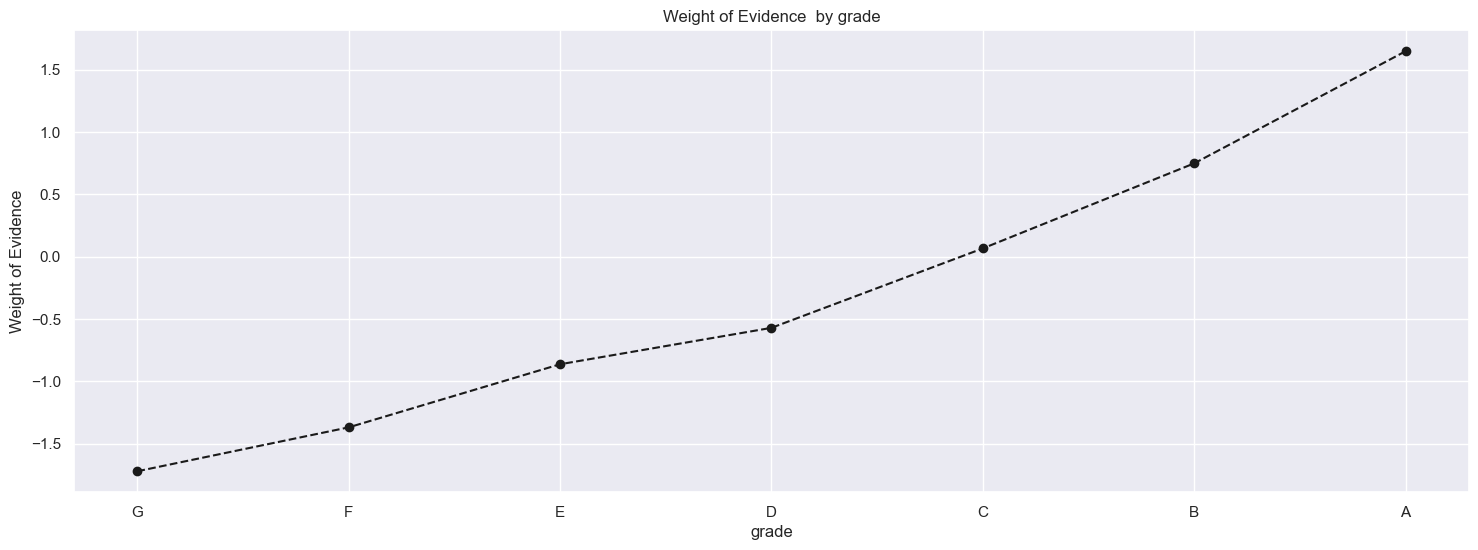

In [109]:
#Now by calling plot_by_woe on any dataframe with results from weight of eveidence calculations , we should get a visualisation 
# of the woe by the categories of the independent variable 

plot_by_woe(df_temp)

In [110]:
import numpy as np
import pandas as pd

**Data Preparation:**          Preprocessing Discrete Variables .. creating dummies
cslculate and visualise weight of evidnce for all selected discrete variablesand probability of default model based on weight of evidence 

Based on WoE we must decide how to organise the original categories of the discrete variables into dummy variables  for the PD model.
we have so far done Grade which reflects external credit ratings. Of all variables, its the one that should have very good patterns on weights of evidence. it is directy proportional to , meaning loans with greater external ratings are better on average , based on patterns of WoE

# When we put dummy variables inside a regression model we should keep one out as a reference category, the category against which the impact of all others wil be assessed e.g. a category with the worst credit risk as the reference category ie. the dummy that has or is composed of several categories
that have the lowest weight of evidence 



**Preprocessing Discrete Variables .. creating Dummy Variables, Part 1**

In [111]:
# Home Ownership Variable 
df_temp = woe_discrete(df_inputs_prepr, 'home_ownership', df_targets_prepr)
df_temp.head()


,home_ownership,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,average_WoE,IV
0,RENT,167644,0.976933,0.398115,163777.0,3867.0,0.396321,0.492549,-0.217368,0.398115,NaN,NaN,inf,inf
1,OWN,45766,0.980750,0.108684,44885.0,881.0,0.108616,0.112215,-0.032594,0.108684,0.003817,0.184775,inf,inf
2,MORTGAGE,207682,0.985059,0.493196,204579.0,3103.0,0.495057,0.395236,0.225190,0.493196,0.004309,0.257784,inf,inf
3,ANY,2,1.000000,0.000005,2.0,0.0,0.000005,0.000000,inf,0.000005,0.014941,inf,inf,inf


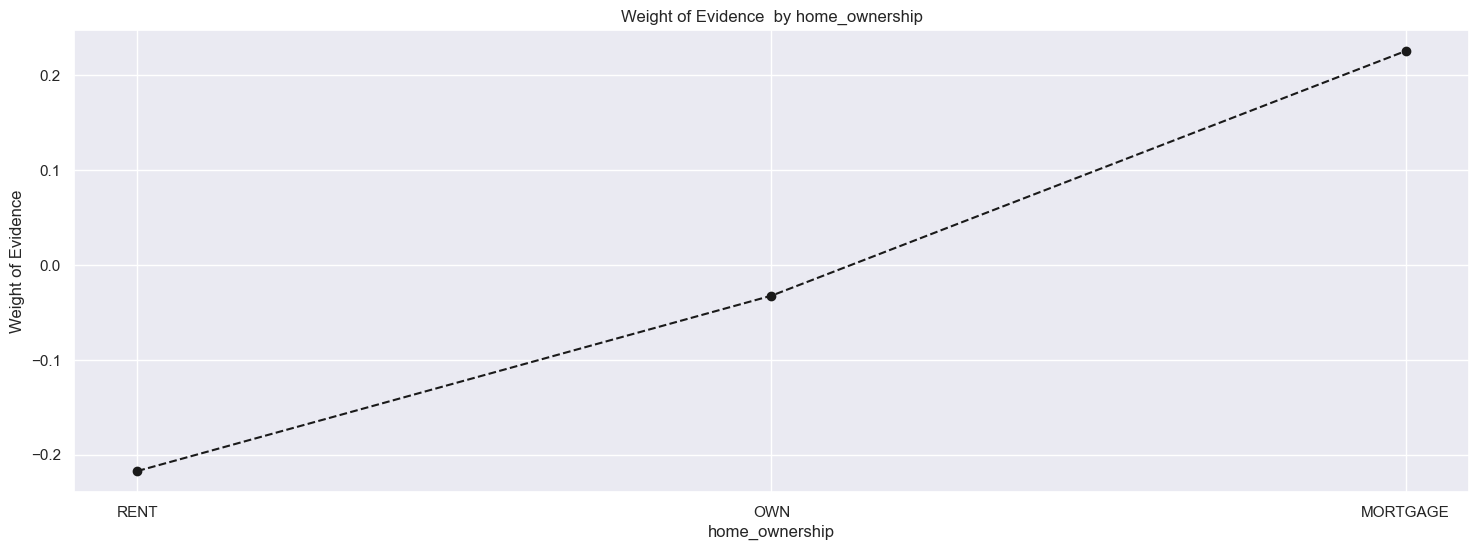

In [112]:
plot_by_woe(df_temp)

In [113]:
''' Other and NOne associated with highest probability of default from graph, however its important to look into their proportion to 
the total number of observations in the loan dataset.

in ours very few are associated with None and Other for these categories ess than 0.1% for each , 
woe couldnt be calculated there is only one observation with ANY home ownership status 

hence doesnt make sense to have dummy variables for thes categories, but we wouldnt want to remove them either because that would imply losing info about
these customers. In these cases, we combine such underrepresented categories that are similar to them. This is extrememly important preprocessing step.

We combine them with the riskiest category with enough number of observations. e.g. Any, Other and None are combined to  Rent 

Borrowers with category own have a considerably higher weight of evidence than those of rent, these will be in 2 differnt dummy variables 

Mortgage encompasses almost half of all the borrowers hence it will be in a separate dummy variable 

Hence, for home_ownership we will have one dummy for other, any, none and rent, a separate dummy variable for category own and one dummy for category
mortgage

#### ***We have already created dummy variables for the original categories of all discrete variables in the lecture we we preprocessed the
discrete variables so we can easily use them as independent variables for the PD model*** ###

'''

' Other and NOne associated with highest probability of default from graph, however its important to look into their proportion to \nthe total number of observations in the loan dataset.\n\nin ours very few are associated with None and Other for these categories ess than 0.1% for each , \nwoe couldnt be calculated there is only one observation with ANY home ownership status \n\nhence doesnt make sense to have dummy variables for thes categories, but we wouldnt want to remove them either because that would imply losing info about\nthese customers. In these cases, we combine such underrepresented categories that are similar to them. This is extrememly important preprocessing step.\n\nWe combine them with the riskiest category with enough number of observations. e.g. Any, Other and None are combined to  Rent \n\nBorrowers with category own have a considerably higher weight of evidence than those of rent, these will be in 2 differnt dummy variables \n\nMortgage encompasses almost half of a

In [114]:
pd.options.display.max_rows = None
pd.options.display.max_columns = None
df_inputs_prepr.columns.values


array(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade',
       'emp_title', 'emp_length', 'home_ownership', 'annual_inc',
       'verification_status', 'issue_d', 'loan_status', 'pymnt_plan',
       'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti',
       'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths',
       'mths_since_last_delinq', 'mths_since_last_record', 'open_acc',
       'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt',
       'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int',
       'total_rec_late_fee', 'recoveries', 'collection_recovery_fee',
       'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d',
       'last_credit_pull_d', 'collections_12_mths_ex_med',
       'mths_since_last_major_derog', 'policy_code', 'application_type',
       'annual_inc_joint', 'dti_joint', 'verification_status_joint

In [115]:
''' >>> from above   df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] lets see what the unique available homeownership are'''

loan_data['home_ownership'].unique() 

# OTHER and NONE are missing. From a business perspective this is strange and may indicate population change per se
# but since it is other and none we could assume bank has better practices in place so homeownership status is always recorded 
# Since we won't be modelling we only want to assess the population change , we can simply ignore this, the easiest way is to use only existing categories 
#used to create the combined dummy variable  ie remove the non existing in the sum 

array(['MORTGAGE', 'RENT', 'OWN', 'ANY'], dtype=object)

In [116]:
# Since we won't be modelling we only want to assess the population change , we can simply ignore this, the easiest way is to use only existing categories 
#used to create the combined dummy variable  ie remove the non existing in the sum 

'''
🔎 PART 1 — Why sum(df[['col1','col2']]) Is Wrong

You wrote:

df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] =
    sum(df_inputs_prepr[['home_ownership:RENT','home_ownership:ANY']])

You thought:
“sum() is a Python method, so why doesn’t it work?”

Because Python’s sum() does NOT understand rows.

🧠 What Python’s sum() Actually Does

Python’s built-in sum() works like this:

sum(iterable, start=0)

It loops like:

total = start
for item in iterable:
    total = total + item
return total

Now ask yourself:

What is this?

df_inputs_prepr[['home_ownership:RENT','home_ownership:ANY']]

It is a DataFrame.

When you pass a DataFrame into sum():

sum(df[['col1','col2']])

Python treats the DataFrame as an iterable of column names.

Yes.

It iterates over:

'home_ownership:RENT'
'home_ownership:ANY'

So Python tries to compute:

0 + 'home_ownership:RENT'

Which makes no sense.

That’s why built-in sum() is not for DataFrames.

✅ Correct Way Using Pandas .sum()

If you want row-wise summation:

df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] = \
    df_inputs_prepr[['home_ownership:RENT','home_ownership:ANY']].sum(axis=1)

Important:

.sum() here is a pandas DataFrame method

axis=1 means sum horizontally (row-wise)

Result = Series

That can be assigned to one column
'''

df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] = \
    df_inputs_prepr[['home_ownership:RENT','home_ownership:ANY']].sum(axis=1)

df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'].sample(3)

391260    1
257960    1
360209    1
Name: home_ownership:::RENT_OTHER_NONE_ANY, dtype: int64

In [117]:
#💥 If You INSIST on Using Python sum(), You must pass a list of Series, not a DataFrame Correct syntax:

'''
Why does this work?

Because now Python is doing:

Series + Series

Pandas overloads + to mean element-wise addition.

So Python’s sum() becomes:

Series1 + Series2

Which produces a Series.

That’s valid.

But this only works if all columns exist.

If one is missing → KeyError.

That’s the real weakness.'''





df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] = \
    sum([
        df_inputs_prepr['home_ownership:RENT'],
        df_inputs_prepr['home_ownership:ANY']
    ])

In [118]:
target_levels = ['RENT','OTHER','NONE','ANY']

available_cols = [
    col for col in df_inputs_prepr.columns
    if col.startswith('home_ownership:')
    and col.split(':')[1] in target_levels
]

df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] = \
    df_inputs_prepr[available_cols].sum(axis=1)

In [119]:
exclude_levels = ['OWN','MORTGAGE']

available_cols = [
    col for col in df_inputs_prepr.columns
    if col.startswith('home_ownership:')
    and col.split(':')[1] not in exclude_levels
]

df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] = \
    df_inputs_prepr[available_cols].sum(axis=1)

In [120]:
def create_grouped_dummy(
    df,
    new_column_name,
    component_columns,
    enforce_binary=True,
    verbose=True
):
    """
    Safely create a grouped dummy variable using a fixed schema.

    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe.

    new_column_name : str
        Name of grouped dummy to create.

    component_columns : list of str
        List of dummy columns that should be summed.

    enforce_binary : bool (default=True)
        If True, caps result at 1 to ensure binary output.

    verbose : bool (default=True)
        If True, prints missing column warnings.

    Returns
    -------
    pd.DataFrame
        Updated dataframe with grouped dummy.
    """

    missing_cols = []

    # Ensure all component columns exist
    for col in component_columns:
        if col not in df.columns:
            df[col] = 0
            missing_cols.append(col)

    if verbose and missing_cols:
        print(f"Warning: Created missing columns with zeros: {missing_cols}")

    # Sum safely
    df[new_column_name] = df[component_columns].sum(axis=1)

    # Enforce binary if requested
    if enforce_binary:
        df[new_column_name] = (df[new_column_name] > 0).astype(int)

    return df






df_inputs_prepr = create_grouped_dummy(
    df=df_inputs_prepr,
    new_column_name='home_ownership:::RENT_OTHER_NONE_ANY',
    component_columns=[
        'home_ownership:RENT',
        'home_ownership:OTHER',
        'home_ownership:NONE',
        'home_ownership:ANY'
    ]
)

In [121]:
# 🔥 If You Want Zero Hardcoding Across All Variables. If you want something scalable for all dummy groupings without repeatedly listing full expected columns, then use prefix logic.


def create_group_from_prefix(
    df,
    new_column_name,
    prefix,
    include_levels=None,
    exclude_levels=None,
    enforce_binary=True
):
    """
    Automatically groups dummy variables by prefix.
    """

    candidate_cols = [
        col for col in df.columns
        if col.startswith(prefix)
    ]

    if include_levels is not None:
        candidate_cols = [
            col for col in candidate_cols
            if col.split(':')[1] in include_levels
        ]

    if exclude_levels is not None:
        candidate_cols = [
            col for col in candidate_cols
            if col.split(':')[1] not in exclude_levels
        ]

    if len(candidate_cols) == 0:
        df[new_column_name] = 0
        return df

    df[new_column_name] = df[candidate_cols].sum(axis=1)

    if enforce_binary:
        df[new_column_name] = (df[new_column_name] > 0).astype(int)

    return df

df_inputs_prepr = create_group_from_prefix(
    df=df_inputs_prepr,
    new_column_name='home_ownership:::RENT_OTHER_NONE_ANY',
    prefix='home_ownership:',
    include_levels=['RENT','OTHER','NONE','ANY']
)

In [122]:
# alternatively 
'''
Make the Transformation Schema Fixed (Production-Safe Way)
What you do

Before creating the grouped dummy, ensure all expected dummy columns exist.

If a column is missing → create it and fill with zeros.

Conceptually:

“Even if a category does not appear in this dataset, we assume its frequency is zero.”

This keeps the feature space consistent across:

Training

Validation

Out-of-time

Production

Why this is strong

In credit scoring, your model was trained with a fixed set of variables.

If production data comes without some categories:

That does NOT mean the model structure should change.

It means frequency = 0.

Changing the feature structure post-training = catastrophic model governance violation.

Why this is the safest

It guarantees:

No KeyError

No column mismatch

No silent coefficient shifting

No PSI distortions due to column disappearance

When this is correct

If:

The model was trained when those categories existed

You are scoring new data

You want structural stability

When this is wrong

If:

You are retraining a model from scratch

Those categories genuinely no longer exist in the business process

The data generation mechanism changed permanently

Then you're freezing legacy noise into the system.'''






expected_cols = [
    'home_ownership:RENT',
    'home_ownership:OTHER',
    'home_ownership:NONE',
    'home_ownership:ANY'
]

# Ensure all expected dummy columns exist
for col in expected_cols:
    if col not in df_inputs_prepr.columns:
        df_inputs_prepr[col] = 0

# Now create grouped dummy safely
df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] = (
    df_inputs_prepr[expected_cols].sum(axis=1)
)

In [123]:

df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] =  np.sum([df_inputs_prepr['home_ownership:RENT'], 
                                                        df_inputs_prepr['home_ownership:OTHER'], 
                                                        df_inputs_prepr['home_ownership:NONE'], 
                                                        df_inputs_prepr['home_ownership:ANY']] , axis=0)

In [124]:
df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] =  np.sum(df_inputs_prepr[['home_ownership:RENT', 'home_ownership:OTHER', 'home_ownership:NONE',
                     'home_ownership:ANY']] , axis=0) 

In [125]:
df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] = (
    df_inputs_prepr[['home_ownership:RENT',
                     'home_ownership:OTHER',
                     'home_ownership:NONE',
                     'home_ownership:ANY']].sum(axis=1)
)

In [126]:
df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'].head()

0    0
1    0
2    1
3    1
4    0
Name: home_ownership:::RENT_OTHER_NONE_ANY, dtype: object

**Data Preparation. Preprocessing Discrete Variables; Creating Dummy Variables, part 2**

In [127]:
sorted(df_inputs_prepr.columns.values)

['acc_now_delinq',
 'addr_state',
 'addr_state:AK',
 'addr_state:AL',
 'addr_state:AR',
 'addr_state:AZ',
 'addr_state:CA',
 'addr_state:CO',
 'addr_state:CT',
 'addr_state:DC',
 'addr_state:DE',
 'addr_state:FL',
 'addr_state:GA',
 'addr_state:HI',
 'addr_state:IL',
 'addr_state:IN',
 'addr_state:KS',
 'addr_state:KY',
 'addr_state:LA',
 'addr_state:MA',
 'addr_state:MD',
 'addr_state:ME',
 'addr_state:MI',
 'addr_state:MN',
 'addr_state:MO',
 'addr_state:MS',
 'addr_state:MT',
 'addr_state:NC',
 'addr_state:ND',
 'addr_state:NE',
 'addr_state:NH',
 'addr_state:NJ',
 'addr_state:NM',
 'addr_state:NV',
 'addr_state:NY',
 'addr_state:OH',
 'addr_state:OK',
 'addr_state:OR',
 'addr_state:PA',
 'addr_state:RI',
 'addr_state:SC',
 'addr_state:SD',
 'addr_state:TN',
 'addr_state:TX',
 'addr_state:UT',
 'addr_state:VA',
 'addr_state:VT',
 'addr_state:WA',
 'addr_state:WI',
 'addr_state:WV',
 'addr_state:WY',
 'all_util',
 'annual_inc',
 'annual_inc_joint',
 'application_type',
 'collection_r

In [128]:
# df_inputs_prepr.loc[:, ~df_inputs_prepr.columns.duplicated()].columns.values
# Duplicated were removed in loan_data.loc[:, ~loan_data.columns.duplicated()].columns.values

df_inputs_prepr.loc[:, df_inputs_prepr.columns.duplicated()].columns


Index([], dtype='object')

In [129]:
# df_inputs_prepr.loc[:, ~df_inputs_prepr.columns.duplicated()].columns.values
# Duplicated were removed in loan_data.loc[:, ~loan_data.columns.duplicated()].columns.values

df_inputs_prepr.loc[:, df_inputs_prepr.columns.duplicated()].columns.values


array([], dtype=object)

**Part 1 — Your confusion is valid**

You said:

I thought once we reassign, the variable takes the new values.

That is normally true.
But pandas has a special dangerous case where it is not always clear whether you are modifying the real table or a temporary copy.

Let’s see this with a tiny real example


**🍎 Tiny dataframe example**

import pandas as pd

data = pd.DataFrame({
    'A': [1, 2, 3],
    'B': [10, None, 30]
})

data


Looks like:

	A	B
0	1	10
1	2	NaN
2	3	30
Case 1 — Safe assignment
data['B'] = data['B'].fillna(999)


Result:

	A	B
0	1	10
1	2	999
2	3	30

Everything works. No warning. All good.

Now the dangerous case (this is where your confusion starts)
subset = data[data['A'] > 1]


Now subset looks like:

	A	B
1	2	NaN
2	3	30

Now try this:

subset['B'].fillna(999, inplace=True)


Pandas now warns:

SettingWithCopyWarning

Why?

Because subset might be:

a real independent table
or

just a window into data

Pandas literally does not know which.

So when you modify it, it says:

“I’m not sure if you’re modifying the real thing or a temporary thing.”

That’s the warning.

Why .loc fixes it

When you write:

subset.loc[:, 'B'] = subset['B'].fillna(999)


You are telling pandas very clearly:

Modify column B inside this object directly.

No ambiguity. No confusion. No warning.

Now your exact question:

What is the difference between these two?

This:
loan_data['total_rev_hi_lim'] = ...

And this:
loan_data.loc[:, 'total_rev_hi_lim'] = ...


In a clean DataFrame, both usually work.

But when loan_data was created like this:

loan_data = big_df[big_df['grade'] == 'A']


Then this:

loan_data['col'] = ...


can silently fail or partially work.

While this:

loan_data.loc[:, 'col'] = ...


always works correctly.

So the rule I want you to follow forever is simple:

If you are assigning values → always use .loc

It’s not because you’re wrong.
It’s because pandas itself is inconsistent in edge cases.

In [130]:
df_inputs_prepr['addr_state'].unique()

array(['DC', 'IN', 'KS', 'IL', 'OR', 'VA', 'PA', 'GA', 'TN', 'OH', 'NY',
       'FL', 'NJ', 'RI', 'NC', 'AL', 'TX', 'SC', 'MD', 'WA', 'MO', 'MN',
       'NH', 'VT', 'AZ', 'MI', 'MA', 'CA', 'LA', 'DE', 'NM', 'CO', 'WI',
       'SD', 'CT', 'NE', 'HI', 'AR', 'MT', 'WV', 'WY', 'OK', 'NV', 'KY',
       'MS', 'ME', 'UT', 'ND', 'AK'], dtype=object)

In [131]:
def woe_discrete(df, discrete_variable_name, good_bad_variable_df):

    df = pd.concat([df[discrete_variable_name], good_bad_variable_df], axis = 1) 
    
    df = pd.concat([
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)
    ], axis=1)

    df = df.iloc[:, [0,1,3]]
    df.columns = [df.columns.values[0], 'n_obs', 'prop_good']

    df['av_prop_good']=df['prop_good'].mean()
    

    df['prop_n_obs'] = df['n_obs'] / df['n_obs'].sum()
    
    df['n_good'] = df['prop_good'] * df['n_obs']
    df['n_bad'] = (1 - df['prop_good']) * df['n_obs']
    
    
    df['prop_n_good'] = df['n_good'] / df['n_good'].sum()
    df['prop_n_bad'] = df['n_bad'] / df['n_bad'].sum()


    df['WoE'] = np.log(df['prop_n_good']/df['prop_n_bad'])
    df = df.sort_values(['WoE'])
    df = df.reset_index(drop = True)

    df['n_obs%'] = df['n_obs'] / df['n_obs'].sum()
    
    df['diff_prop_good'] = df['prop_good'].diff().abs()
    df['diff_WoE']= df['WoE'].diff().abs()

    '''df['average_WoE']= df['WoE'].fillna(0)
    df['average_WoE']= np.where(df['WoE']> 0.559486, 0 , df['WoE']) 
    df['average_WoE']= df['average_WoE'].sum() / 50'''

     
    
    df['IV'] = (df['prop_n_good'] -df['prop_n_bad'])* df['WoE']
    df['IV'] = df['IV'].sum()   
    return df

df_temp = woe_discrete(df_inputs_prepr, 'addr_state', df_targets_prepr)
df_temp.head()

,addr_state,n_obs,prop_good,av_prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,NV,5924,0.969953,0.982722,0.014068,5746.0,178.0,0.013905,0.022672,-0.488919,0.014068,NaN,NaN,inf
1,SD,835,0.970060,0.982722,0.001983,810.0,25.0,0.001960,0.003184,-0.485236,0.001983,0.000107,0.003683,inf
2,HI,2083,0.973596,0.982722,0.004947,2028.0,55.0,0.004908,0.007005,-0.355923,0.004947,0.003536,0.129314,inf
3,OK,3968,0.976310,0.982722,0.009423,3874.0,94.0,0.009375,0.011973,-0.244647,0.009423,0.002715,0.111276,inf
4,AK,954,0.977987,0.982722,0.002266,933.0,21.0,0.002258,0.002675,-0.169512,0.002266,0.001677,0.075135,inf


In [132]:
len(df_temp) # There are now 49 which is different from our original preprocessing that had 51 the 2 missing are Idaho and Iowa, in testing it was only ND  missing

49

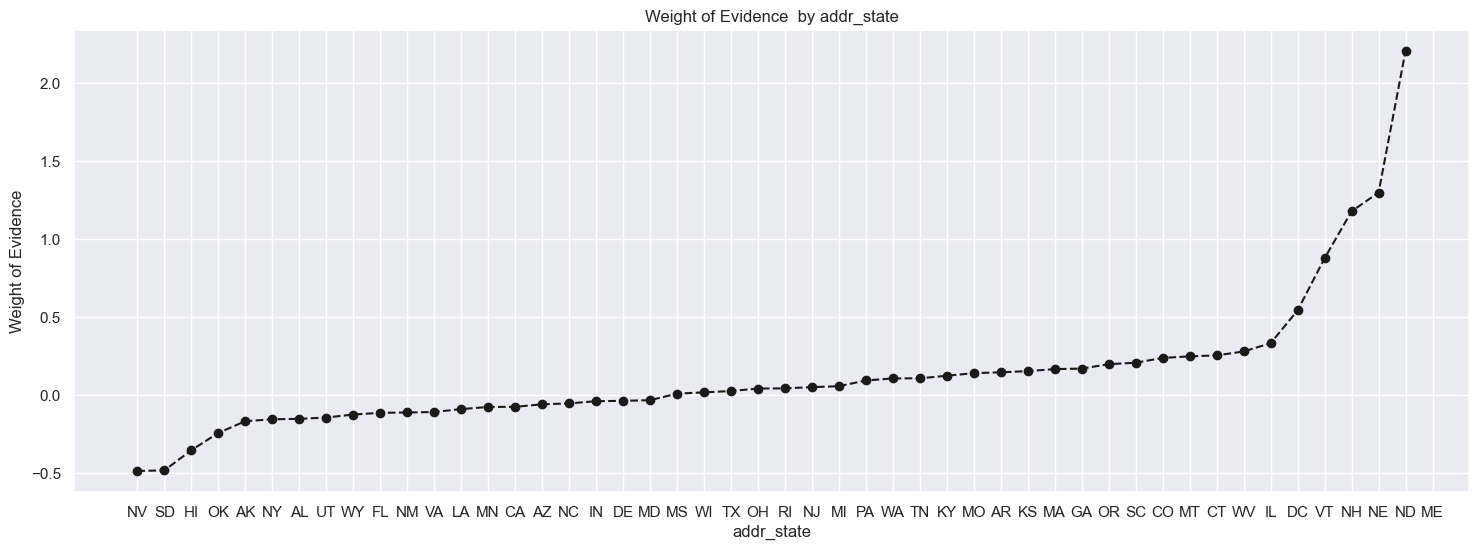

In [133]:
plot_by_woe(df_temp)

In [134]:
df_inputs_prepr.columns.values

array(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade',
       'emp_title', 'emp_length', 'home_ownership', 'annual_inc',
       'verification_status', 'issue_d', 'loan_status', 'pymnt_plan',
       'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti',
       'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths',
       'mths_since_last_delinq', 'mths_since_last_record', 'open_acc',
       'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt',
       'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int',
       'total_rec_late_fee', 'recoveries', 'collection_recovery_fee',
       'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d',
       'last_credit_pull_d', 'collections_12_mths_ex_med',
       'mths_since_last_major_derog', 'policy_code', 'application_type',
       'annual_inc_joint', 'dti_joint', 'verification_status_joint

In [135]:
# There is a state missing i.e North Dakota, meaning there are no borrowers from there
''' Keeping it in mind, so that we can add this this state to a category later, just in case there are some borrowers in the future.
Lets create a dummmy variable for ND

'''

'''
if ['addr_state:ND'] in df_inputs_prepr.columns.values:
    pass
else:
    df_inputs_prepr['addr_state:ND'] = 0
'''

if 'addr_state:ND' in df_inputs_prepr.columns.values:
    pass
else:
    df_inputs_prepr.loc[:,'addr_state:ND'] = 0


In [136]:
''' woe of last states could not be calculated because there are no bad borrowers, add these 2 , ND , 2 states have considerably higher woe.
the rest of 46 states appear to have similar woe  values. The first 2 and last 2 have very few observations, Low obs prob responsible for extreme woe

So we include these states in the first, the worst and the last, the best categories respectively. '''


' woe of last states could not be calculated because there are no bad borrowers, add these 2 , ND , 2 states have considerably higher woe.\nthe rest of 46 states appear to have similar woe  values. The first 2 and last 2 have very few observations, Low obs prob responsible for extreme woe\n\nSo we include these states in the first, the worst and the last, the best categories respectively. '

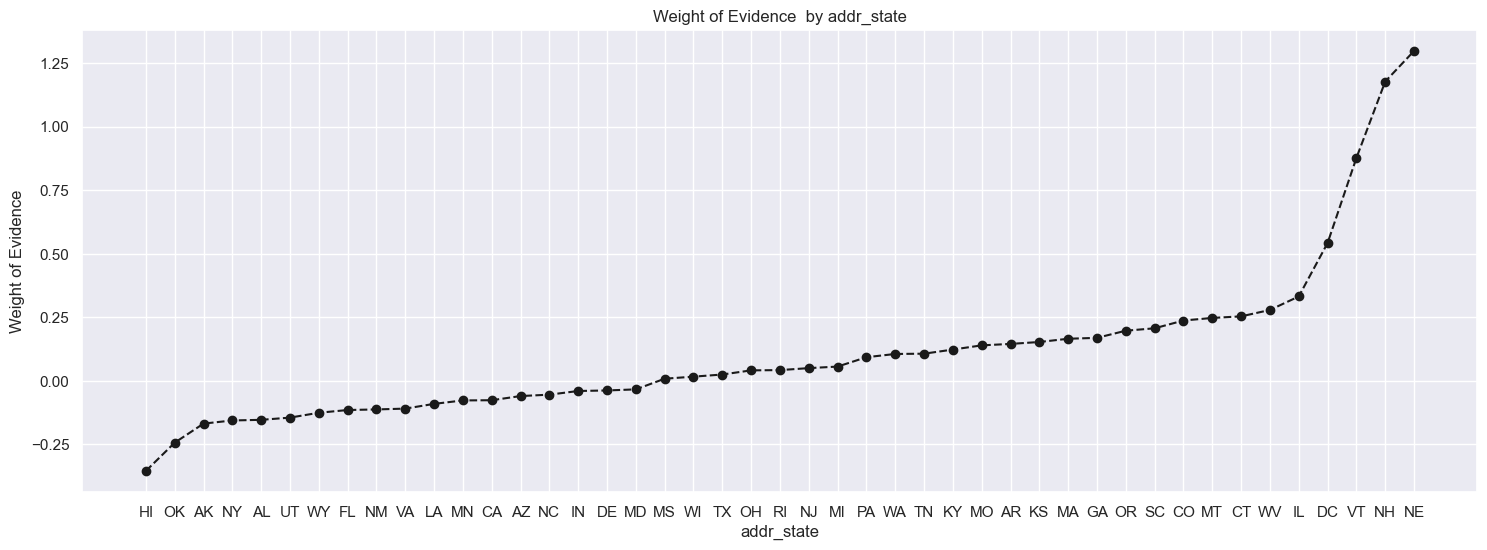

In [137]:
#Focus on 46 states

plot_by_woe(df_temp.iloc[2:-2, :])

# Above shows we were misled by first graph because of extreme values we were thinking that all were similar but now we see the aint
''' might make sense to keep NV in own category then next 3 states in another. but from table NV has very few obs of borrowers. But the next 
3 states, FL has enough obs that make it suitable for both keeping it in a separate category or putting it in one category with the other states
Therefore lets combine NV with the 3 states . Also  remember the first 2 states we left out NE and IA  and put them in this first category.

Since the first category includes the states with the highest credit risk borrowers , it makes sense to include a state we have no info about here to. 
Hence **(NE, IA, NV, FL should include ND here too). This reflects our conservative risk management attitude by default as risk managers when we have no 
info we should assume the worst and highest risk. Lets make our first dummy to include first **6 NE, IA, ND, NV, FL, HI,AL**

 The last 4 states displayed on the chart can be grouped together in one category based on their rather low number of observations. 
 Remember to include the other 2 states we didnt display at the end of the scale . **Last category will be WV, NH, WY, DC,ME,ID**
'''

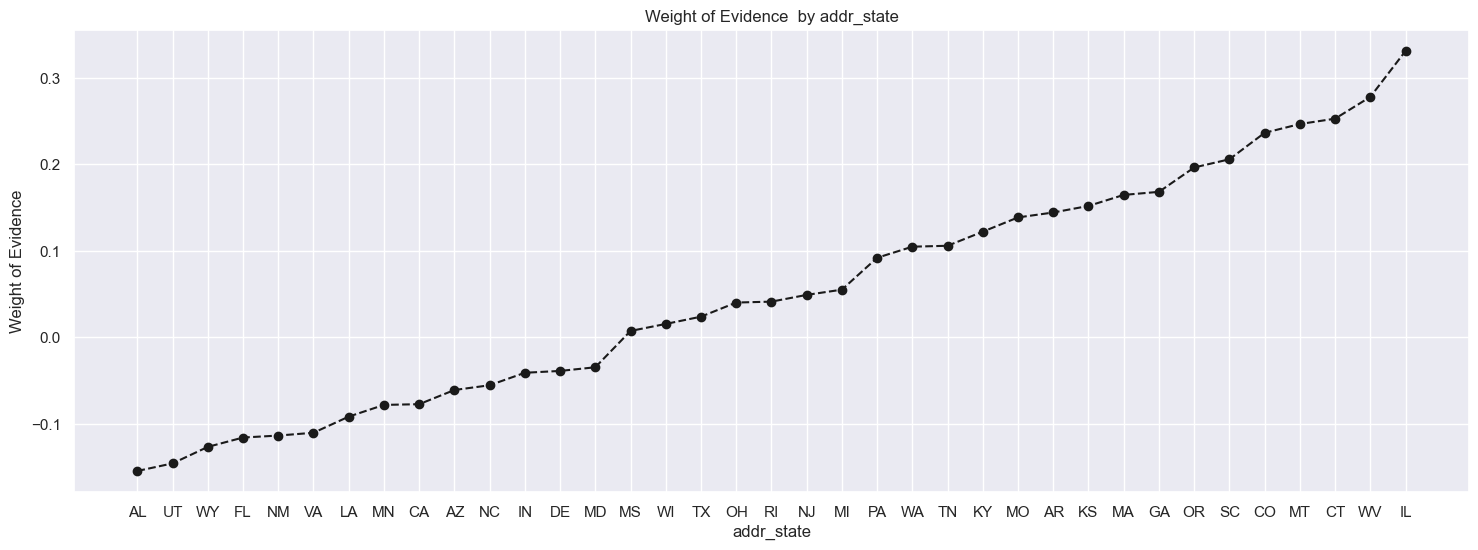

In [138]:
#lets look at remaining  38 states

plot_by_woe(df_temp.iloc[6:-6, :])

''' **Creating Category for states with lowest weight of evidence** 
NM to CA have similar WoE, but we also need to take into account the number of observations

1. NY and CA have particularly many  borrowers in this group. Worse with California, so CA definitely has to be in a different Dummy Variable by itself
   
2. Same to NY, that means the rest of the states can either all be in one group or several depending on the increase in WOE

3. So lets define them as follows: **3 categories (NM, VA), (OK, TN, MO, LA, MD, NC) And (CA)**

IT would not be right to combine NM, VA,  with OK,TN, etc because nearly 10% of observations are from NY. NY kinda breaks the link btn VA n OK

4. States from **(UT to NJ)** have similar woe.Check no. of borrowers, none stands out with a particularly high number more than twice >3 times the neighbour

5. ***AR to MN***

6. **RI to IN**

7. GA to OR
8. WI AND MT are a bit apart in terms of woe  but have a rather low number of obs so we can put them in one group
9. TX to CT have similar woe but TX has a relatively high number of obs 3rd highest. Hence leave TX alone

10. IL and CT

11. KS to mS have considerably higher than CT. At same time no. of obs per state for all these states is low. makes woe less reliable, even though

    it isindicative that borrows from these states are better than from other states. So we group them into our final dummy variable


    Now lets create actual dummy variables and leave one assigned as a reference variable (lowest woe) i regression model.ie: Iowa, ND, HI,ID,AL and FL.






In [139]:
df_temp = woe_discrete(df_inputs_prepr, 'addr_state', df_targets_prepr)
df_temp.iloc[6:-6, :].head()

,addr_state,n_obs,prop_good,av_prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
6,AL,5347,0.978306,0.982722,0.012698,5231.0,116.0,0.012658,0.014775,-0.154627,0.012698,0.000052,0.002467,inf
7,UT,2836,0.978491,0.982722,0.006735,2775.0,61.0,0.006715,0.007770,-0.145863,0.006735,0.000185,0.008765,inf
8,WY,900,0.978889,0.982722,0.002137,881.0,19.0,0.002132,0.002420,-0.126776,0.002137,0.000398,0.019086,inf
9,FL,29298,0.979111,0.982722,0.069576,28686.0,612.0,0.069417,0.077952,-0.115963,0.069576,0.000222,0.010814,inf
10,NM,2351,0.979158,0.982722,0.005583,2302.0,49.0,0.005571,0.006241,-0.113682,0.005583,0.000047,0.002281,inf


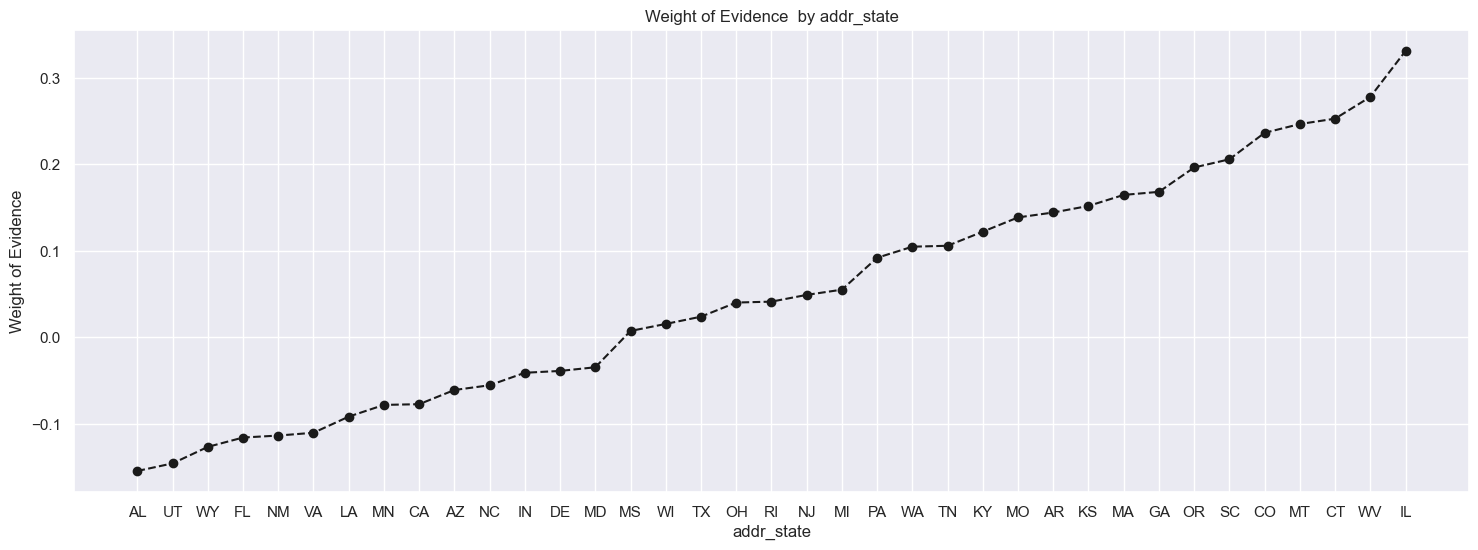

In [140]:

plot_by_woe(df_temp.iloc[6:-6, :])

We already have dummy variables for all states . So for Categories with one state we can use these dummy variables and 
dont have to create new ones 

for categories for 2 or more states, we use approach similar to the one we used for homeownership ie. sum the dummy variables for every state that is 
part of a bigger state and this will result in a dummy variable for the whole category



In [141]:
'''df_inputs_prepr['addr_state:::ND_NE_IA_NV_FL_HI_AL'] = sum(pd.to_numeric([df_inputs_prepr['addr_state:ND'], df_inputs_prepr['addr_state:NE'], 
                                                          df_inputs_prepr['addr_state:IA'], df_inputs_prepr['addr_state:NV'], 
                                                          df_inputs_prepr['addr_state:FL'], df_inputs_prepr['addr_state:HI'],
                                                          df_inputs_prepr['addr_state:AL']
                                                         ])
                                                        ) 
  df_inputs_prepr['addr_state:::UT_KY_AZ_NJ'] = (
    [df_inputs_prepr['addr_state:UT'],  df_inputs_prepr['addr_state:KY'],  df_inputs_prepr['addr_state:AZ'],  df_inputs_prepr['addr_state:NJ']]
    .sum(axis=1)      # AttributeError: 'list' object has no attribute 'sum'
)
df_inputs_prepr['addr_state:::UT_KY_AZ_NJ']                                           
                                                        
                                                        '''





"df_inputs_prepr['addr_state:::ND_NE_IA_NV_FL_HI_AL'] = sum(pd.to_numeric([df_inputs_prepr['addr_state:ND'], df_inputs_prepr['addr_state:NE'], \n                                                          df_inputs_prepr['addr_state:IA'], df_inputs_prepr['addr_state:NV'], \n                                                          df_inputs_prepr['addr_state:FL'], df_inputs_prepr['addr_state:HI'],\n                                                          df_inputs_prepr['addr_state:AL']\n                                                         ])\n                                                        ) \n  df_inputs_prepr['addr_state:::UT_KY_AZ_NJ'] = (\n    [df_inputs_prepr['addr_state:UT'],  df_inputs_prepr['addr_state:KY'],  df_inputs_prepr['addr_state:AZ'],  df_inputs_prepr['addr_state:NJ']]\n    .sum(axis=1)      # AttributeError: 'list' object has no attribute 'sum'\n)\ndf_inputs_prepr['addr_state:::UT_KY_AZ_NJ']                                           \n                      

In [142]:
print(df_inputs_prepr.filter(like="addr_state:::").dtypes.head(10))


Series([], dtype: object)


In [143]:
df_inputs_prepr['addr_state:::NM_VA'] = sum([df_inputs_prepr['addr_state:NM'], df_inputs_prepr['addr_state:VA']])

if 'addr_state:IA' not in df_inputs_prepr.columns:
        df_inputs_prepr['addr_state:IA'] = 0
# or
#if ['addr_state:IA'] in df_inputs_prepr.columns:
#        pass
#else:
#    df_inputs_prepr['addr_state:IA'] = 0

df_inputs_prepr['addr_state:::ND_NE_IA_NV_FL_HI_AL'] = sum([pd.to_numeric(df_inputs_prepr['addr_state:ND']), 
                pd.to_numeric(df_inputs_prepr['addr_state:NE']), pd.to_numeric(df_inputs_prepr['addr_state:IA']), 
                pd.to_numeric(df_inputs_prepr['addr_state:NV']), pd.to_numeric(df_inputs_prepr['addr_state:FL']), 
                pd.to_numeric(df_inputs_prepr['addr_state:HI']), pd.to_numeric(df_inputs_prepr['addr_state:AL'])])              

In [144]:
states = ['OK','TN','MO','LA','MD','NC']
cols = [f"addr_state:{s}" for s in states]

# Ensure all are numeric
df_inputs_prepr[cols] = df_inputs_prepr[cols].apply(pd.to_numeric, errors='coerce')

# Create grouped dummy
df_inputs_prepr['addr_state:::OK_TN_MO_LA_MD_NC'] = df_inputs_prepr[cols].sum(axis=1)


# ============================================================================================================
cols = ['addr_state:GA', 'addr_state:WA', 'addr_state:OR']

df_inputs_prepr['addr_state:::GA_WA_OR'] = sum(
    [df_inputs_prepr[c].astype(float) for c in cols]
)

In [145]:

df_inputs_prepr['addr_state:::UT_KY_AZ_NJ'] = (
    df_inputs_prepr[['addr_state:UT', 'addr_state:KY', 'addr_state:AZ', 'addr_state:NJ']]
    .sum(axis=1)      # row-wise sum
)


df_inputs_prepr['addr_state:::WI_MT'] = (
    df_inputs_prepr[['addr_state:WI', 'addr_state:MT']].astype(float).sum(axis=1)
)



In [146]:
df_inputs_prepr['addr_state:::AR_MI_PA_OH_MN'] = (
    df_inputs_prepr['addr_state:AR'] +  df_inputs_prepr['addr_state:MI'] +  df_inputs_prepr['addr_state:PA'] + df_inputs_prepr['addr_state:OH']
    +  df_inputs_prepr['addr_state:MN']    
   
)


df_inputs_prepr['addr_state:::RI_MA_DE_SD_IN'] = (
    df_inputs_prepr['addr_state:RI'].astype(float)
    .add(df_inputs_prepr['addr_state:MA'].astype(float))
    .add(df_inputs_prepr['addr_state:DE'].astype(float))
    .add(df_inputs_prepr['addr_state:SD'].astype(float))
    .add(df_inputs_prepr['addr_state:IN'].astype(float))
)



In [147]:
df_inputs_prepr['addr_state:::IL_CT'] = (
    df_inputs_prepr[['addr_state:IL',
                     'addr_state:CT'
                     ]].sum(axis=1)
)



df_inputs_prepr['addr_state:::KS_SC_CO_VT_AK_MS'] = (
    df_inputs_prepr['addr_state:KS']
    + df_inputs_prepr['addr_state:SC']
    + df_inputs_prepr['addr_state:CO']          
    + df_inputs_prepr['addr_state:VT']
    + df_inputs_prepr['addr_state:AK']
    + df_inputs_prepr['addr_state:MS']
)



if 'addr_state:ID' not in df_inputs_prepr.columns:
        df_inputs_prepr['addr_state:ID'] = 0
    
df_inputs_prepr['addr_state:::WV_NH_WY_DC_ME_ID'] = (
    df_inputs_prepr[['addr_state:WV',
                     'addr_state:NH',
                     'addr_state:WY',
                     'addr_state:ME',
                     'addr_state:ID']].any(axis=1)
)



What is any()? Who owns it? What does it do?

There are THREE different any() things in Python land.
They look the same, but they are NOT the same.

I’ll explain each like a story.

1️⃣ Python’s built-in any() (the simplest one)
Where it lives

➡️ Python itself
Not Pandas. Not NumPy.

What it eats

A list of True / False values

Example:

any([False, False, True])

How it thinks

Python asks, one by one:

Is the first thing True? ❌

Is the second thing True? ❌

Is the third thing True? ✅

As soon as it sees ONE True, it stops and returns:

True

Important

It works one list only

No rows

No columns

No tables

Slow for big data

This is NOT what you are using.

2️⃣ NumPy’s np.any()
Where it lives

➡️ NumPy

What it eats

A NumPy array (numbers or booleans)

Example:

np.any([[0, 0, 1],
        [0, 0, 0]], axis=1)

What it asks

For each row:

“Is there at least one non-zero value?”

Result:

[ True, False ]


Fast. But:

No column names

No safety

No labels

3️⃣ Pandas .any() ✅ (THIS is the one you are using)
Where it lives

➡️ Pandas

What it eats

A DataFrame (table with column names)

Example:

df[cols].any(axis=1)

How Pandas .any() works (very slowly)

Imagine one row:

RENT	OTHER	NONE	ANY
0	1	0	0

Pandas asks:

“In this row…
is at least one value not zero?”

Answer: YES

So the result for that row is:

True

Why .any(axis=1) is useful

axis=1 means: look across columns

.any() means: at least one is 1

So this creates a YES / NO flag.

Later, Pandas quietly converts:

True → 1

False → 0

⚠️ Very important: any() is NOT sum
Function	Meaning
.sum()	“How many 1s?”
.any()	“Is there at least one 1?”

Example row:

RENT	OTHER	NONE	ANY
1	1	0	0

.sum() → 2 ❌ (this reveals a data error)

.any() → True (hides the error)

So:

.sum() = count

.any() = existence check

**how to predict potential default, potential sales, when and who to upsell to**

# **HOMEWORK**

# ***PREPROCESSING CONTINUOUS VARIABLES:***

**Automating Calculations and Visualising Results**

* Discrete Variables dont show differences in terms of quantity; Exact order or discrete variables doesnt matter thats why we even ordered them by woe just to make it easier to group them
* They are just qualitatively different, e.g. purpose of one loan might be to finance education and another may be to buy a car , so cant be directly comparable
* **Continous have quantitative differnces, one values shows there is more of something than the other catgories of higher vs lower income 

In [148]:
def woe_ordered_continuous(df, discrete_variable_name, good_bad_variable_df):

# Assume a function takes a continuous variable, containing the categories of a continuous variable, obtained via fine classing
    df = pd.concat([df[discrete_variable_name], good_bad_variable_df], axis = 1) 
    
    df = pd.concat([
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)
    ], axis=1)

    df = df.iloc[:, [0,1,3]]
    df.columns = [df.columns.values[0], 'n_obs', 'prop_good']

    df['prop_n_obs'] = df['n_obs'] / df['n_obs'].sum()
    
    df['n_good'] = df['prop_good'] * df['n_obs']
    df['n_bad'] = (1 - df['prop_good']) * df['n_obs']
    
    df['prop_n_good'] = df['n_good'] / df['n_good'].sum()
    df['prop_n_bad'] = df['n_bad'] / df['n_bad'].sum()

    df['WoE'] = np.log(df['prop_n_good']/df['prop_n_bad'])
    
    # ======================= Differences start here, we dont want categories ordered by woe but to preserve natural order complient with ascending 
    # values of continuous variable =====================================
    
    # df = df.sort_values(['WoE'])
    # df = df.reset_index(drop = True)

    df['n_obs%'] = df['n_obs'] / df['n_obs'].sum()
    df['diff_prop_good'] = df['prop_good'].diff().abs()
    df['diff_WoE']= df['WoE'].diff().abs()

    df['IV'] = (df['prop_n_good'] -df['prop_n_bad'])* df['WoE']
    df['IV'] = df['IV'].sum()   
    return df

In [149]:
# OPTION 2 

def woe_discrete(df, discrete_variable_name, good_bad_variable_df):

    df = pd.concat([df[discrete_variable_name], good_bad_variable_df], axis=1)

    # df = pd.concat([
    #     df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
    #     df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)
    # ], axis=1)

    df = df.groupby(discrete_variable_name).agg(
        n_obs=(good_bad_variable_df.name, 'count'),
        prop_good=(good_bad_variable_df.name, 'mean')
    ).reset_index()

    # df = df.iloc[:, [0,1,3]]

    df.columns = [df.columns.values[0], 'n_obs', 'prop_good']

    df['av_prop_good'] = df['prop_good'].mean()

    df['prop_n_obs'] = df['n_obs'] / df['n_obs'].sum()

    df['n_good'] = df['prop_good'] * df['n_obs']
    df['n_bad'] = (1 - df['prop_good']) * df['n_obs']

    df['prop_n_good'] = df['n_good'] / df['n_good'].sum()
    df['prop_n_bad'] = df['n_bad'] / df['n_bad'].sum()

    df['WoE'] = np.log(df['prop_n_good'] / df['prop_n_bad'])
    df = df.sort_values(['WoE'])
    df = df.reset_index(drop=True)

    df['n_obs%'] = df['n_obs'] / df['n_obs'].sum()

    df['diff_prop_good'] = df['prop_good'].diff().abs()
    df['diff_WoE'] = df['WoE'].diff().abs()

    # df['average_WoE'] = df['WoE'].fillna(0)
    # df['average_WoE'] = np.where(df['WoE'] > 0.559486, 0, df['WoE']) 
    # df['average_WoE'] = df['average_WoE'].sum() / 50

    df['IV'] = (df['prop_n_good'] - df['prop_n_bad']) * df['WoE']
    df['IV'] = df['IV'].sum()

    return df


df_temp = woe_discrete(df_inputs_prepr, 'addr_state', df_targets_prepr)


# Assume loan_data has columns: 'grade' and 'good_bad' (1=good, 0=bad)

# 1) Group and aggregate in one pass (fast & tidy)
grp = loan_data.groupby('grade')['good_bad']
df1 = grp.agg(
    n_obs = 'size',      # counts
    n_good = 'sum',      # sum of 0/1 = count of goods
    prop_good = 'mean'   # mean of 0/1 = proportion of goods in group
).reset_index()

# 2) Derived columns
df1['n_bad'] = df1['n_obs'] - df1['n_good']

# 3) Shares across whole population
total_good = df1['n_good'].sum()
total_bad = df1['n_bad'].sum()

df1['prop_n_good'] = df1['n_good'] / total_good
df1['prop_n_bad']  = df1['n_bad']  / total_bad

# 4) WoE and IV parts
# protect against div-by-zero: replace 0 with a small value eps
eps = 1e-12
df1['prop_n_good_clipped'] = df1['prop_n_good'].replace(0, eps)
df1['prop_n_bad_clipped']  = df1['prop_n_bad'].replace(0, eps)

df1['WoE'] = np.log(df1['prop_n_good_clipped'] / df1['prop_n_bad_clipped'])
df1['IV_part'] = (df1['prop_n_good'] - df1['prop_n_bad']) * df1['WoE']
IV_total = df1['IV_part'].sum()

# drop intermediate clipped column if you want
df1 = df1.drop(columns=['prop_n_good_clipped', 'prop_n_bad_clipped'])
print("Total IV:", IV_total)

'''
Example insights
•	If diff_prop_good small but diff_WoE large ⇒ because prop_n_good/prop_n_bad magnify differences due to population shares. Investigate bin sizes and sample counts.
•	If diff_prop_good large but diff_WoE small ⇒ may be because group has small population (prop_n_small small), so impact on WoE small.
'''


# **Data Preperation: Preprocessing Continuous Variables: Creating Dummy Variables , Part 1**

In [150]:
sorted(loan_data.columns.values)
loan_data['term'].head()

0     60 months
1     36 months
2     36 months
3     60 months
4     60 months
Name: term, dtype: object

In [151]:
# Term of the loan in months


''' 
loan_data['term_int'] = (loan_data['term'].str.replace(r'\+ months', '',regex=True).str.replace('< 1 month', str(0))
                                  .str.replace('n/a', str(0))
                                  .str.replace(r"months?|[+]", "", regex=True)
                                    .fillna(0).replace(np.nan, 0)
                                                                           
                                 )

type(loan_data['term_int'][0])
print(type(loan_data['term_int'][0]))
loan_data['term_int'] = pd.to_numeric(loan_data['term_int'])
print(loan_data['term_int'])
type(loan_data['term_int'][0])
print(type(loan_data['term_int'][0]))
'''

df_inputs_prepr['term_int'] = (df_inputs_prepr['term'].str.replace(r'\+ months', '',regex=True).str.replace('< 1 month', str(0))
                                  .str.replace('n/a', str(0))
                                  .str.replace(r"months?|[+]", "", regex=True)
                                    .fillna(0).replace(np.nan, 0)
                                                                           
                                 )


print(type(df_inputs_prepr['term_int'].iloc[0]))
df_inputs_prepr['term_int'] = pd.to_numeric(df_inputs_prepr['term_int'])
print(df_inputs_prepr['term_int'].head())
type(df_inputs_prepr['term_int'].iloc[0])

<class 'str'>
0    60
1    36
2    36
3    60
4    60
Name: term_int, dtype: int64


numpy.int64

In [152]:
df_inputs_prepr['term_int'].unique() # Term of the loan in months

array([60, 36])

In [153]:
df_temp  = woe_ordered_continuous(df_inputs_prepr, 'term_int', df_targets_prepr)
df_temp.head() 

,term_int,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,36,283172,0.983533,0.672467,278509.0,4663.0,0.673959,0.593937,0.126396,0.672467,NaN,NaN,0.027678
1,60,137922,0.976885,0.327533,134734.0,3188.0,0.326041,0.406063,-0.219486,0.327533,0.006647,0.345883,0.027678


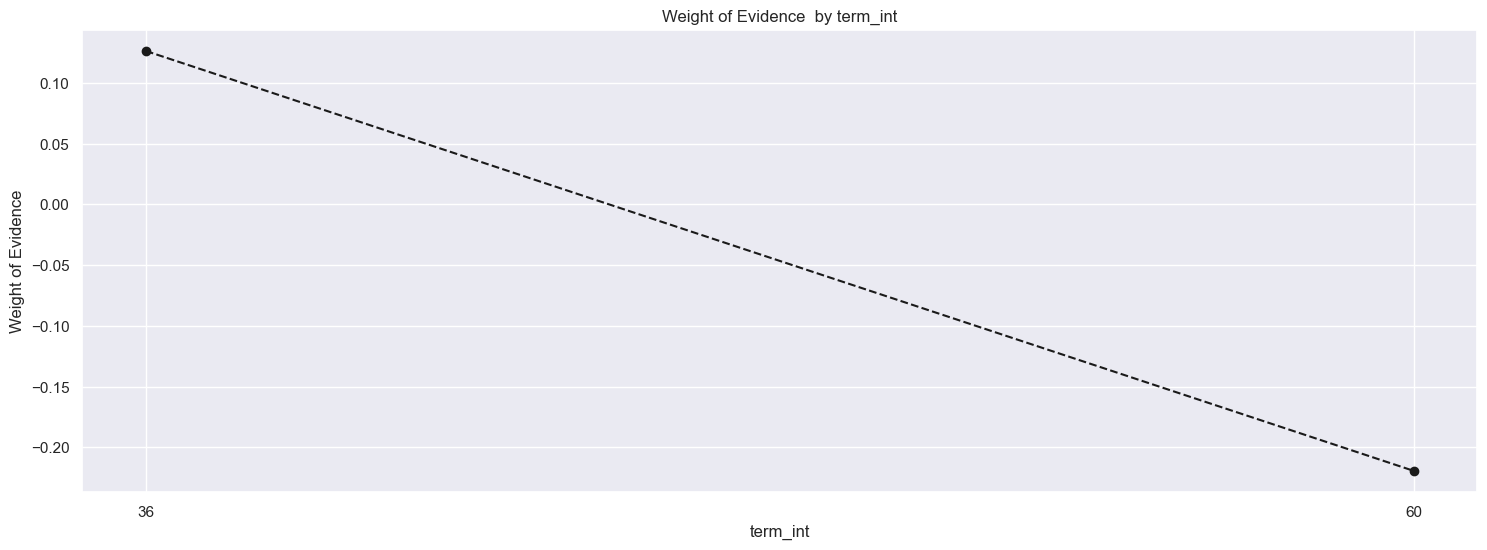

In [154]:
plot_by_woe(df_temp)

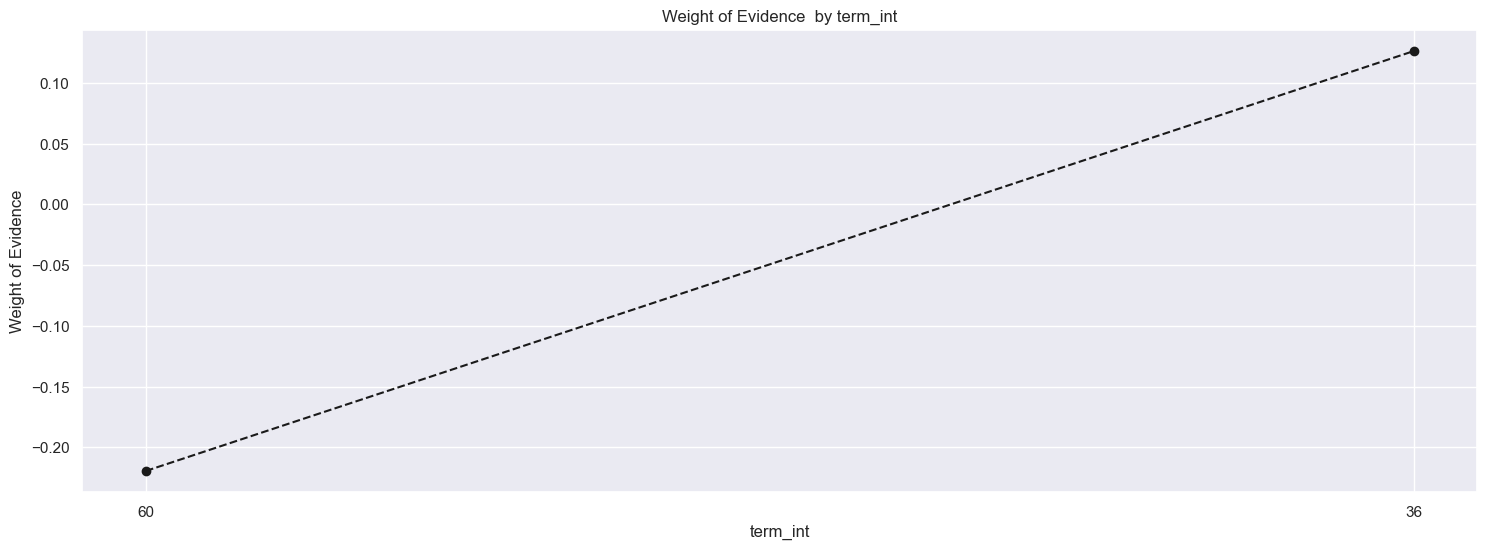

In [155]:
df_temp = df_temp.sort_values(by='term_int', ascending=False)
plot_by_woe(df_temp)

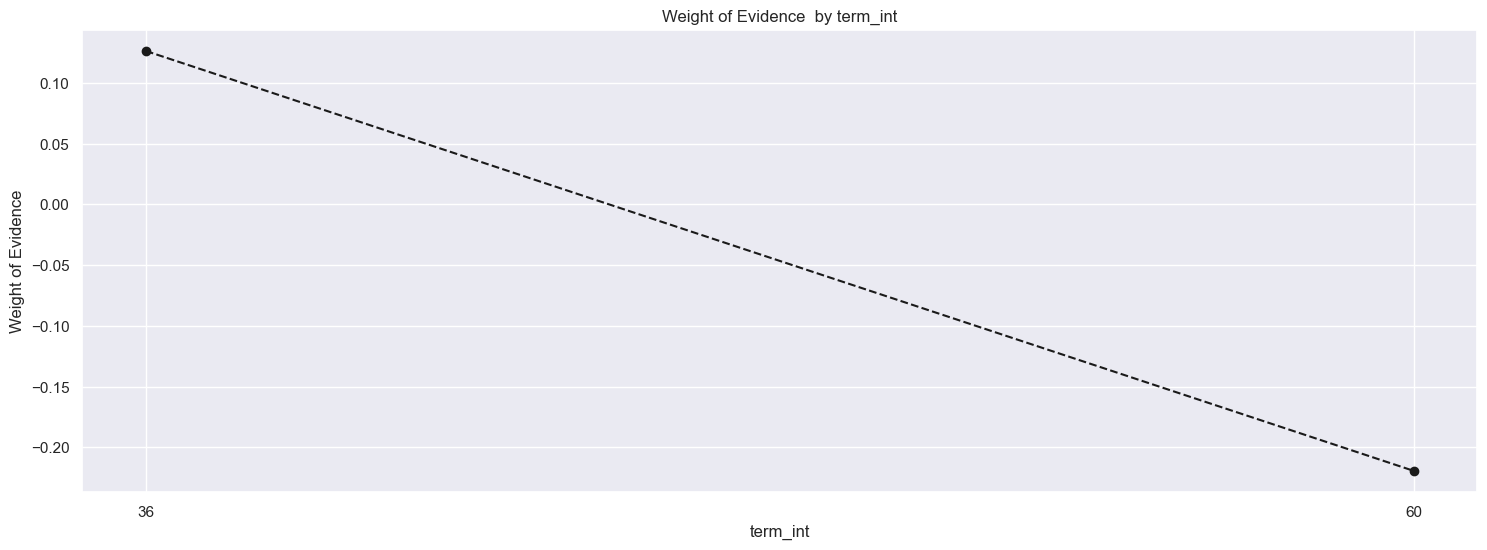

In [156]:
df_temp = df_temp.sort_values(by='term_int', ascending=True)
plot_by_woe(df_temp)

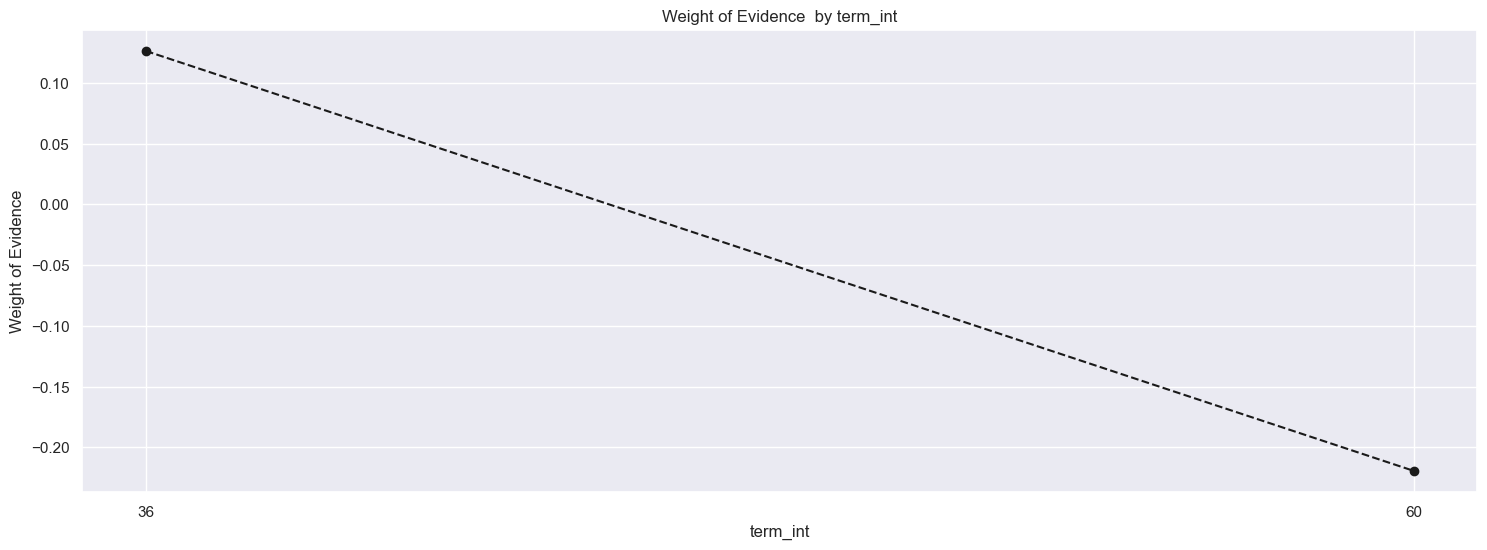

In [157]:

df_temp = df_temp.iloc[::-1]

'''Plotting in Opposite Direction
To reverse the plot direction:'''

plot_by_woe(df_temp.iloc[::-1])

Above are 2 categories/dummy variables for the term in the final model.  60 will be the reference point. 60 loans are riskier than 36 month loan
#Time to name our dummy variables similar to how we named our discrete using the convention, **Original variable Name Colon Category Name**

df['emp_zero'] = df['emp_length'].isin([0]).astype('uint8')

In [158]:
df_inputs_prepr['term:::36'] = np.where(df_inputs_prepr['term_int'] == 36, 1, 0) 
df_inputs_prepr['term:::60'] = np.where((df_inputs_prepr['term_int'] == 60), 1, 0) 
#this continuous variable was easy, no need to carry out fine classing or coarse

'''
df_dummies = pd.get_dummies(df[['grade','home_ownership']], prefix_sep=':')
# or one-liner with many columns:
df = pd.get_dummies(df, columns=['grade','home_ownership'], prefix_sep=':')


 #maybe also
df['is_senior'] = np.where(df['age'] >= 65, 1, 0)
# or
df['is_senior'] = (df['age'] >= 65).astype('uint8')  # faster idiom
'''

# or simply 
df_inputs_prepr['term:::36'] = (df_inputs_prepr['term'] == 36).astype('uint8')
df_inputs_prepr['term:::60'] = (df_inputs_prepr['term'] == 60).astype('uint8')


In [159]:
len(df_inputs_prepr['emp_length_int'].unique()) #11 levels integers from 0 to 10 so no need to do fine classing

11

In [160]:
df_temp = woe_ordered_continuous(df_inputs_prepr,'emp_length_int', df_targets_prepr)
df_temp.head()

,emp_length_int,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,0.0,58157,0.977733,0.138109,56862.0,1295.0,0.137599,0.164947,-0.181278,0.138109,NaN,NaN,0.019134
1,1.0,27473,0.977687,0.065242,26860.0,613.0,0.064998,0.078079,-0.183366,0.065242,0.000046,0.002088,0.019134
2,2.0,37497,0.980932,0.089047,36782.0,715.0,0.089008,0.091071,-0.022914,0.089047,0.003245,0.160453,0.019134
3,3.0,33430,0.980975,0.079388,32794.0,636.0,0.079358,0.081009,-0.020593,0.079388,0.000043,0.002321,0.019134
4,4.0,24506,0.979678,0.058196,24008.0,498.0,0.058097,0.063431,-0.087853,0.058196,0.001297,0.067260,0.019134


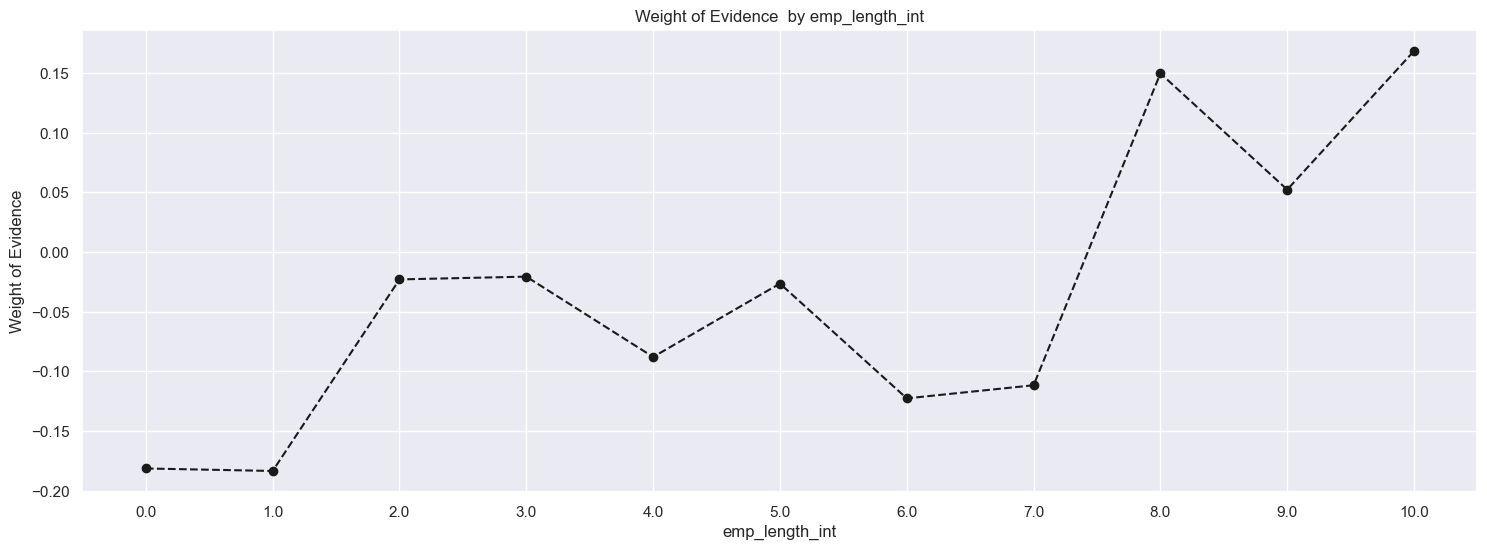

In [161]:
plot_by_woe(df_temp)

#Many ways to bundle them up but lets use this 
1. Borrowers with zero employment length
2.  1 year
3.  2 to 4
4.  5 and 6
5.  7 
6.  8
7.  9
8.  >=10

# because 7 and 9 have similar we could have made 7 to 9 category to reduce number of dummies, since these are continuous variables and order matters
Borrowers with 0 are the riskiest so 0 will be our reference point


In [162]:
# df_inputs_prepr['emp_length:0'] = np.where(df_inputs_prepr['emp_length'] ==0, 1, 0) 
df_inputs_prepr['emp_length:::0'] = np.where(df_inputs_prepr['emp_length'].isin([0]), 1, 0)
df_inputs_prepr['emp_length:::1'] = np.where(df_inputs_prepr['emp_length'].isin([1]), 1, 0)
df_inputs_prepr['emp_length:::2-4'] = np.where(df_inputs_prepr['emp_length'].isin(range(2,5)), 1, 0) # this is similar to coarse classing
df_inputs_prepr['emp_length:::5-6'] = np.where(df_inputs_prepr['emp_length'].isin(range(5,7)), 1, 0)
df_inputs_prepr['emp_length:::7-9'] = np.where(df_inputs_prepr['emp_length'].isin(range(7,10)), 1, 0)
df_inputs_prepr['emp_length:::10'] = np.where(df_inputs_prepr['emp_length'].isin([10]), 1, 0)


34 **Data Preparation. Preprocessing continuous: Creating Dummy Variables, part 2**
                        

                        **Time for More Complicated Preprocessing of Constinuous Variables** ~~we've finished 2 that were fairly easy*~~

In [163]:
print(loan_data.loc[:, ['issue_d', 'issue_d_date', 'mths_since_issue_d']][loan_data['mths_since_issue_d']<0])


Empty DataFrame
Columns: [issue_d, issue_d_date, mths_since_issue_d]
Index: []


In [164]:
def calculate_months(series, ref, fractional=False):
    """
    Calculate months difference between datetime Series and reference date.
    
    Parameters
    ----------
    series : pd.Series of datetime64[ns]
    ref : pd.Timestamp
    fractional : bool
        - False → integer months (calendar buckets)
        - True → fractional months (days/30.436875)
        
    Returns
    -------
    pd.Series of integers or floats
    """
    if fractional:
        # Fractional months using average month length
        return (ref - series).dt.days / 30.436875
    else:
        # Integer calendar month buckets
        return (ref.to_period("M") - series.dt.to_period("M")).astype(int)




def calculate_months_vectorized(series, ref):
    """
    Vectorised months difference between a datetime Series and a reference date.
    - series: pd.Series of datetime64[ns]
    - ref: pandas Timestamp
    """
    return (
        (ref.year - series.dt.year) * 12 +
        (ref.month - series.dt.month) -
        (ref.day < series.dt.day).astype(int)
    ).astype("Int64")


ref = pd.Timestamp("2017-11-01")

loan_data["mths_since_issue_d"] = calculate_months_vectorized(loan_data["issue_d_date"], ref)
loan_data["mths_since_earliest_cr_line"] = calculate_months_vectorized(loan_data["earliest_cr_line_date"], ref)

In [165]:
loan_data['mths_since_issue_d'].unique()

<IntegerArray>
[23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]
Length: 12, dtype: Int64

In [166]:
def calculate_months(series, ref, fractional=False):
    """
    Calculate months difference between datetime Series and reference date.
    
    Parameters
    ----------
    series : pd.Series of datetime64[ns]
    ref : pd.Timestamp
    fractional : bool
        - False → integer months (calendar buckets)
        - True → fractional months (days/30.436875)
        
    Returns
    -------
    pd.Series of integers or floats
    """
    if fractional:
        # Fractional months using average month length
        return (ref - series).dt.days / 30.436875
    else:
        # Integer calendar month buckets
        return (ref.to_period("M") - series.dt.to_period("M")).astype(int)




def calculate_months_vectorized(series, ref):
    """
    Vectorised months difference between a datetime Series and a reference date.
    - series: pd.Series of datetime64[ns]
    - ref: pandas Timestamp
    """
    return (
        (ref.year - series.dt.year) * 12 +
        (ref.month - series.dt.month) -
        (ref.day < series.dt.day).astype(int)
    ).astype("Int64")


ref = pd.Timestamp("2018-02-01")

loan_data["mths_since_issue_d"] = calculate_months_vectorized(loan_data["issue_d_date"], ref)
loan_data["mths_since_earliest_cr_line"] = calculate_months_vectorized(loan_data["earliest_cr_line_date"], ref)

In [167]:

print(df_inputs_prepr['mths_since_issue_d'].nunique()); 

print(f'\nthere are 90 distinct values, which arent so many, so we can treat them as categories and visualise in a 100 or fewer cats\
Better to work with with 50 or less fine classes when doing coarse classing , its neater \n')

df_inputs_prepr['mths_since_issue_d'].unique()



12

there are 90 distinct values, which arent so many, so we can treat them as categories and visualise in a 100 or fewer catsBetter to work with with 50 or less fine classes when doing coarse classing , its neater 



array([23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34])

In [168]:
loan_data['mths_since_issue_d'].unique()

<IntegerArray>
[26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]
Length: 12, dtype: Int64

In [169]:
print(f'(1) Fine classing: roughly grouping the values into categories \
2) coarse classing; determining final categories, combining few of the initial classing cats into bigger classes if needed)')

(1) Fine classing: roughly grouping the values into categories 2) coarse classing; determining final categories, combining few of the initial classing cats into bigger classes if needed)


In [170]:
#FACTOR IS COMMON TERM TO MEAN VARIABLE IS CATEGORICAL

df_inputs_prepr['mths_since_issue_d_factor'] = pd.cut(df_inputs_prepr['mths_since_issue_d'], 50)

df_inputs_prepr['mths_since_issue_d_factor'].head()

0    (22.989, 23.22]
1    (22.989, 23.22]
2    (22.989, 23.22]
3    (22.989, 23.22]
4    (22.989, 23.22]
Name: mths_since_issue_d_factor, dtype: category
Categories (50, interval[float64, right]): [(22.989, 23.22] < (23.22, 23.44] < (23.44, 23.66] < (23.66, 23.88] ... (33.12, 33.34] < (33.34, 33.56] < (33.56, 33.78] < (33.78, 34.0]]

In [171]:
#FACTOR IS COMMON TERM TO MEAN VARIABLE IS CATEGORICAL

f'This here is fine classing'

df_inputs_prepr['mths_since_issue_d_factor'] = pd.cut(df_inputs_prepr['mths_since_issue_d'], bins = 50)

df_inputs_prepr['mths_since_issue_d_factor'].head()

0    (22.989, 23.22]
1    (22.989, 23.22]
2    (22.989, 23.22]
3    (22.989, 23.22]
4    (22.989, 23.22]
Name: mths_since_issue_d_factor, dtype: category
Categories (50, interval[float64, right]): [(22.989, 23.22] < (23.22, 23.44] < (23.44, 23.66] < (23.66, 23.88] ... (33.12, 33.34] < (33.34, 33.56] < (33.56, 33.78] < (33.78, 34.0]]

In [172]:
df_temp  = woe_ordered_continuous(df_inputs_prepr, 'mths_since_issue_d_factor', df_targets_prepr) 
# first column of fine classes of mths_since_issue_d_factor
df_temp.head() 

C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


,mths_since_issue_d_factor,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,"(22.989, 23.22]",44342,1.000000,0.105302,44342.0,0.0,0.107302,0.000000,inf,0.105302,NaN,NaN,inf
1,"(23.22, 23.44]",0,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,inf
2,"(23.44, 23.66]",0,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,inf
3,"(23.66, 23.88]",0,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,inf
4,"(23.88, 24.1]",37530,0.998082,0.089125,37458.0,72.0,0.090644,0.009171,2.290915,0.089125,NaN,NaN,inf


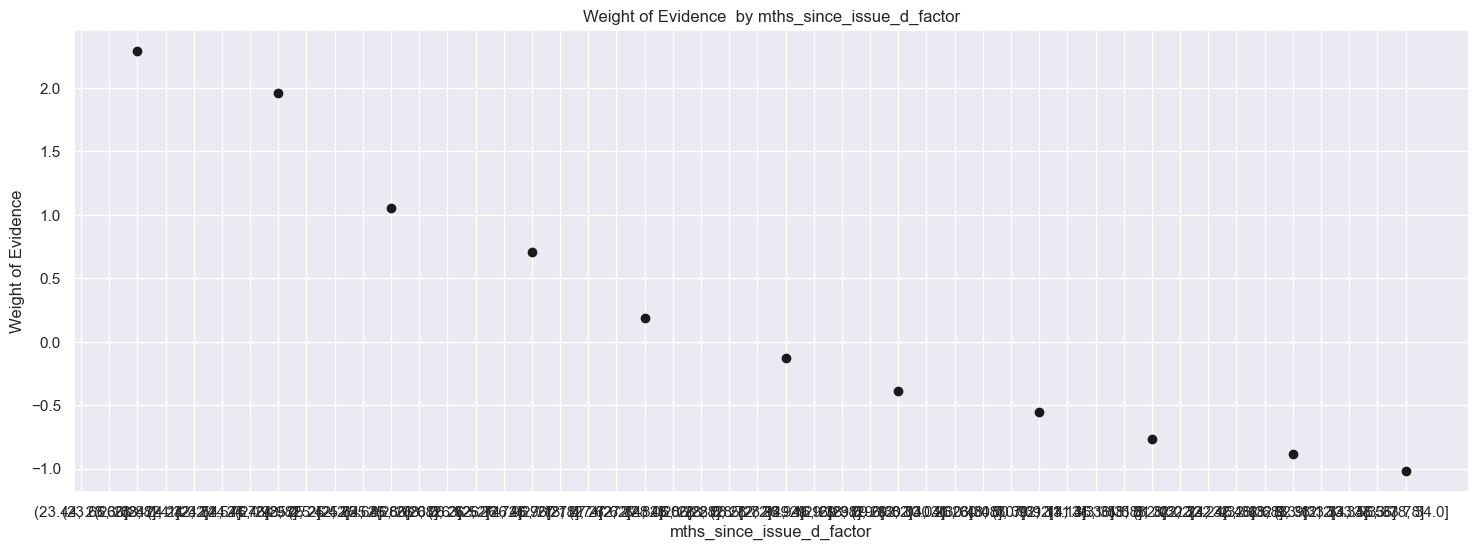

In [173]:
plot_by_woe(df_temp)

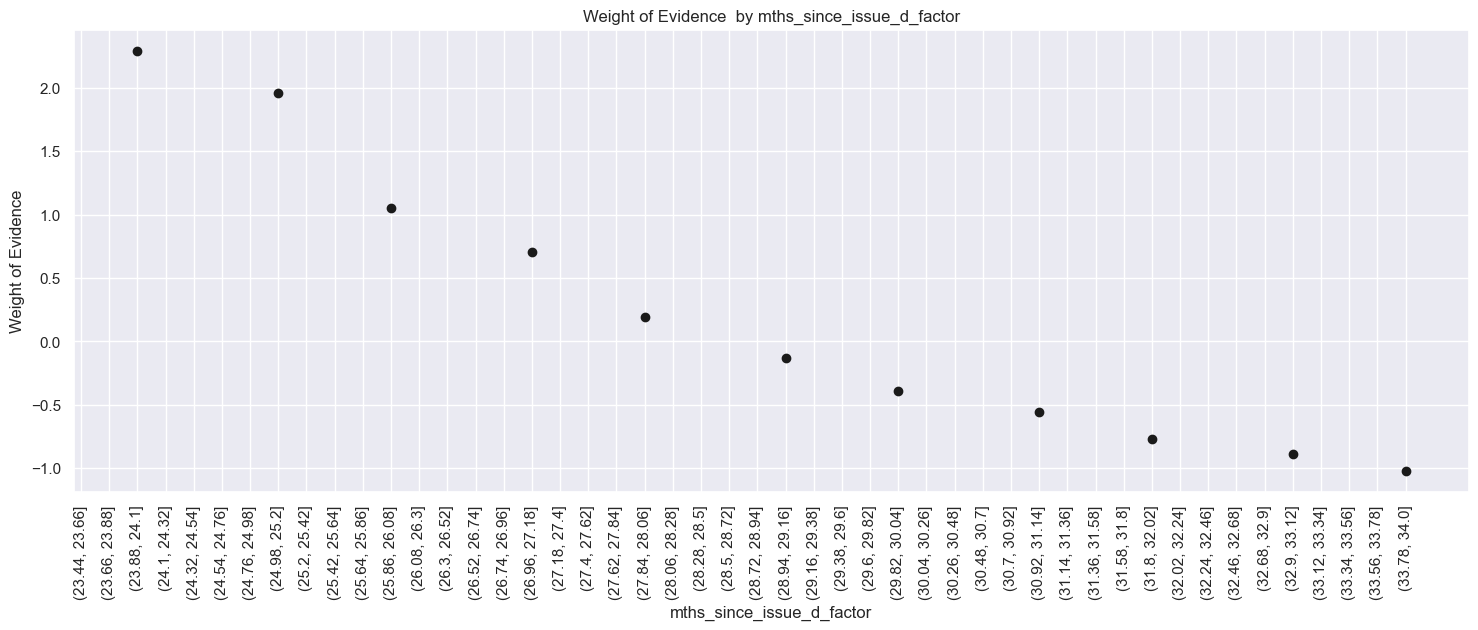

In [174]:
plot_by_woe(df_temp, rotation_of_x_axis_labels=90)

# Above categories months since issue date give us these 3 categories  <38, 38 to 39, 40 to 41 

# ***Months since issue date takes on integer values only, that means we can specify our dummy variables using only integer numbers***

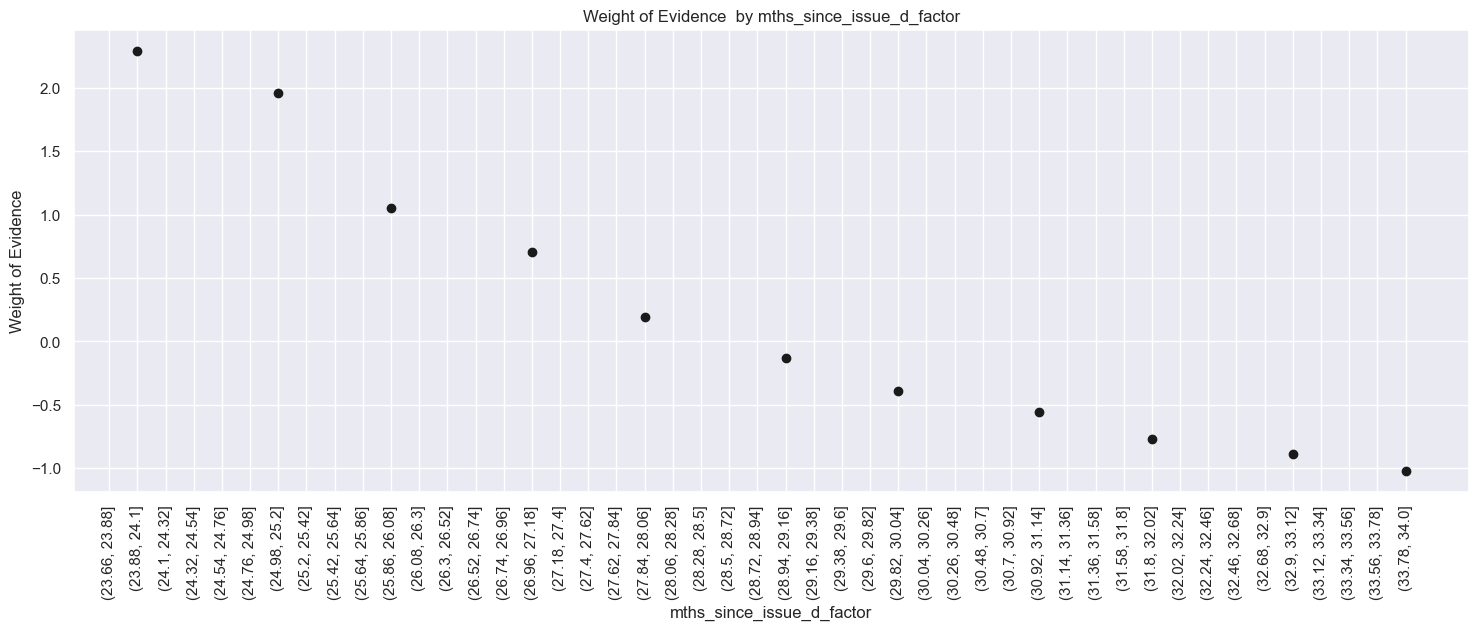

In [175]:
plot_by_woe(df_temp.iloc[3:,:], 90)

Categories here are 
1. first 4 have higher woes than the rest, and their woes aint that different 42 to 48
2. 49 to 52
3. 53 to 63
   
  ***number of observations comes into play here***  the rest of observations have less than 2% of population hence merge candidates
   thats why their curve is sporadic even, you can comment about changes in population sizes if relevant, its reason why their woe varied alot
   they contain small number of observation altogether 
   so even if have forgotten to check no. of obs per category, such a plot can act as a red flag(goes up and down) check no. of observations in respective categories 
   
4. a. we can either  combine and create one dummy variable for all of them
   b. or split and cut at say 85 months since issue date (could there be a reason for this ?)
   so there will be one dummy variable for 64 to 85 months and another one for more than 85 months since issue date

In [176]:
df_inputs_prepr['mths_since_issue_d:::<38'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin(range(37)), 1,0)
df_inputs_prepr['mths_since_issue_d:::38-39'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin([38,39]), 1,0)
df_inputs_prepr['mths_since_issue_d:::40-41'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin([40,41]), 1,0)
df_inputs_prepr['mths_since_issue_d:::42-48'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin(range(42,48)), 1,0)
df_inputs_prepr['mths_since_issue_d:::49-52'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin([49,52]), 1,0)
df_inputs_prepr['mths_since_issue_d:::53-63'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin([53,63]), 1,0)
df_inputs_prepr['mths_since_issue_d:::64-85'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin([64,85]), 1,0)
df_inputs_prepr['mths_since_issue_d:::>85'] = np.where(df_inputs_prepr['mths_since_issue_d']>85, 1,0)

**Interest rates , unlike months since issue date that takes on integer values, interest rates takes on fractional values .
When determing the limits of the categories for dummy variables, keep this in mind**

***below we are going to fine class the interest rate variable***

In [177]:
df_inputs_prepr['int_rate_factor'] = pd.cut(df_inputs_prepr['int_rate'], 50)
df_temp = woe_ordered_continuous(df_inputs_prepr, 'int_rate_factor', df_targets_prepr)
df_temp.head()

C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


,int_rate_factor,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,"(5.296, 5.793]",9651,0.999689,0.022919,9648.0,3.0,0.023347,0.000382,4.112499,0.022919,NaN,NaN,inf
1,"(5.793, 6.267]",10214,0.997259,0.024256,10186.0,28.0,0.024649,0.003566,1.933170,0.024256,0.002430,2.179329,inf
2,"(6.267, 6.74]",6530,0.994793,0.015507,6496.0,34.0,0.015720,0.004331,1.289186,0.015507,0.002465,0.643984,inf
3,"(6.74, 7.214]",12488,0.995275,0.029656,12429.0,59.0,0.030077,0.007515,1.386855,0.029656,0.000482,0.097669,inf
4,"(7.214, 7.687]",11416,0.997985,0.027110,11393.0,23.0,0.027570,0.002930,2.241865,0.027110,0.002710,0.855010,inf


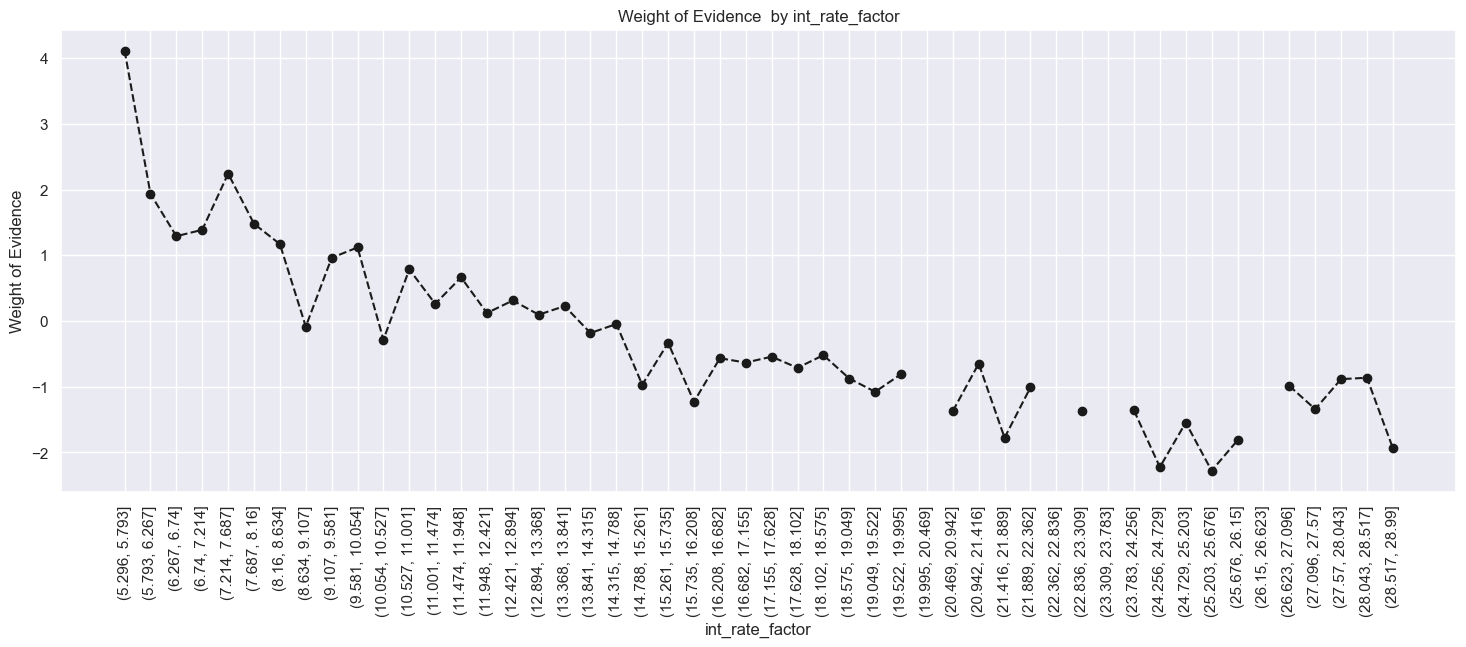

In [178]:
plot_by_woe(df_temp, 90)

from Graph relationship is almost monotonic 
The higher int , the lower woe and higher prob of default
presence of a monotonic relationship makes it somehow easier to determine the boundaries of the intervals 
it doesnt matter as much where they are as the next interval is almost certainly going to have lower  woe that the previous 
================================================================================================================================


1. Numerous ups and in first 10 obs points us to look at no.of obs, woe is high but few observations, <= 9.548
2. >9.548 < = 12.025
   >12.025 < = 15.74
   >15.74 < = 20.281
   >20.281 no major difference in woe and low no. of observations. so we group them in one dummy


In [179]:
df_inputs_prepr['int_rate:::<9.548'] = np.where((df_inputs_prepr['int_rate'] <= 9.548), 1,0)
df_inputs_prepr['int_rate:::9.548-12.025'] = np.where((df_inputs_prepr['int_rate'] >9.548) & (df_inputs_prepr['int_rate'] <= 12.025), 1,0)
df_inputs_prepr['int_rate:::12.025-15.74'] = np.where((df_inputs_prepr['int_rate'] >12.025) & (df_inputs_prepr['int_rate'] <= 15.74), 1,0)
df_inputs_prepr['int_rate:::15.74-20.281'] = np.where((df_inputs_prepr['int_rate'] >15.74) & (df_inputs_prepr['int_rate'] <= 20.281),1,0)
df_inputs_prepr['int_rate:::>20.281'] = np.where((df_inputs_prepr['int_rate'] >20.281), 1,0)


#Preprocessing continuous variables is important but not straight forward, lets try one more 

In [180]:
df_inputs_prepr['funded_amnt_factor'] = pd.cut(df_inputs_prepr['funded_amnt'], 50)
df_temp=woe_ordered_continuous(df_inputs_prepr, 'funded_amnt_factor', df_targets_prepr)
df_temp.head()

C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


,funded_amnt_factor,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,"(966.0, 1680.0]",3391,0.982306,0.008053,3331.0,60.0,0.008061,0.007642,0.053288,0.008053,NaN,NaN,0.027107
1,"(1680.0, 2360.0]",3751,0.981338,0.008908,3681.0,70.0,0.008908,0.008916,-0.000950,0.008908,0.000968,0.054239,0.027107
2,"(2360.0, 3040.0]",8134,0.981190,0.019316,7981.0,153.0,0.019313,0.019488,-0.009014,0.019316,0.000148,0.008063,0.027107
3,"(3040.0, 3720.0]",5133,0.983246,0.012190,5047.0,86.0,0.012213,0.010954,0.108807,0.012190,0.002056,0.117821,0.027107
4,"(3720.0, 4400.0]",7315,0.980041,0.017371,7169.0,146.0,0.017348,0.018596,-0.069480,0.017371,0.003205,0.178287,0.027107


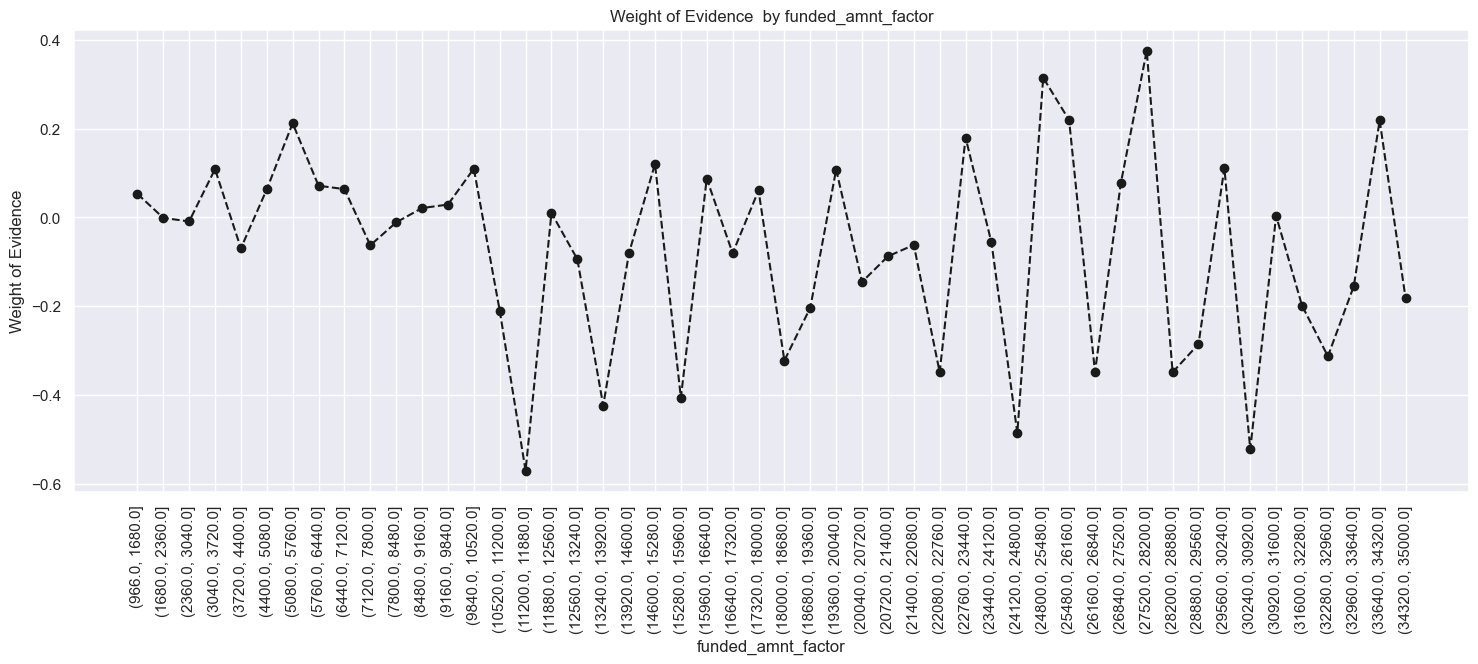

In [181]:
plot_by_woe(df_temp, 90)

In [182]:
# OTHERWISE DO ALL THE FOLLOWING WAY

In [183]:
bins = [
    0,
    5000,
    10000,
    20000,
    30000,
    np.inf
]

labels = [
    'funded:very_low',
    'funded:low',
    'funded:medium',
    'funded:high',
    'funded:very_high'
]

df_inputs_prepr['funded_amnt_grp'] = pd.cut(
    df_inputs_prepr['funded_amnt'],
    bins=bins,
    labels=labels
)


df_temp=woe_ordered_continuous(df_inputs_prepr, 'funded_amnt_grp', df_targets_prepr)
df_temp.head()


C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


,funded_amnt_grp,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,funded:very_low,45632,0.981921,0.108365,44807.0,825.0,0.108428,0.105082,0.031341,0.108365,NaN,NaN,0.004247
1,funded:low,103918,0.982544,0.246781,102104.0,1814.0,0.247080,0.231053,0.067063,0.246781,0.000623,0.035721,0.004247
2,funded:medium,168465,0.980673,0.400065,165209.0,3256.0,0.399787,0.414724,-0.036683,0.400065,0.001871,0.103746,0.004247
3,funded:high,76844,0.982133,0.182487,75471.0,1373.0,0.182631,0.174882,0.043355,0.182487,0.001460,0.080038,0.004247
4,funded:very_high,26235,0.977778,0.062302,25652.0,583.0,0.062075,0.074258,-0.179205,0.062302,0.004355,0.222561,0.004247


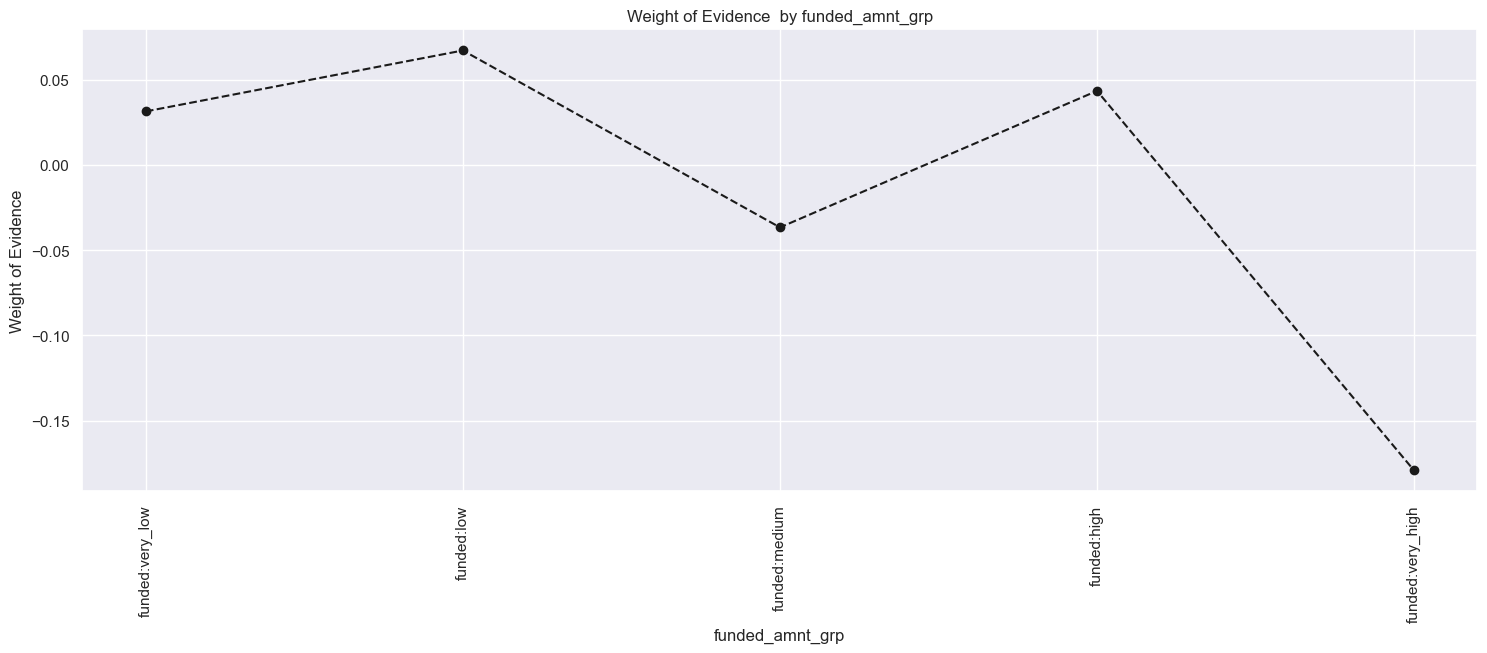

In [184]:
plot_by_woe(df_temp, 90)

In [185]:
n = df_inputs_prepr['funded_amnt_grp'].nunique()
print("Unique values:", n)

Unique values: 5


In [186]:
# 1. Ensure column exists
assert 'funded_amnt_grp' in df_inputs_prepr.columns

# 2. Ensure it is categorical
df_inputs_prepr['funded_amnt_grp'] = df_inputs_prepr['funded_amnt_grp'].astype('category')

# 3. Add Missing to allowed categories
df_inputs_prepr['funded_amnt_grp'] = (
    df_inputs_prepr['funded_amnt_grp']
        .cat.add_categories(['Missing'])
        .fillna('Missing')
)

# 4. Create dummies
funded_dummies = pd.get_dummies(
    df_inputs_prepr['funded_amnt_grp'],
    prefix='funded',
    prefix_sep=':::',
    drop_first=True
)

# 5. Join back
df_inputs_prepr = pd.concat([df_inputs_prepr, funded_dummies], axis=1)


In [187]:
# 1. Ensure column exists
assert 'funded_amnt_grp' in df_inputs_prepr.columns

# 2. Force everything to string and handle missing
df_inputs_prepr['funded_amnt_grp'] = (
    df_inputs_prepr['funded_amnt_grp']
        .astype(str)
        .replace('nan', 'Missing')   # important: astype(str) turns NaN into 'nan'
)

# 3. Create dummies
funded_dummies = pd.get_dummies(
    df_inputs_prepr['funded_amnt_grp'],
    prefix='funded',
    prefix_sep=':::',
    drop_first=True
)

# 4. Join back
# df_inputs_prepr = pd.concat([df_inputs_prepr, funded_dummies], axis=1)

# funded_dummies Please never call this leads to crushing of the browser 


In [188]:
'''Which one should you use?

For modeling pipelines, especially credit-scorecard style preprocessing:

Use Strategy 1.
Convert to string, control categories yourself, dummy encode.
Much fewer silent bugs.

Categorical dtype is fragile and causes exactly the kind of problems you’re seeing.

One final professional-level safety check

After creating dummies, always verify:

If that ever returns False, your pipeline is broken.'''

funded_dummies.isin([0, 1]).all().all()

np.True_

# Please do ***HOMEWORK ARTICLE ON No. 35***

                                ***HOMEWORK ARTICLE ON No. 35*** has amazing exercise 

        Preprocess:

        mths_since_earliest_cr_line
        installment
        delinq_2yrs
        open_acc
        pub_rec
        total_acc
        acc_now_delinq

For each decide whether to do fine classsing, or not . Run woe discrete and plot by woe , examine chart and data frame with results as argument , decide whether woe should be used for pd model , decide reference category
 preprocess installment as funded_amnt

C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


      annual_inc_factor   n_obs  prop_good  prop_n_obs    n_good   n_bad  \
0   (-9500.0, 190000.0]  409693   0.981193    0.972925  401988.0  7705.0   
1  (190000.0, 380000.0]   10007   0.986609    0.023764    9873.0   134.0   
2  (380000.0, 570000.0]     943   0.990456    0.002239     934.0     9.0   
3  (570000.0, 760000.0]     257   1.000000    0.000610     257.0     0.0   
4  (760000.0, 950000.0]      70   1.000000    0.000166      70.0     0.0   

   prop_n_good  prop_n_bad       WoE    n_obs%  diff_prop_good  diff_WoE   IV  
0     0.972764    0.981404 -0.008842  0.972925             NaN       NaN  inf  
1     0.023892    0.017068  0.336324  0.023764        0.005416  0.345166  inf  
2     0.002260    0.001146  0.678857  0.002239        0.003847  0.342533  inf  
3     0.000622    0.000000       inf  0.000610        0.009544       inf  inf  
4     0.000169    0.000000       inf  0.000166        0.000000       NaN  inf  


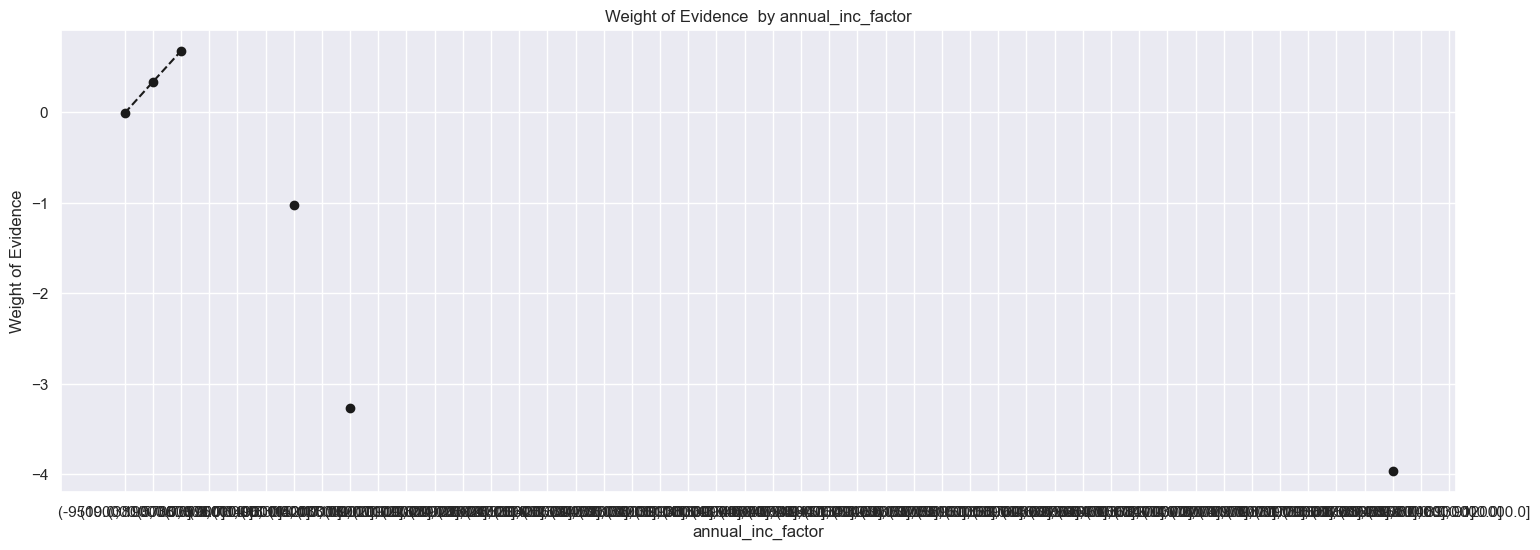

In [189]:
f'Annual income requires some special treatment\
It contains positive real numbers but can only take numbers greater than zero'


df_inputs_prepr['annual_inc_factor'] = pd.cut(df_inputs_prepr['annual_inc'], 50)

df_temp = woe_ordered_continuous(df_inputs_prepr, 'annual_inc_factor' , df_targets_prepr)
print(df_temp.head())
plot_by_woe(df_temp)


C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


      annual_inc_factor   n_obs  prop_good  prop_n_obs    n_good   n_bad  \
0    (-9500.0, 95000.0]  325648   0.980203    0.773338  319201.0  6447.0   
1   (95000.0, 190000.0]   84045   0.985032    0.199587   82787.0  1258.0   
2  (190000.0, 285000.0]    8186   0.986196    0.019440    8073.0   113.0   
3  (285000.0, 380000.0]    1821   0.988468    0.004324    1800.0    21.0   
4  (380000.0, 475000.0]     652   0.990798    0.001548     646.0     6.0   

   prop_n_good  prop_n_bad       WoE    n_obs%  diff_prop_good  diff_WoE   IV  
0     0.772429    0.821169 -0.061189  0.773338             NaN       NaN  inf  
1     0.200335    0.160234  0.223353  0.199587        0.004829  0.284542  inf  
2     0.019536    0.014393  0.305498  0.019440        0.001164  0.082145  inf  
3     0.004356    0.002675  0.487625  0.004324        0.002272  0.182127  inf  
4     0.001563    0.000764  0.715645  0.001548        0.002330  0.228021  inf  


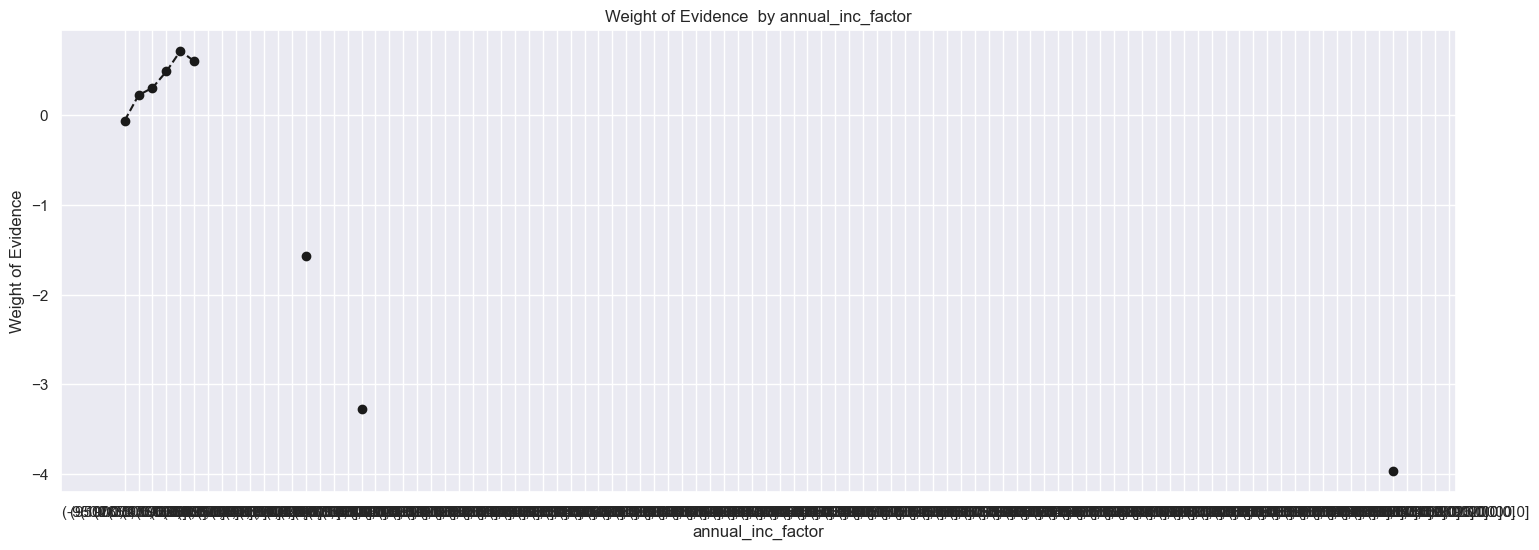

In [190]:
f"since most observationons are concentrated at the start\
didn't split well enough s lets try and split into more categories because 50 categories werent enough to fine class the variable"


df_inputs_prepr['annual_inc_factor'] = pd.cut(df_inputs_prepr['annual_inc'], 100)
df_temp = woe_ordered_continuous(df_inputs_prepr, 'annual_inc_factor', df_targets_prepr)
print(df_temp.head())
plot_by_woe(df_temp)


C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


         annual_inc_q  n_obs  prop_good  prop_n_obs   n_good   n_bad  \
0   (-0.001, 35000.0]  48304   0.974764    0.114711  47085.0  1219.0   
1  (35000.0, 42500.0]  35956   0.977222    0.085387  35137.0   819.0   
2  (42500.0, 50000.0]  49160   0.979679    0.116744  48161.0   999.0   
3  (50000.0, 57437.2]  35018   0.981524    0.083160  34371.0   647.0   
4  (57437.2, 65000.0]  48075   0.980884    0.114167  47156.0   919.0   

   prop_n_good  prop_n_bad       WoE    n_obs%  diff_prop_good  diff_WoE  \
0     0.113940    0.155267 -0.309471  0.114711             NaN       NaN   
1     0.085027    0.104318 -0.204469  0.085387        0.002458  0.105002   
2     0.116544    0.127245 -0.087845  0.116744        0.002456  0.116624   
3     0.083174    0.082410  0.009227  0.083160        0.001845  0.097072   
4     0.114112    0.117055 -0.025464  0.114167        0.000640  0.034692   

         IV  
0  0.033723  
1  0.033723  
2  0.033723  
3  0.033723  
4  0.033723  


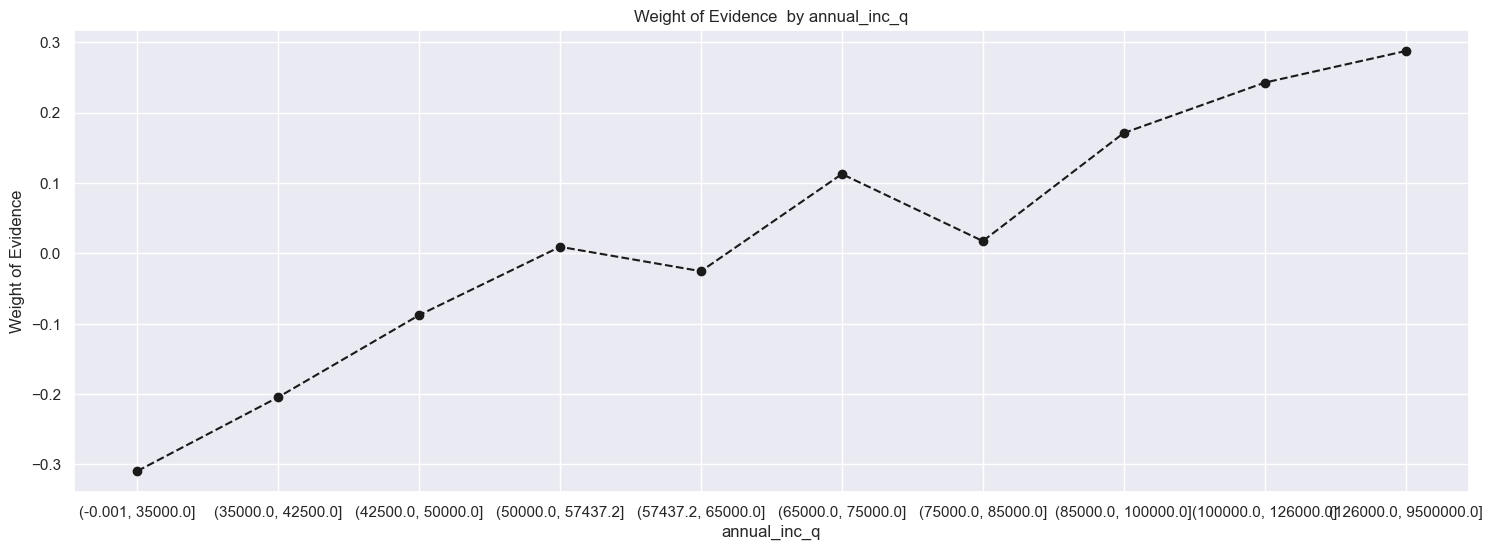

In [191]:
df_inputs_prepr['annual_inc_q'] = pd.qcut(
    df_inputs_prepr['annual_inc'],
    q=10,
    duplicates='drop'
)

df_temp = woe_ordered_continuous(df_inputs_prepr, 'annual_inc_q', df_targets_prepr)
print(df_temp.head())
plot_by_woe(df_temp)


# ***PREPROCESSING CONTINUOUS VARIABLES: CREATING DUMMY VARIABLES , PART 3***

In [192]:
f"again first cat has a large number of observations 62% of all observations, in common logic this is kinda expected, There are few people with large\
income so good idea to set aside people with high income in one dummy variable and investigate the lower income separately\
the first 2 categories contain a lot of observations while each of te subsequent categories  contains very few observations\
the higher the incone the lower the number of observations Third category starts at 144693, so lets assume  $140,000 to be the threshold btn low and high\
this way high income category will have observations a bit more than 5% of the observations \
Now let's focus on people with lower income, for convenience we will store them in  a temporary df"



#df_inputs_prepr_temp =  df_inputs_prepr[df_inputs_prepr['annual_inc'].loc(df_inputs_prepr['annual_inc'] <= 140000)] wrong coz loc is on series on a df


df_inputs_prepr_temp =  df_inputs_prepr[df_inputs_prepr['annual_inc'] <= 140000] 

#df_inputs_prepr_temp =  df_inputs_prepr.loc[df_inputs_prepr['annual_inc'] <= 140000, :]

df_inputs_prepr_temp['annual_inc_factor'] = pd.cut(df_inputs_prepr_temp['annual_inc'], 50)

df_temp = woe_ordered_continuous(df_inputs_prepr_temp, 'annual_inc_factor', df_targets_prepr[df_inputs_prepr_temp.index])
df_temp.head()



C:\Users\USER\AppData\Local\Temp\ipykernel_3412\3997343196.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_inputs_prepr_temp['annual_inc_factor'] = pd.cut(df_inputs_prepr_temp['annual_inc'], 50)
C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future versio

,annual_inc_factor,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,"(-140.0, 2800.0]",4,1.000000,0.000010,4.0,0.0,0.000010,0.000000,inf,0.000010,NaN,NaN,inf
1,"(2800.0, 5600.0]",12,0.916667,0.000031,11.0,1.0,0.000029,0.000135,-1.547375,0.000031,0.083333,inf,inf
2,"(5600.0, 8400.0]",55,0.981818,0.000141,54.0,1.0,0.000141,0.000135,0.043714,0.000141,0.065152,1.591089,inf
3,"(8400.0, 11200.0]",429,0.965035,0.001097,414.0,15.0,0.001079,0.002022,-0.627454,0.001097,0.016783,0.671168,inf
4,"(11200.0, 14000.0]",873,0.977090,0.002233,853.0,20.0,0.002224,0.002695,-0.192243,0.002233,0.012056,0.435212,inf


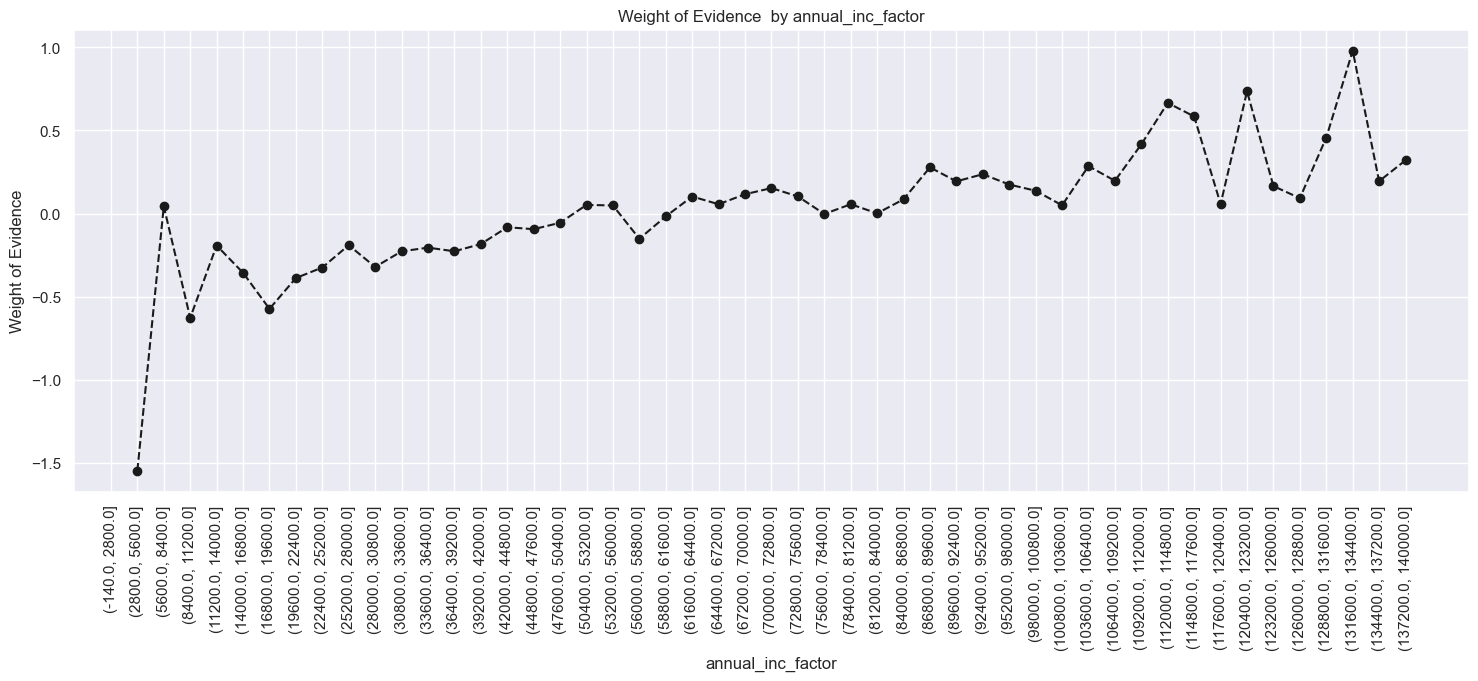

In [193]:
plot_by_woe(df_temp, 90)

In [194]:
f" Rember int rate was in opposite direction, also annual income is more monotonic, hence we can split this into intervals"

"""
mine were (1. < 10,182
2. 10,182 - 26,754  
3. 26,754 - 37,803
4. 37,803 - 51,513
5. 51,513 - 62,661
6. 62,661 - 73,710
7. 73,710 - 81,996
8. 81,996 - 98,568
9. 98,568 - 120,665
10. > 120,665) 

tutors approach below

We take into consideration number of observations as well the first 2 intervls upto 10,182 and 21,230  have very few observations each
so first interval will be <=20K

if we kept everything split with width 10,000 the last 4 intervals (3736 to 5714 to 6228, to 3033 t0 2532) from 100k to 140k  would also have a very 
low number of observations each, with that in mind lets make 2 intervals from 100k to 120 k and 120 k to 140k

what will be left is btn 20k and 100k and we will split it into categories of 10,000 each , 8 equally wide 

20k to 30k 
30 to 40k
40k to 50k
50k to 60k
60k to 70k
70k to 80k
80k to 90k 
90k to 100k
"""

df_inputs_prepr['annual_inc:::<20k'] = np.where((df_inputs_prepr['annual_inc'] <= 20000), 1,0)
df_inputs_prepr['annual_inc:::20k-30k'] = np.where((df_inputs_prepr['annual_inc'] > 20000) & (df_inputs_prepr['annual_inc'] <=20000), 1,0)
df_inputs_prepr['annual_inc:::30k-40k'] = np.where((df_inputs_prepr['annual_inc'] > 30000) & (df_inputs_prepr['annual_inc'] <=40000), 1,0)
df_inputs_prepr['annual_inc:::40k-50k'] = np.where((df_inputs_prepr['annual_inc'] > 40000) & (df_inputs_prepr['annual_inc'] <=50000), 1,0)
df_inputs_prepr['annual_inc:::50k-60k'] = np.where((df_inputs_prepr['annual_inc'] > 50000) & (df_inputs_prepr['annual_inc'] <=60000), 1,0)
df_inputs_prepr['annual_inc:::60k-70k'] = np.where((df_inputs_prepr['annual_inc'] > 60000) & (df_inputs_prepr['annual_inc'] <=70000), 1,0)
df_inputs_prepr['annual_inc:::70k-80k'] = np.where((df_inputs_prepr['annual_inc'] > 70000) & (df_inputs_prepr['annual_inc'] <=80000), 1,0)
df_inputs_prepr['annual_inc:::80k-90k'] = np.where((df_inputs_prepr['annual_inc'] > 80000) & (df_inputs_prepr['annual_inc'] <=90000), 1,0)
df_inputs_prepr['annual_inc:::90k-100k'] = np.where((df_inputs_prepr['annual_inc'] > 90000) & (df_inputs_prepr['annual_inc'] <=100000), 1,0)
df_inputs_prepr['annual_inc:::100k-120k'] = np.where((df_inputs_prepr['annual_inc'] > 100000) & (df_inputs_prepr['annual_inc'] <=120000), 1,0)
df_inputs_prepr['annual_inc:::120k-140k'] = np.where((df_inputs_prepr['annual_inc'] > 120000) & (df_inputs_prepr['annual_inc'] <=140000), 1,0)
df_inputs_prepr['annual_inc:::>140k'] = np.where((df_inputs_prepr['annual_inc'] >= 140000), 1,0)






# ***Months since last delinquency variable is another tricky one..***

from our initial preprocessing , we already know that this has a lot of missing values, so many that we cant do anything with them at this stage
Now since we are about to estimate our statistical model it is time to face the issue ..

Every continuous variable is  represented by dummy variables in the probability of default model and this variable will be no exception. the variable takes integer vales greater than zero

for the missing values we shall just create another dummy variable for them . so lets create a dummy variable indicating that the value of the originla variable is missing 

missing value dummy variable = 
1:  When the value is missing 
0: when the value is not missing 


# NOTE THAT THIS METHOD OF DEALING WITH MISSING VALUES CAN ONLY BE DONE WITH CATEGORICAL VARIABLES 

In [195]:
df_inputs_prepr_temp = df_inputs_prepr[pd.notnull(df_inputs_prepr['mths_since_last_delinq'])]
df_inputs_prepr_temp['mths_since_last_delinq_factor'] =pd.cut(df_inputs_prepr_temp['mths_since_last_delinq'], 50)
df_temp = woe_ordered_continuous(df_inputs_prepr_temp, 'mths_since_last_delinq_factor', df_targets_prepr[df_inputs_prepr_temp.index])   
df_temp.head()

C:\Users\USER\AppData\Local\Temp\ipykernel_3412\3296281081.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_inputs_prepr_temp['mths_since_last_delinq_factor'] =pd.cut(df_inputs_prepr_temp['mths_since_last_delinq'], 50)
C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_3412\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to T

,mths_since_last_delinq_factor,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,"(-0.176, 3.52]",7261,0.973833,0.033440,7071.0,190.0,0.033183,0.047041,-0.349003,0.033440,NaN,NaN,inf
1,"(3.52, 7.04]",15763,0.978367,0.072596,15422.0,341.0,0.072372,0.084427,-0.154068,0.072596,0.004534,0.194935,inf
2,"(7.04, 10.56]",12365,0.980348,0.056947,12122.0,243.0,0.056886,0.060163,-0.056020,0.056947,0.001981,0.098048,inf
3,"(10.56, 14.08]",16125,0.979721,0.074263,15798.0,327.0,0.074136,0.080961,-0.088058,0.074263,0.000627,0.032037,inf
4,"(14.08, 17.6]",11384,0.976985,0.052429,11122.0,262.0,0.052193,0.064868,-0.217400,0.052429,0.002736,0.129343,inf


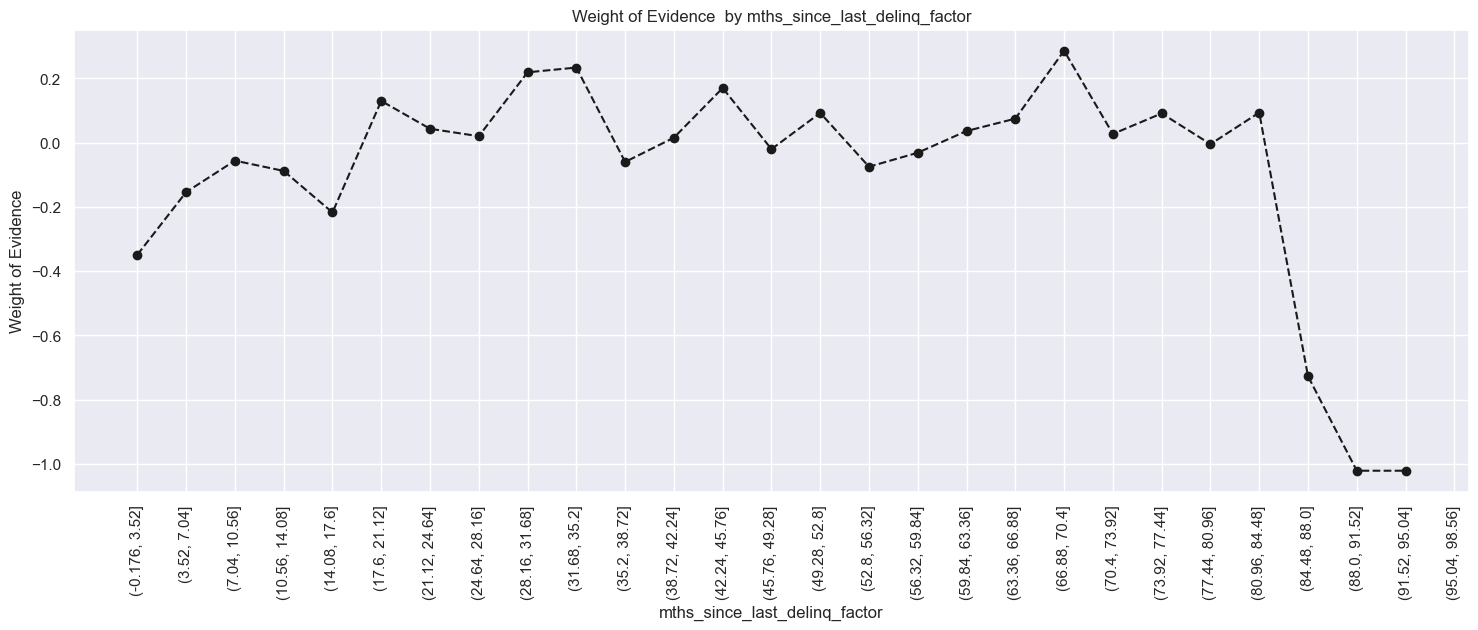

In [196]:
plot_by_woe(df_temp, 90)

In [197]:
f" first cat is 0 to 3 months, second  are the next 7 months from  4 to 30 mnths , from 31 to 56 months, from 56 months to 82 months , then 82 months\
but 82 has very few observations, doesnt make sense treat them separately so we add it to the interval of 56 months so last interval is >=  56 months"




' first cat is 0 to 3 months, second  are the next 7 months from  4 to 30 mnths , from 31 to 56 months, from 56 months to 82 months , then 82 monthsbut 82 has very few observations, doesnt make sense treat them separately so we add it to the interval of 56 months so last interval is >=  56 months'

In [198]:
df_inputs_prepr['mths_since_last_delinq:::Missing'] = np.where((df_inputs_prepr['mths_since_last_delinq'].isnull()),1,0)

df_inputs_prepr['mths_since_last_delinq:::0-3'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq']>=0) & (df_inputs_prepr['mths_since_last_delinq']<=4),1,0)

df_inputs_prepr['mths_since_last_delinq:::4-30'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq']>=4) & (df_inputs_prepr['mths_since_last_delinq']<=30),1,0)

df_inputs_prepr['mths_since_last_delinq:::31-56'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq']>=31) & (df_inputs_prepr['mths_since_last_delinq']<=56),1,0)

df_inputs_prepr['mths_since_last_delinq:::0-3'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq']>=57),1,0)



In [199]:
df_inputs_prepr.columns.duplicated().sum()

np.int64(0)

****Preprocessing the Test Dataset**

In [200]:
#loan_data_inputs_train = df_inputs_prepr '''these were for the training phase '''
#loan_data_targets_train = df_targets_prepr  ''' now we gonna change the naming  to those below for the model maintenance stage '''
#Remember we dont have split datasets i.e. train and test its just 2015 now 

''' The following dfs loan_data_inputs_2015 and loan_data_targets_2015 store our preprocessed datasets with new applicants  '''

loan_data_inputs_2015 = df_inputs_prepr 
loan_data_targets_2015 = df_targets_prepr

In [201]:
loan_data_inputs_2015.columns.values # these are the columns ie, values of inputs 

array(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade',
       'emp_title', 'emp_length', 'home_ownership', 'annual_inc',
       'verification_status', 'issue_d', 'loan_status', 'pymnt_plan',
       'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti',
       'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths',
       'mths_since_last_delinq', 'mths_since_last_record', 'open_acc',
       'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt',
       'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int',
       'total_rec_late_fee', 'recoveries', 'collection_recovery_fee',
       'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d',
       'last_credit_pull_d', 'collections_12_mths_ex_med',
       'mths_since_last_major_derog', 'policy_code', 'application_type',
       'annual_inc_joint', 'dti_joint', 'verification_status_joint

In [202]:
loan_data_inputs_2015.shape

(421094, 266)

In [203]:
loan_data_targets_2015.shape

(421094,)

In [204]:
# ***Export all these dataframes and store them in pickle files***

loan_data_inputs_2015.to_pickle('loan_data_inputs_2015.pkl') 
loan_data_targets_2015.to_pickle('loan_data_targets_2015.pkl')

ref_categories = pd.read_pickle('ref_categories.pkl')
ref_categories

>>> the code up to here, from the other line starting with '>>>' is copied from Data Preparation notebook with minor adjustments
at this point most of our preprocessing is done what is left is choosing only those dummies that were actually used in the PD model.
this information is contained in the inputs_train_with_ref_cat 

In [205]:
inputs_test_with_ref_cat = pd.read_pickle('inputs_test_with_ref_cat.pkl') # in tutorial we used inputs_train_with_ref_cat


In [206]:
inputs_test_with_ref_cat.columns.values

array(['Unnamed: 0', 'id', 'member_id', 'loan_amnt', 'funded_amnt',
       'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade',
       'sub_grade', 'emp_title', 'emp_length', 'home_ownership',
       'annual_inc', 'verification_status', 'issue_d', 'loan_status',
       'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code',
       'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line',
       'inq_last_6mths', 'mths_since_last_delinq',
       'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'initial_list_status', 'out_prncp',
       'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv',
       'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee',
       'recoveries', 'collection_recovery_fee', 'last_pymnt_d',
       'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d',
       'collections_12_mths_ex_med', 'mths_since_last_major_derog',
       'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint',
       'veri

In [207]:
inputs_test_with_ref_cat.head()

,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,issue_d_date,mths_since_issue_d,grade:::A,grade:::B,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,sub_grade:::A1,sub_grade:::A2,sub_grade:::A3,sub_grade:::A4,sub_grade:::A5,sub_grade:::B1,sub_grade:::B2,sub_grade:::B3,sub_grade:::B4,sub_grade:::B5,sub_grade:::C1,sub_grade:::C2,sub_grade:::C3,sub_grade:::C4,sub_grade:::C5,sub_grade:::D1,sub_grade:::D2,sub_grade:::D3,sub_grade:::D4,sub_grade:::D5,sub_grade:::E1,sub_grade:::E2,sub_grade:::E3,sub_grade:::E4,sub_grade:::E5,sub_grade:::F1,sub_grade:::F2,sub_grade:::F3,sub_grade:::F4,sub_grade:::F5,sub_grade:::G1,sub_grade:::G2,sub_grade:::G3,sub_grade:::G4,sub_grade:::G5,verification_status:::Not Verified,verification_status:::Source Verified,verification_status:::Verified,home_ownership:ANY,home_ownership:MORTGAGE,home_ownership:NONE,home_ownership:OTHER,home_ownership:OWN,home_ownership:RENT,loan_status:::Charged Off,loan_status:::Current,loan_status:::Default,loan_status:::Does not meet the credit policy. Status:Charged Off,loan_status:::Does not meet the credit policy. Status:Fully Paid,loan_status:::Fully Paid,loan_status:::In Grace Period,loan_status:::Late (16-30 days),loan_status:::Late (31-120 days),purpose:::car,purpose:::credit_card,purpose:::debt_consolidation,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,addr_state:AK,addr_state:AL,addr_state:AR,addr_state:AZ,addr_state:CA,addr_state:CO,addr_state:CT,addr_state:DC,addr_state:DE,addr_state:FL,addr_state:GA,addr_state:HI,addr_state:IA,addr_state:ID,addr_state:IL,addr_state:IN,addr_state:KS,addr_state:KY,addr_state:LA,addr_state:MA,addr_state:MD,addr_state:ME,addr_state:MI,addr_state:MN,addr_state:MO,addr_state:MS,addr_state:MT,addr_state:NC,addr_state:NE,addr_state:NH,addr_state:NJ,addr_state:NM,addr_state:NV,addr_state:NY,addr_state:OH,addr_state:OK,addr_state:OR,addr_state:PA,addr_state:RI,addr_state:SC,addr_state:SD,addr_state:TN,addr_state:TX,addr_state:UT,addr_state:VA,addr_state:VT,addr_state:WA,addr_state:WI,addr_state:WV,addr_state:WY,initial_list_status:::f,initial_list_status:::w,home_ownership:::RENT_OTHER_NONE_ANY,addr_state:ND,addr_state:::NM_VA,addr_state:::ND_NE_IA_NV_FL_HI_AL,addr_state:::OK_TN_MO_LA_MD_NC,addr_state:::GA_WA_OR,addr_state:::UT_KY_AZ_NJ,addr_state:::WI_MT,addr_state:::AR_MI_PA_OH_MN,addr_state:::RI_MA_DE_SD_IN,addr_state:::IL_CT,addr_state:::KS_SC_CO_VT_AK_MS,addr_state:::WV_NH_WY_DC_ME_ID,term_int,term:::36,term:::60,emp_length:::0,emp_length:::1,emp_length:::2-4,emp_length:::5-6,emp_length:::7-9,emp_length:::10,mths_since_issue_d_factor,mths_since_issue_d:::<38,mths_since_issue_d:::38-39,mths_since_issue_d:::40-41,mths_since_issue_d:::42-48,mths_since_issue_d:::49-52,mths_since_issue_d:::53-63,mths_since_issue_d:::64-85,mths_since_issue_d:::>85,int_rate_factor,int_rate:::<9.548,int_rate:::9.548-12

In [208]:
type(inputs_test_with_ref_cat)

pandas.core.frame.DataFrame

In [209]:
inputs_train_with_ref_cat = pd.read_pickle('inputs_train_with_ref_cat.pkl') # in tutorial we used inputs_train_with_ref_cat


In [210]:
inputs_train_with_ref_cat.columns.values

array(['loan_status:::Does not meet the credit policy. Status:Charged Off',
       'grade:::A', 'purpose:::house', 'sub_grade:::F4',
       'mths_since_issue_d:::>85', 'sub_grade:::D4',
       'purpose:::home_improvement', 'annual_inc:::30k-40k',
       'sub_grade:::D1', 'sub_grade:::G4', 'addr_state:::IL_CT',
       'grade:::F', 'sub_grade:::A4', 'sub_grade:::C4', 'grade:::E',
       'loan_status:::Fully Paid', 'mths_since_issue_d:::40-41',
       'purpose:::wedding', 'sub_grade:::C2', 'sub_grade:::E5',
       'addr_state:::WI_MT', 'verification_status:::Not Verified',
       'sub_grade:::E2', 'addr_state:::RI_MA_DE_SD_IN',
       'verification_status:::Verified', 'sub_grade:::B1',
       'mths_since_issue_d:::<38', 'purpose:::other',
       'mths_since_last_delinq:::Missing', 'int_rate:::9.548-12.025',
       'addr_state:::AR_MI_PA_OH_MN', 'sub_grade:::F2',
       'loan_status:::Current', 'sub_grade:::A2', 'loan_status:::Default',
       'mths_since_issue_d:::38-39', 'initial_list_st

In [211]:
inputs_train_with_ref_cat.head()

,loan_status:::Does not meet the credit policy. Status:Charged Off,grade:::A,purpose:::house,sub_grade:::F4,mths_since_issue_d:::>85,sub_grade:::D4,purpose:::home_improvement,annual_inc:::30k-40k,sub_grade:::D1,sub_grade:::G4,addr_state:::IL_CT,grade:::F,sub_grade:::A4,sub_grade:::C4,grade:::E,loan_status:::Fully Paid,mths_since_issue_d:::40-41,purpose:::wedding,sub_grade:::C2,sub_grade:::E5,addr_state:::WI_MT,verification_status:::Not Verified,sub_grade:::E2,addr_state:::RI_MA_DE_SD_IN,verification_status:::Verified,sub_grade:::B1,mths_since_issue_d:::<38,purpose:::other,mths_since_last_delinq:::Missing,int_rate:::9.548-12.025,addr_state:::AR_MI_PA_OH_MN,sub_grade:::F2,loan_status:::Current,sub_grade:::A2,loan_status:::Default,mths_since_issue_d:::38-39,initial_list_status:::w,int_rate:::12.025-15.74,loan_status:::Charged Off,annual_inc:::50k-60k,emp_length:::0,annual_inc:::20k-30k,loan_status:::Does not meet the credit policy. Status:Fully Paid,sub_grade:::D2,grade:::G,sub_grade:::E4,emp_length:::5-6,emp_length:::7-9,int_rate:::<9.548,int_rate:::15.74-20.281,annual_inc:::60k-70k,sub_grade:::G3,int_rate:::>20.281,annual_inc:::80k-90k,purpose:::medical,grade:::B,verification_status:::Source Verified,purpose:::small_business,addr_state:::OK_TN_MO_LA_MD_NC,annual_inc:::120k-140k,sub_grade:::F5,sub_grade:::C3,sub_grade:::B2,sub_grade:::F3,purpose:::moving,term:::60,sub_grade:::A1,addr_state:::NM_VA,sub_grade:::G5,loan_status:::Late (31-120 days),annual_inc:::90k-100k,sub_grade:::B3,sub_grade:::A5,sub_grade:::B4,sub_grade:::F1,annual_inc:::70k-80k,emp_length:::2-4,purpose:::debt_consolidation,purpose:::vacation,sub_grade:::D3,annual_inc:::<20k,purpose:::major_purchase,initial_list_status:::f,term:::36,loan_status:::In Grace Period,mths_since_last_delinq:::31-56,purpose:::car,emp_length:::10,purpose:::renewable_energy,annual_inc:::40k-50k,mths_since_last_delinq:::0-3,grade:::C,sub_grade:::G1,sub_grade:::G2,addr_state:::GA_WA_OR,addr_state:::UT_KY_AZ_NJ,grade:::D,sub_grade:::C1,sub_grade:::A3,sub_grade:::C5,mths_since_issue_d:::53-63,annual_inc:::>140k,addr_state:::ND_NE_IA_NV_FL_HI_AL,addr_state:::KS_SC_CO_VT_AK_MS,mths_since_last_delinq:::4-30,addr_state:::WV_NH_WY_DC_ME_ID,emp_length:::1,home_ownership:::RENT_OTHER_NONE_ANY,sub_grade:::B5,purpose:::educational,mths_since_issue_d:::49-52,annual_inc:::100k-120k,loan_status:::Late (16-30 days),mths_since_issue_d:::42-48,sub_grade:::D5,sub_grade:::E3,mths_since_issue_d:::64-85,purpose:::credit_card,sub_grade:::E1
427211,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
206088,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0
136020,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
412305,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0
36159,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0


In [212]:
''' since we need a similar file containing '''

input_cols = inputs_train_with_ref_cat.drop(columns =['loan_status:::Does not meet the credit policy. Status:Charged Off', 'loan_status:::Does not meet the credit policy. Status:Fully Paid'], axis = 1)
'''
When you call .drop() on a DataFrame:

DataFrame.drop(labels)

Pandas assumes you are dropping rows by default.

Default is:

axis=0

Which means: drop rows.
'''
inputs_2015_with_ref_cat = loan_data_inputs_2015.loc[:, input_cols.columns.values]


In [213]:
inputs_train_with_ref_cat.shape

(373028, 119)

In [214]:
inputs_2015_with_ref_cat.shape

(421094, 117)

In [215]:
# ✅ Code to Find Excess Columns. This finds columns in TRAIN that are NOT in 2015:

train_cols = set(inputs_train_with_ref_cat.columns)
test_cols  = set(inputs_2015_with_ref_cat.columns)

excess_in_train = train_cols - test_cols

print("Columns in TRAIN but NOT in 2015:")
print(excess_in_train)
print("Count:", len(excess_in_train))


# 🔁 Also Check the Opposite Direction

missing_in_train = test_cols - train_cols

print("Columns in 2015 but NOT in TRAIN:")
print(missing_in_train)
print("Count:", len(missing_in_train))

Columns in TRAIN but NOT in 2015:
{'loan_status:::Does not meet the credit policy. Status:Fully Paid', 'loan_status:::Does not meet the credit policy. Status:Charged Off'}
Count: 2
Columns in 2015 but NOT in TRAIN:
set()
Count: 0


In [216]:
inputs_train_with_ref_cat = inputs_train_with_ref_cat.drop(
    columns=list(excess_in_train), errors='ignore'
)

In [217]:
inputs_2015_with_ref_cat = inputs_2015_with_ref_cat.drop(
    columns=list(missing_in_train),
    errors='ignore'
)

In [218]:
assert list(inputs_train_with_ref_cat.columns) == list(inputs_2015_with_ref_cat.columns)

In [219]:
inputs_train_with_ref_cat.shape

(373028, 117)

In [220]:
inputs_train_with_ref_cat.head()

,grade:::A,purpose:::house,sub_grade:::F4,mths_since_issue_d:::>85,sub_grade:::D4,purpose:::home_improvement,annual_inc:::30k-40k,sub_grade:::D1,sub_grade:::G4,addr_state:::IL_CT,grade:::F,sub_grade:::A4,sub_grade:::C4,grade:::E,loan_status:::Fully Paid,mths_since_issue_d:::40-41,purpose:::wedding,sub_grade:::C2,sub_grade:::E5,addr_state:::WI_MT,verification_status:::Not Verified,sub_grade:::E2,addr_state:::RI_MA_DE_SD_IN,verification_status:::Verified,sub_grade:::B1,mths_since_issue_d:::<38,purpose:::other,mths_since_last_delinq:::Missing,int_rate:::9.548-12.025,addr_state:::AR_MI_PA_OH_MN,sub_grade:::F2,loan_status:::Current,sub_grade:::A2,loan_status:::Default,mths_since_issue_d:::38-39,initial_list_status:::w,int_rate:::12.025-15.74,loan_status:::Charged Off,annual_inc:::50k-60k,emp_length:::0,annual_inc:::20k-30k,sub_grade:::D2,grade:::G,sub_grade:::E4,emp_length:::5-6,emp_length:::7-9,int_rate:::<9.548,int_rate:::15.74-20.281,annual_inc:::60k-70k,sub_grade:::G3,int_rate:::>20.281,annual_inc:::80k-90k,purpose:::medical,grade:::B,verification_status:::Source Verified,purpose:::small_business,addr_state:::OK_TN_MO_LA_MD_NC,annual_inc:::120k-140k,sub_grade:::F5,sub_grade:::C3,sub_grade:::B2,sub_grade:::F3,purpose:::moving,term:::60,sub_grade:::A1,addr_state:::NM_VA,sub_grade:::G5,loan_status:::Late (31-120 days),annual_inc:::90k-100k,sub_grade:::B3,sub_grade:::A5,sub_grade:::B4,sub_grade:::F1,annual_inc:::70k-80k,emp_length:::2-4,purpose:::debt_consolidation,purpose:::vacation,sub_grade:::D3,annual_inc:::<20k,purpose:::major_purchase,initial_list_status:::f,term:::36,loan_status:::In Grace Period,mths_since_last_delinq:::31-56,purpose:::car,emp_length:::10,purpose:::renewable_energy,annual_inc:::40k-50k,mths_since_last_delinq:::0-3,grade:::C,sub_grade:::G1,sub_grade:::G2,addr_state:::GA_WA_OR,addr_state:::UT_KY_AZ_NJ,grade:::D,sub_grade:::C1,sub_grade:::A3,sub_grade:::C5,mths_since_issue_d:::53-63,annual_inc:::>140k,addr_state:::ND_NE_IA_NV_FL_HI_AL,addr_state:::KS_SC_CO_VT_AK_MS,mths_since_last_delinq:::4-30,addr_state:::WV_NH_WY_DC_ME_ID,emp_length:::1,home_ownership:::RENT_OTHER_NONE_ANY,sub_grade:::B5,purpose:::educational,mths_since_issue_d:::49-52,annual_inc:::100k-120k,loan_status:::Late (16-30 days),mths_since_issue_d:::42-48,sub_grade:::D5,sub_grade:::E3,mths_since_issue_d:::64-85,purpose:::credit_card,sub_grade:::E1
427211,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
206088,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0
136020,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
412305,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0
36159,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0


In [221]:
inputs_2015_with_ref_cat.head()

,grade:::A,purpose:::house,sub_grade:::F4,mths_since_issue_d:::>85,sub_grade:::D4,purpose:::home_improvement,annual_inc:::30k-40k,sub_grade:::D1,sub_grade:::G4,addr_state:::IL_CT,grade:::F,sub_grade:::A4,sub_grade:::C4,grade:::E,loan_status:::Fully Paid,mths_since_issue_d:::40-41,purpose:::wedding,sub_grade:::C2,sub_grade:::E5,addr_state:::WI_MT,verification_status:::Not Verified,sub_grade:::E2,addr_state:::RI_MA_DE_SD_IN,verification_status:::Verified,sub_grade:::B1,mths_since_issue_d:::<38,purpose:::other,mths_since_last_delinq:::Missing,int_rate:::9.548-12.025,addr_state:::AR_MI_PA_OH_MN,sub_grade:::F2,loan_status:::Current,sub_grade:::A2,loan_status:::Default,mths_since_issue_d:::38-39,initial_list_status:::w,int_rate:::12.025-15.74,loan_status:::Charged Off,annual_inc:::50k-60k,emp_length:::0,annual_inc:::20k-30k,sub_grade:::D2,grade:::G,sub_grade:::E4,emp_length:::5-6,emp_length:::7-9,int_rate:::<9.548,int_rate:::15.74-20.281,annual_inc:::60k-70k,sub_grade:::G3,int_rate:::>20.281,annual_inc:::80k-90k,purpose:::medical,grade:::B,verification_status:::Source Verified,purpose:::small_business,addr_state:::OK_TN_MO_LA_MD_NC,annual_inc:::120k-140k,sub_grade:::F5,sub_grade:::C3,sub_grade:::B2,sub_grade:::F3,purpose:::moving,term:::60,sub_grade:::A1,addr_state:::NM_VA,sub_grade:::G5,loan_status:::Late (31-120 days),annual_inc:::90k-100k,sub_grade:::B3,sub_grade:::A5,sub_grade:::B4,sub_grade:::F1,annual_inc:::70k-80k,emp_length:::2-4,purpose:::debt_consolidation,purpose:::vacation,sub_grade:::D3,annual_inc:::<20k,purpose:::major_purchase,initial_list_status:::f,term:::36,loan_status:::In Grace Period,mths_since_last_delinq:::31-56,purpose:::car,emp_length:::10,purpose:::renewable_energy,annual_inc:::40k-50k,mths_since_last_delinq:::0-3,grade:::C,sub_grade:::G1,sub_grade:::G2,addr_state:::GA_WA_OR,addr_state:::UT_KY_AZ_NJ,grade:::D,sub_grade:::C1,sub_grade:::A3,sub_grade:::C5,mths_since_issue_d:::53-63,annual_inc:::>140k,addr_state:::ND_NE_IA_NV_FL_HI_AL,addr_state:::KS_SC_CO_VT_AK_MS,mths_since_last_delinq:::4-30,addr_state:::WV_NH_WY_DC_ME_ID,emp_length:::1,home_ownership:::RENT_OTHER_NONE_ANY,sub_grade:::B5,purpose:::educational,mths_since_issue_d:::49-52,annual_inc:::100k-120k,loan_status:::Late (16-30 days),mths_since_issue_d:::42-48,sub_grade:::D5,sub_grade:::E3,mths_since_issue_d:::64-85,purpose:::credit_card,sub_grade:::E1
0,False,False,False,0,False,True,0,False,False,0,False,False,False,False,False,0,False,False,False,0.0,False,False,0.0,False,False,1,False,0,1,False,False,False,False,False,0,True,0,False,0,0,0,False,False,False,0,0,0,0,0,False,0,0,False,False,True,False,0,1,False,False,False,False,False,0,False,0,False,False,0,False,False,False,False,0,0,False,False,False,0,False,False,0,False,1,False,0,False,0,0,True,False,False,0.0,0,False,True,False,False,0,0,0,False,0,False,0,0,False,False,0,0,False,0,False,False,0,False,False
1,True,False,False,0,False,False,0,False,False,0,False,False,False,False,False,0,False,False,False,0.0,True,False,1.0,False,False,1,False,1,0,False,False,False,False,False,0,True,0,False,0,0,0,False,False,False,0,0,1,0,0,False,0,0,False,False,False,False,0,0,False,False,False,False,False,0,True,0,False,False,1,False,False,False,False,0,0,False,False,False,0,False,False,0,False,0,False,0,False,0,0,False,False,False,0.0,0,False,False,False,False,0,0,0,False,0,False,0,0,False,False,0,0,False,0,False,False,0,True,False
2,False,False,False,0,False,False,1,False,False,0,False,False,False,False,False,0,False,False,False,0.0,False,False,0.0,False,False,1,False,0,0,False,False,False,False,False,0,True,1,False,0,0,0,False,False,False,0,0,0,0,0,False,0,0,False,False,True,False,0,0,False,False,False,False,False,0,False,0,False,False,0,False,False,False,False,0,0,True,False,False,0,False,False,0,False,0,False,0,False,0,0,True,False,False,0.0,0,False,False,False,True,0,0,0,True,1,False,0,1,False,False,0,0,False,0,False,False,0,False,False
3,False,False,False,0,False,False,0,False,False,0,False,False,False,

In [222]:
df_scorecard.head()

,coef,flag,Std_Error,untrustworthy,p_values,p_value,z,Coefficients,Feature Name,Original feature name,Score - Calculation,Score - Float,Rounding Error,Score - Preliminary,Difference,Score - Final
0,1.867548,UNSTABLE,NaN,1.0,NaN,NaN,NaN,1.867548,Intercept,Intercept,734.486745,734.486745,-0.486745,734.0,-0.486745,734.0
1,-0.041878,OK,0.013733,0.0,3.219600e-12,0.002293,-3.049450,-0.041878,purpose:::medical,purpose,-4.238755,-4.238755,0.238755,-4.0,0.238755,16.0
2,0.561178,OK,0.034648,0.0,8.890779e-47,0.000000,16.196499,0.561178,annual_inc:::120k-140k,annual_inc,56.800911,56.800911,0.199089,57.0,0.199089,57.0
3,0.135541,OK,0.073139,0.0,2.264709e-02,0.063854,1.853198,0.135541,addr_state:::WI_MT,addr_state,13.719148,13.719148,0.280852,14.0,0.280852,14.0
4,-0.065809,OK,0.019588,0.0,2.089341e-60,0.000780,-3.359687,-0.065809,addr_state:::NM_VA,addr_state,-6.661058,-6.661058,-0.338942,-7.0,-0.338942,-7.0


We want to multipy the dummy variables from each df by the scores from the scorecard. As you can see the inputs_2015_with_ref_cat  and inputs_train_with_ref_cat columns dont have intercept as one of them, however df_scorecard has intercept inside it. Hence we need to add a variable that will multiply by the intercept to each of the 2 dfs. We need to add a column that will multiply by the intercept.

So what we need to do is to create a df identical to the inputstream with reference categories.


errors='ignore' vs Other Options

When using .drop():

DataFrame.drop(..., errors='raise')

Default is:

errors='raise'

Meaning:

If column does not exist → throw error.

errors='ignore'

If column does not exist → do nothing.

No crash.

This is useful when:

You are not sure column exists.

errors='coerce'

There is NO errors='coerce' for .drop().

That exists in:

pd.to_numeric(..., errors='coerce')

Meaning:

If conversion fails → replace with NaN.

It is unrelated to .drop().

🔹 Summary Table
Setting	Meaning
errors='raise'	Crash if label missing
errors='ignore'	Skip silently
errors='coerce'	Only for conversion functions, not drop


In [223]:
# DataFrame.insert(loc, column_name, value)
'''
loc → position where to insert column
column_name → new column name
value → value to fill entire column with

df_scorecard['Feature Name']?

It is a Series containing feature names used in model.

Example:

0   Intercept
1   home_ownership:::RENT_OTHER_NONE_ANY
2   grade:A
3   grade:B
...
What does .values do?

It converts Series → NumPy array.

o now you have:

array(['Intercept', 'home_ownership:::...', 'grade:A', ...])

What does this syntax mean?
df[ list_of_column_names ]

This is pandas column selection.

It means:

Select these columns.
And return them in this exact order.
'''

inputs_train_with_ref_cat_w_intercept = inputs_train_with_ref_cat.copy() #without .copy() we modify the origianal too and cause problems below
inputs_train_with_ref_cat_w_intercept.insert(0, 'Intercept', 1)
inputs_train_with_ref_cat_w_intercept = inputs_train_with_ref_cat_w_intercept[df_scorecard['Feature Name'].values] # ordering df in order of features in df_scorecard
inputs_train_with_ref_cat_w_intercept.head()


,Intercept,purpose:::medical,annual_inc:::120k-140k,addr_state:::WI_MT,addr_state:::NM_VA,purpose:::moving,addr_state:::ND_NE_IA_NV_FL_HI_AL,int_rate:::15.74-20.281,addr_state:::OK_TN_MO_LA_MD_NC,mths_since_last_delinq:::0-3,addr_state:::KS_SC_CO_VT_AK_MS,mths_since_issue_d:::40-41,purpose:::vacation,grade:::G,verification_status:::Not Verified,int_rate:::>20.281,mths_since_issue_d:::49-52,purpose:::credit_card,purpose:::major_purchase,grade:::E,purpose:::home_improvement,grade:::C,grade:::A,addr_state:::WV_NH_WY_DC_ME_ID,grade:::D,annual_inc:::70k-80k,annual_inc:::>140k,annual_inc:::80k-90k,mths_since_issue_d:::53-63,mths_since_issue_d:::<38,mths_since_issue_d:::38-39,addr_state:::IL_CT,addr_state:::RI_MA_DE_SD_IN,annual_inc:::100k-120k,addr_state:::GA_WA_OR,annual_inc:::30k-40k,int_rate:::<9.548,annual_inc:::<20k,purpose:::other,purpose:::renewable_energy,verification_status:::Source Verified,mths_since_last_delinq:::31-56,addr_state:::UT_KY_AZ_NJ,annual_inc:::90k-100k,annual_inc:::60k-70k,purpose:::house,grade:::F,purpose:::car,mths_since_issue_d:::64-85,annual_inc:::50k-60k,purpose:::educational,mths_since_issue_d:::>85,int_rate:::9.548-12.025,purpose:::wedding,purpose:::small_business,mths_since_last_delinq:::4-30,term:::36,mths_since_issue_d:::42-48,purpose:::debt_consolidation,addr_state:::AR_MI_PA_OH_MN,loan_status:::Current,sub_grade:::B3,annual_inc:::40k-50k,verification_status:::Verified,grade:::B,mths_since_last_delinq:::Missing,int_rate:::12.025-15.74,emp_length:::10,initial_list_status:::f,home_ownership:::RENT_OTHER_NONE_ANY
427211,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,1,0,0,1,0
206088,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,1,0
136020,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0,0,1,0
412305,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,0,1,1
36159,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,1,0


In [224]:

""" Analogically we create inputs_2015_with_ref_cat_w_intercept identical to the the inputs_2015_with_ref_cat,
hence we dont need the above code similar to the one below
Why did insert() fail?

Error:

ValueError: cannot insert Intercept, already exists

Means exactly what it says.

You already inserted it before.

Remember this line?

inputs_2015_with_ref_cat_w_intercept = inputs_train_with_ref_cat

That does NOT copy the DataFrame.

It creates a reference.

Both variables now point to the same object in memory.

So when you did:

inputs_2015_with_ref_cat_w_intercept.insert(0, 'Intercept', 1)

You modified the original too.

Then when you ran it again — column already exists.

That’s why it failed."""
inputs_2015_with_ref_cat_w_intercept = inputs_2015_with_ref_cat.copy()
inputs_2015_with_ref_cat_w_intercept.insert(0, 'Intercept', 1)
inputs_2015_with_ref_cat_w_intercept = inputs_2015_with_ref_cat_w_intercept[df_scorecard['Feature Name'].values] # ordering df in order of features in df_scorecard
inputs_2015_with_ref_cat_w_intercept.head()

,Intercept,purpose:::medical,annual_inc:::120k-140k,addr_state:::WI_MT,addr_state:::NM_VA,purpose:::moving,addr_state:::ND_NE_IA_NV_FL_HI_AL,int_rate:::15.74-20.281,addr_state:::OK_TN_MO_LA_MD_NC,mths_since_last_delinq:::0-3,addr_state:::KS_SC_CO_VT_AK_MS,mths_since_issue_d:::40-41,purpose:::vacation,grade:::G,verification_status:::Not Verified,int_rate:::>20.281,mths_since_issue_d:::49-52,purpose:::credit_card,purpose:::major_purchase,grade:::E,purpose:::home_improvement,grade:::C,grade:::A,addr_state:::WV_NH_WY_DC_ME_ID,grade:::D,annual_inc:::70k-80k,annual_inc:::>140k,annual_inc:::80k-90k,mths_since_issue_d:::53-63,mths_since_issue_d:::<38,mths_since_issue_d:::38-39,addr_state:::IL_CT,addr_state:::RI_MA_DE_SD_IN,annual_inc:::100k-120k,addr_state:::GA_WA_OR,annual_inc:::30k-40k,int_rate:::<9.548,annual_inc:::<20k,purpose:::other,purpose:::renewable_energy,verification_status:::Source Verified,mths_since_last_delinq:::31-56,addr_state:::UT_KY_AZ_NJ,annual_inc:::90k-100k,annual_inc:::60k-70k,purpose:::house,grade:::F,purpose:::car,mths_since_issue_d:::64-85,annual_inc:::50k-60k,purpose:::educational,mths_since_issue_d:::>85,int_rate:::9.548-12.025,purpose:::wedding,purpose:::small_business,mths_since_last_delinq:::4-30,term:::36,mths_since_issue_d:::42-48,purpose:::debt_consolidation,addr_state:::AR_MI_PA_OH_MN,loan_status:::Current,sub_grade:::B3,annual_inc:::40k-50k,verification_status:::Verified,grade:::B,mths_since_last_delinq:::Missing,int_rate:::12.025-15.74,emp_length:::10,initial_list_status:::f,home_ownership:::RENT_OTHER_NONE_ANY
0,1,False,1,0.0,0,False,0,0,0,0,False,0,False,False,False,0,0,False,False,False,True,True,False,False,False,0,0,0,0,1,0,0,0.0,0,0.0,0,0,0,False,False,True,1,0,0,0,False,False,False,0,0,False,0,1,False,False,0,0,0,False,False,False,False,0,False,False,0,0,0,False,0
1,1,False,0,0.0,0,False,0,0,0,0,False,0,False,False,True,0,0,True,False,False,False,False,True,False,False,0,0,0,0,1,0,0,1.0,0,0.0,0,1,0,False,False,False,0,0,1,0,False,False,False,0,0,False,0,0,False,False,0,0,0,False,False,False,False,0,False,False,1,0,0,False,0
2,1,False,0,0.0,0,False,0,0,0,0,True,0,False,False,False,0,0,False,False,False,False,True,False,False,False,0,0,0,0,1,0,0,0.0,0,0.0,1,0,0,False,False,True,0,0,0,0,False,False,False,0,0,False,0,0,False,False,1,0,0,True,False,False,False,0,False,False,0,1,0,False,1
3,1,False,0,0.0,0,False,0,0,0,0,False,0,False,False,True,0,0,False,False,False,False,True,False,False,False,0,0,0,0,1,0,0,1.0,0,0.0,0,0,0,False,False,False,0,0,0,0,False,False,False,0,0,False,0,1,False,False,0,0,0,True,False,False,False,1,False,False,1,0,0,False,1
4,1,False,0,0.0,0,False,0,0,0,0,False,0,False,False,True,0,0,False,False,False,True,False,False,False,False,0,0,0,0,1,0,1,0.0,0,0.0,0,0,0,False,False,False,0,0,0,1,False,False,False,0,0,False,0,1,False,False,0,0,0,False,False,False,False,0,False,True,1,0,0,False,0


In [225]:
# Now we have to take only the scores from the scorecard and check if their shape is 102 rows by 1 (102,1) to make the dot pdt possible

scorecard_scores = df_scorecard['Score - Final']

print(type(scorecard_scores))
print(scorecard_scores.values)
print(scorecard_scores.head())
print(scorecard_scores.shape)

<class 'pandas.core.series.Series'>
[734.  16.  57.  14.  -7. -16. -11. -33.  -3.   8.  22.  34.  11. -83.
  11. -44.   0.  11.  13. -44.   4. -12.  18.  46. -24.  31.  55.  39.
 -19.  70.  42.  15.   1.  52.   9.  -5.  74.  -5.   1.  -2.   6.  12.
  -3.  43.  23.  -7. -69.  16. -51.  13. -11. -46.  33.  17. -50.  10.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
0    734.0
1     16.0
2     57.0
3     14.0
4     -7.0
Name: Score - Final, dtype: float64
(70,)


In [228]:
# scorecard_scores = scorecard_scores.values.reshape(102, 1) this is the tutorial reshaping 
# scorecard_scores = scorecard_scores.values.reshape(104, 1) this is mine that is failing 

'''

'''

print(type(scorecard_scores))
scorecard_scores = scorecard_scores.values.reshape(70, 1)


print(scorecard_scores)
print(type(scorecard_scores))
print(scorecard_scores.shape)

<class 'pandas.core.series.Series'>
[[734.]
 [ 16.]
 [ 57.]
 [ 14.]
 [ -7.]
 [-16.]
 [-11.]
 [-33.]
 [ -3.]
 [  8.]
 [ 22.]
 [ 34.]
 [ 11.]
 [-83.]
 [ 11.]
 [-44.]
 [  0.]
 [ 11.]
 [ 13.]
 [-44.]
 [  4.]
 [-12.]
 [ 18.]
 [ 46.]
 [-24.]
 [ 31.]
 [ 55.]
 [ 39.]
 [-19.]
 [ 70.]
 [ 42.]
 [ 15.]
 [  1.]
 [ 52.]
 [  9.]
 [ -5.]
 [ 74.]
 [ -5.]
 [  1.]
 [ -2.]
 [  6.]
 [ 12.]
 [ -3.]
 [ 43.]
 [ 23.]
 [ -7.]
 [-69.]
 [ 16.]
 [-51.]
 [ 13.]
 [-11.]
 [-46.]
 [ 33.]
 [ 17.]
 [-50.]
 [ 10.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]]
<class 'numpy.ndarray'>
(70, 1)


🧠 PART 1 — What does .reshape(-1, 1) actually mean?

Let’s forget code for a second.

Imagine you have 4 numbers:

[10, 20, 30, 40]

This is a 1-dimensional line of numbers.

In NumPy, its shape is:

(4,)

That means:

4 elements in one dimension

Not rows.
Not columns.
Just a flat strip.

🧩 Why is this a problem?

Matrix multiplication needs 2D shapes.

Think of multiplication like Lego blocks:

(A rows × A columns)  dot  (B rows × B columns)

The inner dimensions must match.

If your scores are shape:

(104,)

That’s not clearly a column.

It’s ambiguous.

Is it:

1 row, 104 columns?

104 rows, 1 column?

NumPy treats it like neither. It’s just flat.

So we reshape it.

🔧 What does reshape do?

Reshape means:

"Rearrange these numbers into a new structure without changing them."

It does NOT change the numbers.
It only changes how they are arranged.

🧠 Understanding .reshape(-1, 1)

Let’s use a small example:

[10, 20, 30, 40]

Now:

arr.reshape(4, 1)

Gives:

[[10],
 [20],
 [30],
 [40]]

Shape:

(4, 1)

That means:

4 rows

1 column

That is a proper column vector.

❓ What does -1 mean?

This is where people get confused.

-1 means:

"You figure it out automatically."

It tells NumPy:

I know one dimension (1 column).
You calculate how many rows are needed.

So:

arr.reshape(-1, 1)

Means:

Make this into 1 column.
Automatically determine how many rows.

If arr has 104 numbers:

reshape(-1,1)

Becomes:

(104, 1)

If arr has 4 numbers:

(4,1)

If arr has 1000 numbers:

(1000,1)

You never hardcode 104.

Hardcoding is fragile.

If tomorrow the scorecard has 110 features, your code breaks.

Using -1 is professional and safe.

🧠 Why do we need this in your case?

You had:

inputs_2015_with_ref_cat_w_intercept.shape = (373028, 104)
scorecard_scores.shape = (104,)

To multiply:

(373028 × 104) dot (104 × 1)

We need scorecard_scores to be:

(104,1)

So:

scorecard_scores = (
    df_scorecard['Score - Final']
    .to_numpy()
    .reshape(-1, 1)
)

Now multiplication works cleanly.

🧠 PART 2 — What is happening here?
inputs_train_with_ref_cat_w_intercept.columns.values[
    inputs_train_with_ref_cat_w_intercept.shape[1] - 1
] = 'Score'

This is ugly code. But let’s decode it carefully.

Step 1 — What is .columns?

If your dataframe looks like:

Intercept | Age_20_30 | Age_30_40 | Income_low

Then:

inputs.columns

Returns:

Index(['Intercept', 'Age_20_30', 'Age_30_40', 'Income_low'])
Step 2 — What is .columns.values?

It converts that index into a NumPy array:

['Intercept', 'Age_20_30', 'Age_30_40', 'Income_low']

Now it’s just a list-like array.

Step 3 — What is .shape[1]?

If:

inputs.shape = (373028, 104)

Then:

shape[0] = rows = 373028
shape[1] = columns = 104
Step 4 — Why shape[1] - 1 ?

Because indexing starts at zero.

If there are 104 columns:

Last column index =

104 - 1 = 103
So this whole line means:

"Go to the last column name and rename it to 'Score'"

But this is a bad way to rename a column.

Professional way:

inputs.columns = list(inputs.columns[:-1]) + ['Score']

OR better:

inputs.rename(columns={inputs.columns[-1]: 'Score'}, inplace=True)

Much clearer.



In [ ]:
inputs_2015_with_ref_cat_w_intercept.shape

In [229]:
# 🧠 PART 3 — What is the correct professional way? Clean. Explicit. Impossible to silently fail.

'''
Why -1?

Because it auto-detects the correct number of rows.

This avoids hardcoding 104.

Hardcoding is fragile. Don’t do it.
'''

scorecard_scores = (
    df_scorecard['Score - Final']
    .to_numpy()
    .reshape(-1, 1)
)

In [230]:
y_scores_train = inputs_train_with_ref_cat_w_intercept.dot(scorecard_scores) # (104, 1) 
y_scores_train.tail() # Scores of observation from original data 

,0
259178,927.0
365838,815.0
131932,765.0
146867,802.0
121958,775.0


In [231]:
y_scores_2015 = inputs_2015_with_ref_cat_w_intercept @ scorecard_scores # (104, 1) 
y_scores_2015.tail() # scores of observations from the new data 

,0
421089,832.0
421090,879.0
421091,739.0
421092,767.0
421093,880.0


In [232]:
# We now concatenate each of these to their respective main df
inputs_train_with_ref_cat_w_intercept = pd.concat([inputs_train_with_ref_cat_w_intercept,y_scores_train], axis = 1)
inputs_2015_with_ref_cat_w_intercept = pd.concat([inputs_2015_with_ref_cat_w_intercept, y_scores_2015] , axis = 1)

In [233]:
#Renaming the last columns containing the scores  to score
inputs_train_with_ref_cat_w_intercept.columns.values[inputs_train_with_ref_cat_w_intercept.shape[1] -1] = 'Score'
inputs_2015_with_ref_cat_w_intercept.columns.values[inputs_2015_with_ref_cat_w_intercept.shape[1] -1] = 'Score'

In [234]:
# Remember we calculate PSI using categorical dummy variables, hence we need to turn scores into dummy variables to range from 300 to 850
#We can create dummy variables for each interval of 50 scores 


🧠 What does reshape(2, -1) mean?

Assume:

arr = np.arange(12)

So:

[0,1,2,3,4,5,6,7,8,9,10,11]

Total elements = 12

Now:

arr.reshape(2, -1)

This means:

Force 2 rows

Automatically calculate how many columns

So NumPy solves:

2 × ? = 12

? = 6

Result shape:

(2, 6)

Visually:

[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]
🔥 Rule burned into your brain:

If total elements = N

reshape(a, -1)

means:

a × ? = N

NumPy calculates ?.

If it cannot divide evenly → error.

Example:

If arr has 10 elements:

reshape(2, -1)

Works → (2,5)

But:

reshape(3, -1)

Fails → 3 × ? = 10 impossible

🚨 Only one -1 allowed.

Because:

reshape(-1, -1)

Would mean:

? × ? = N

Infinite answers.

Impossible to determine.

Now we move to your real task.

🚨 First: Brutal Truth

What you wrote is BAD engineering:

You manually created 11 columns with repeated np.where.

That is:

Error-prone

Not scalable

Ugly

Hard to maintain

If tomorrow bins change, you rewrite everything.

We will fix this properly.

    

🧠 PART 1 — What reshape REALLY means (from zero)

Imagine you have 12 stones:

[1,2,3,4,5,6,7,8,9,10,11,12]

This is just a flat line.

Shape:

(12,)

That means:

12 items in one straight line.

Reshape does ONE thing only:

Rearrange these same stones into rows and columns without changing the stones.

Nothing more.

It does NOT:

create new values

remove values

reorder values

compute anything

It only changes structure.

🔵 reshape(3,4)

Put 12 stones into:

3 rows

4 columns

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

Shape:

(3,4)

Because:

3 × 4 = 12

It must match total elements.

🔵 reshape(4,3)
[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]

Shape:

(4,3)

Again:

4 × 3 = 12

Still valid.

🚨 RULE OF RESHAPE

The product of dimensions MUST equal total elements.

If you have 12 elements:

Valid:

(3,4)

(4,3)

(2,6)

(6,2)

(12,1)

(1,12)

Invalid:

(5,3) → 15 ≠ 12

(2,2) → 4 ≠ 12

🧠 Now let's attack your specific questions

Assume:

arr = np.array([1,2,3,4,5,6,7,8,9,10,11,12])

Total elements = 12

🔵 arr.reshape(-1,1)

The -1 means:

"You calculate this dimension automatically."

So:

reshape(-1,1)

Means:

1 column

Auto-calculate rows

Since we have 12 elements:

12 rows × 1 column

Result:

[[ 1]
 [ 2]
 [ 3]
 ...
 [12]]

Shape:

(12,1)
🔵 arr.reshape(-1,2)

Means:

2 columns

Auto-calculate rows

We need:

rows × 2 = 12

So:

rows = 6

Result:

[[ 1  2]
 [ 3  4]
 [ 5  6]
 [ 7  8]
 [ 9 10]
 [11 12]]

Shape:

(6,2)
🔴 arr.reshape(-1,-1)

Not allowed.

Only ONE dimension can be -1.

Why?

Because if both are -1:

? × ? = 12

There are infinite answers.

Impossible to determine.

You’ll get:

ValueError: can only specify one unknown dimension
🔴 arr.reshape(-2,2)

Not allowed.

-2 has no special meaning.

Only -1 has special meaning in reshape.

You’ll get error:

ValueError: negative dimensions not allowed
🧠 So now you understand reshape

It is just:

Total elements must stay same.
-1 means auto-calculate that dimension.

Nothing magical.

🧠 PART 2 — Understanding this syntax
inputs.columns = list(inputs.columns[:-1]) + ['Score']

Break it into atomic pieces.

Step 1
inputs.columns

Returns something like:

Index(['Intercept', 'Age_20_30', 'Income_low', 'OldName'])
Step 2
inputs.columns[:-1]

Means:

Take everything except the last column.

If we have:

['Intercept', 'Age_20_30', 'Income_low', 'OldName']

Then:

[:-1]

Gives:

['Intercept', 'Age_20_30', 'Income_low']
Step 3
list(...)

Converts it to Python list.

Step 4
+ ['Score']

Adds a new last column name.

Final result:

['Intercept', 'Age_20_30', 'Income_low', 'Score']
Step 5

Assign back:

inputs.columns = ...

This replaces ALL column names at once.

Clean.

🔵 Alternative syntax:
inputs.rename(columns={inputs.columns[-1]: 'Score'}, inplace=True)

Break this down:

inputs.columns[-1]

Means:

Get the last column name.

If last column is "OldName":

Then this becomes:

{'OldName': 'Score'}

Which means:

Rename column "OldName" to "Score"

inplace=True means:

Modify the DataFrame directly.

Without needing:

inputs = inputs.rename(...)





In [235]:
inputs_train_with_ref_cat_w_intercept['Score: 300 - 350'] = np.where((inputs_train_with_ref_cat_w_intercept['Score'] >= 300) & (inputs_train_with_ref_cat_w_intercept['Score'] < 350), 1, 0)
inputs_train_with_ref_cat_w_intercept['Score: 350 - 400'] = np.where((inputs_train_with_ref_cat_w_intercept['Score'] >= 350) & (inputs_train_with_ref_cat_w_intercept['Score'] < 400), 1, 0)
inputs_train_with_ref_cat_w_intercept['Score: 400 - 450'] = np.where((inputs_train_with_ref_cat_w_intercept['Score'] >= 400) & (inputs_train_with_ref_cat_w_intercept['Score'] < 450), 1, 0)
inputs_train_with_ref_cat_w_intercept['Score: 450 - 500'] = np.where((inputs_train_with_ref_cat_w_intercept['Score'] >= 450) & (inputs_train_with_ref_cat_w_intercept['Score'] < 500), 1, 0)
inputs_train_with_ref_cat_w_intercept['Score: 500 - 550'] = np.where((inputs_train_with_ref_cat_w_intercept['Score'] >= 500) & (inputs_train_with_ref_cat_w_intercept['Score'] < 550), 1, 0)
inputs_train_with_ref_cat_w_intercept['Score: 550 - 600'] = np.where((inputs_train_with_ref_cat_w_intercept['Score'] >= 550) & (inputs_train_with_ref_cat_w_intercept['Score'] < 600), 1, 0)
inputs_train_with_ref_cat_w_intercept['Score: 600 - 650'] = np.where((inputs_train_with_ref_cat_w_intercept['Score'] >= 600) & (inputs_train_with_ref_cat_w_intercept['Score'] < 650), 1, 0)
inputs_train_with_ref_cat_w_intercept['Score: 650 - 700'] = np.where((inputs_train_with_ref_cat_w_intercept['Score'] >= 650) & (inputs_train_with_ref_cat_w_intercept['Score'] < 700), 1, 0)
inputs_train_with_ref_cat_w_intercept['Score: 700 - 750'] = np.where((inputs_train_with_ref_cat_w_intercept['Score'] >= 700) & (inputs_train_with_ref_cat_w_intercept['Score'] < 750), 1, 0)
inputs_train_with_ref_cat_w_intercept['Score: 750 - 800'] = np.where((inputs_train_with_ref_cat_w_intercept['Score'] >= 750) & (inputs_train_with_ref_cat_w_intercept['Score'] < 800), 1, 0)
inputs_train_with_ref_cat_w_intercept['Score: 800 - 850'] = np.where((inputs_train_with_ref_cat_w_intercept['Score'] >= 800) & (inputs_train_with_ref_cat_w_intercept['Score'] < 850), 1, 0)

In [236]:
# Define bins
bins = list(range(300, 851, 50))

# Create labels
labels = [
    f"Score: {bins[i]} - {bins[i+1]}"
    for i in range(len(bins) - 1)
]

# Create categorical bins
score_bins = pd.cut(
    inputs_2015_with_ref_cat_w_intercept['Score'],
    bins=bins,
    labels=labels,
    right=False
)

# Convert to dummy variables
score_dummies = pd.get_dummies(score_bins)

# Attach to original dataframe
inputs_2015_with_ref_cat_w_intercept = pd.concat(
    [inputs_2015_with_ref_cat_w_intercept, score_dummies],
    axis=1
)

In [237]:
score_dummies.sum(axis=1).value_counts()

1    212474
0    208620
Name: count, dtype: int64

In [238]:
print(score_dummies.shape)
print(score_dummies.sum())

(421094, 11)
Score: 300 - 350         0
Score: 350 - 400         0
Score: 400 - 450         0
Score: 450 - 500         0
Score: 500 - 550         0
Score: 550 - 600         0
Score: 600 - 650       105
Score: 650 - 700      3303
Score: 700 - 750     27300
Score: 750 - 800     72606
Score: 800 - 850    109160
dtype: int64


**Population Stability Index: Calculation and Interpretation**

To calculate PSI for a single original feature, we need the proportions or observations per category for all of its dummy categories 

In [239]:
inputs_train_with_ref_cat_w_intercept.sum().head()

Intercept                 373028.0
purpose:::medical           3684.0
annual_inc:::120k-140k     13724.0
addr_state:::WI_MT          5843.0
addr_state:::NM_VA         13441.0
dtype: float64

In [240]:
PSI_calc_train = inputs_train_with_ref_cat_w_intercept.sum() / inputs_train_with_ref_cat_w_intercept.shape[0]
print(f'{PSI_calc_train.index} \n\n')
PSI_calc_train.head()

Index(['Intercept', 'purpose:::medical', 'annual_inc:::120k-140k',
       'addr_state:::WI_MT', 'addr_state:::NM_VA', 'purpose:::moving',
       'addr_state:::ND_NE_IA_NV_FL_HI_AL', 'int_rate:::15.74-20.281',
       'addr_state:::OK_TN_MO_LA_MD_NC', 'mths_since_last_delinq:::0-3',
       'addr_state:::KS_SC_CO_VT_AK_MS', 'mths_since_issue_d:::40-41',
       'purpose:::vacation', 'grade:::G', 'verification_status:::Not Verified',
       'int_rate:::>20.281', 'mths_since_issue_d:::49-52',
       'purpose:::credit_card', 'purpose:::major_purchase', 'grade:::E',
       'purpose:::home_improvement', 'grade:::C', 'grade:::A',
       'addr_state:::WV_NH_WY_DC_ME_ID', 'grade:::D', 'annual_inc:::70k-80k',
       'annual_inc:::>140k', 'annual_inc:::80k-90k',
       'mths_since_issue_d:::53-63', 'mths_since_issue_d:::<38',
       'mths_since_issue_d:::38-39', 'addr_state:::IL_CT',
       'addr_state:::RI_MA_DE_SD_IN', 'annual_inc:::100k-120k',
       'addr_state:::GA_WA_OR', 'annual_inc:::30k-40k

Intercept                 1.000000
purpose:::medical         0.009876
annual_inc:::120k-140k    0.036791
addr_state:::WI_MT        0.015664
addr_state:::NM_VA        0.036032
dtype: float64

In [241]:
PSI_calc_2015 = inputs_2015_with_ref_cat_w_intercept.sum() / inputs_2015_with_ref_cat_w_intercept.shape[0]
PSI_calc_2015.head()

Intercept                      1.0
purpose:::medical         0.009352
annual_inc:::120k-140k    0.041756
addr_state:::WI_MT        0.016208
addr_state:::NM_VA        0.034159
dtype: object

🔵 PART 1 — What this line actually does
PSI_calc_2015 = inputs_2015_with_ref_cat_w_intercept.sum() / inputs_2015_with_ref_cat_w_intercept.shape[0]

Break it slowly.

Assume:

inputs_2015_with_ref_cat_w_intercept.shape

returns:

(373028, 104)

That means:

373,028 rows (borrowers)

104 columns (features + dummies)

Step 1 — What does .sum() do here?

Since you did not specify axis, pandas defaults to:

axis=0

Meaning:

Sum down the rows for each column.

So you get one number per column.

Example:

If column "Score: 300 - 350" has:

1,0,0,1,0,1

Sum = 3

Meaning:

3 borrowers fall in that score bin.

So:

inputs.sum()

returns a Series.

Shape:

(104,)

Index:

['Intercept', 'mths_since_last_delinq:::31-56', ..., 'Score: 300 - 350']
Step 2 — Divide by number of rows
/ inputs.shape[0]

You divide each column sum by total rows.

This gives:

Proportion of borrowers in each dummy category.

So now:

PSI_calc_2015

is a Series:

Index → dummy names
Values → proportions

🔵 PART 2 — Why concat “matches by name”

Now this line:

PSI_calc = pd.concat([PSI_calc_train, PSI_calc_2015], axis=1)

You are concatenating two Series column-wise.

Important rule:

When concatenating along axis=1, pandas aligns using the index.

🧠 Why are dummy names the index?

Because .sum() returns a Series.

And a Series is:

(index → value)

For example:

Index:  'Score: 300 - 350'
Value:  0.12

The dummy variable names automatically become the index.

That’s how Series works.

So:

PSI_calc_train.index

contains all feature names.

🔥 What if the order is different?

Critical question.

Example:

Train index:

['A', 'B', 'C']

2015 index:

['C', 'A', 'B']

When you do:

pd.concat([train, test], axis=1)

Result will be:

      0      1
A   valA   valA
B   valB   valB
C   valC   valC

Pandas matches by index label.

It does NOT match by position.

Order does NOT matter.

Matching is by name.

⚠️ What if a dummy exists in train but not in 2015?

Then you get:

NaN

Because pandas does outer join by default.

Example:

Train index:

['A','B','C']

2015 index:

['A','B']

Result:

     train   2015
A    0.3     0.2
B    0.4     0.5
C    0.3     NaN

So yes — pandas still matches by index name.

Order irrelevant.

🔵 PART 3 — What is pandas.core.indexes.base.Index ?

When you ran:

print(type(PSI_calc_train.index))

You saw:

pandas.core.indexes.base.Index

What does that mean?

It means:

The row labels are stored in a special pandas object called Index.

Index is NOT a list.

It is an immutable label container.

Think of it like:

Excel row names

But implemented efficiently.

It:

stores labels

supports fast lookup

ensures alignment works properly

🔵 PART 4 — Why this failed

You did:

PSI_calc = PSI_calc.index

Now what is PSI_calc?

It is no longer a DataFrame.

It is now:

Index(['Intercept', ...])

So:

type(PSI_calc)

returns:

pandas.core.indexes.base.Index

Now you tried:

PSI_calc = PSI_calc.index

But Index object does NOT have an .index attribute.

Because it already IS the index.

That’s why:

AttributeError: 'Index' object has no attribute 'index'
🧠 C

In [242]:
PSI_calc = pd.concat([PSI_calc_train, PSI_calc_2015], axis =1) # lucky the concat connects the 2 series by dummy variable name 
#since these names serve as  a row index , now the 2 sets of results are perfectly matched 
PSI_calc.head()

,0,1
Intercept,1.000000,1.0
purpose:::medical,0.009876,0.009352
annual_inc:::120k-140k,0.036791,0.041756
addr_state:::WI_MT,0.015664,0.016208
addr_state:::NM_VA,0.036032,0.034159


In [243]:
# Now we dont need the variable names to be row indices anymore . 
print(type(PSI_calc))
print(PSI_calc.index)
PSI_calc = PSI_calc.reset_index()
print(f'\n\n=======================================================\n\n')
PSI_calc.head() #notice that a new column index has been created 

<class 'pandas.core.frame.DataFrame'>
Index(['Intercept', 'purpose:::medical', 'annual_inc:::120k-140k',
       'addr_state:::WI_MT', 'addr_state:::NM_VA', 'purpose:::moving',
       'addr_state:::ND_NE_IA_NV_FL_HI_AL', 'int_rate:::15.74-20.281',
       'addr_state:::OK_TN_MO_LA_MD_NC', 'mths_since_last_delinq:::0-3',
       'addr_state:::KS_SC_CO_VT_AK_MS', 'mths_since_issue_d:::40-41',
       'purpose:::vacation', 'grade:::G', 'verification_status:::Not Verified',
       'int_rate:::>20.281', 'mths_since_issue_d:::49-52',
       'purpose:::credit_card', 'purpose:::major_purchase', 'grade:::E',
       'purpose:::home_improvement', 'grade:::C', 'grade:::A',
       'addr_state:::WV_NH_WY_DC_ME_ID', 'grade:::D', 'annual_inc:::70k-80k',
       'annual_inc:::>140k', 'annual_inc:::80k-90k',
       'mths_since_issue_d:::53-63', 'mths_since_issue_d:::<38',
       'mths_since_issue_d:::38-39', 'addr_state:::IL_CT',
       'addr_state:::RI_MA_DE_SD_IN', 'annual_inc:::100k-120k',
       'addr_st

,index,0,1
0,Intercept,1.000000,1.0
1,purpose:::medical,0.009876,0.009352
2,annual_inc:::120k-140k,0.036791,0.041756
3,addr_state:::WI_MT,0.015664,0.016208
4,addr_state:::NM_VA,0.036032,0.034159


In [244]:
# Recall to calculate PSI for an original feature we need to sum the contributions of each of categorical dummy variable that belongs to this feature 
# it is easier to do this if we have the name of the original feature name here in a separate column here 

PSI_calc['Original Feature Name'] = PSI_calc['index'].str.split(':::').str[0]
PSI_calc.columns = ['index', 'Proportions_Train', 'Proportions_New', 'Original Feature Name']
PSI_calc =  PSI_calc[np.array(['index','Original Feature Name', 'Proportions_Train', 'Proportions_New'])] # Reordering so that we can see them more easily
PSI_calc # Notice 2 redundant rows Intercept and Score 

,index,Original Feature Name,Proportions_Train,Proportions_New
0,Intercept,Intercept,1.000000,1.0
1,purpose:::medical,purpose,0.009876,0.009352
2,annual_inc:::120k-140k,annual_inc,0.036791,0.041756
3,addr_state:::WI_MT,addr_state,0.015664,0.016208
4,addr_state:::NM_VA,addr_state,0.036032,0.034159
5,purpose:::moving,purpose,0.006412,0.005747
6,addr_state:::ND_NE_IA_NV_FL_HI_AL,addr_state,0.099537,0.105186
7,int_rate:::15.74-20.281,int_rate,0.224182,0.176659
8,addr_state:::OK_TN_MO_LA_MD_NC,addr_state,0.100475,0.106302
9,mths_since_last_delinq:::0-3,mths_since_last_delinq,0.087012,0.101647


In [245]:
#🔵 8️⃣ What I Would Fix In Your Pipeline, Here is clean order. After reset_index:

# Remove non-feature rows
PSI_calc = PSI_calc[
    ~PSI_calc['index'].isin(['Intercept', 'Score'])
]

# Remove structural time variable
PSI_calc = PSI_calc[
    PSI_calc['Original Feature Name'] != 'mths_since_issue_d'
]

# Remove target leakage
PSI_calc = PSI_calc[
    PSI_calc['Original Feature Name'] != 'loan_status'
]

In [246]:
'''Intercept is a constant (proportion always 1). It would add a meaningless term to any feature group.

Score is the continuous score column, not a proportion. It was used only to create the score bins, but the column itself is not a dummy variable. 
Including it would create a row with a huge number (like 721) that would break the PSI calculation. Removing it is correct.'''

PSI_calc = PSI_calc[(PSI_calc['index'] != 'Intercept') & (PSI_calc['index'] != 'Score')]

In [247]:
PSI_calc = PSI_calc[
    PSI_calc['Original Feature Name'] != 'mths_since_issue_d'
]

In [248]:
PSI_calc = PSI_calc[
    ~PSI_calc['index'].isin(['Intercept', 'Score'])
]

In [249]:
PSI_calc['Proportions_Train'] = pd.to_numeric(
    PSI_calc['Proportions_Train'],
    errors='coerce'
)

PSI_calc['Proportions_New'] = pd.to_numeric(
    PSI_calc['Proportions_New'],
    errors='coerce'
)

In [250]:
PSI_calc.dtypes

index                     object
Original Feature Name     object
Proportions_Train        float64
Proportions_New          float64
dtype: object

In [251]:
# 🧪 Sanity Checklist Before PSI

# Always do: If this fails, fix upstream.

assert PSI_calc['Proportions_Train'].dtype != 'object'
assert PSI_calc['Proportions_New'].dtype != 'object'
assert PSI_calc['Proportions_Train'].isna().sum() == 0
assert PSI_calc['Proportions_New'].isna().sum() == 0



In [252]:
epsilon = 1e-10

train = PSI_calc['Proportions_Train'].clip(lower=epsilon)
new   = PSI_calc['Proportions_New'].clip(lower=epsilon)

PSI_calc['Contribution'] = (
    (new - train) *
    np.log(new / train)
)

In [253]:
np.log(1e-10)

np.float64(-23.025850929940457)

In [254]:
PSI_calc

,index,Original Feature Name,Proportions_Train,Proportions_New,Contribution
1,purpose:::medical,purpose,0.009876,0.009352,2.857868e-05
2,annual_inc:::120k-140k,annual_inc,0.036791,0.041756,6.284529e-04
3,addr_state:::WI_MT,addr_state,0.015664,0.016208,1.857778e-05
4,addr_state:::NM_VA,addr_state,0.036032,0.034159,1.000374e-04
5,purpose:::moving,purpose,0.006412,0.005747,7.291017e-05
6,addr_state:::ND_NE_IA_NV_FL_HI_AL,addr_state,0.099537,0.105186,3.118056e-04
7,int_rate:::15.74-20.281,int_rate,0.224182,0.176659,1.132159e-02
8,addr_state:::OK_TN_MO_LA_MD_NC,addr_state,0.100475,0.106302,3.284590e-04
9,mths_since_last_delinq:::0-3,mths_since_last_delinq,0.087012,0.101647,2.275122e-03
10,addr_state:::KS_SC_CO_VT_AK_MS,addr_state,0.049168,0.052955,2.809986e-04


In [255]:
#SUMMING CONTRIBUTIONS BY ORIGINAL FEATURES

PSI_calc.groupby('Original Feature Name')['Contribution'].sum() # what we get is a table with PSIs of all original features

Original Feature Name
Score: 300 - 350          0.000000
Score: 350 - 400          0.000000
Score: 400 - 450          0.000000
Score: 450 - 500          0.000000
Score: 500 - 550          0.000977
Score: 550 - 600          0.026737
Score: 600 - 650          0.099326
Score: 650 - 700          0.303175
Score: 700 - 750          0.231730
Score: 750 - 800          0.044282
Score: 800 - 850          0.032192
addr_state                0.001554
annual_inc                0.005185
emp_length                0.000000
grade                     0.006775
home_ownership            0.000092
initial_list_status       0.164128
int_rate                  0.079230
mths_since_last_delinq    0.010981
purpose                   0.045976
sub_grade                 0.001444
term                      0.000000
verification_status       0.048219
Name: Contribution, dtype: float64

**Interpretations of the table above**

PSI = 0,   No Difference
PSI < 0.1  Little to no difference 
0.1 < PSI < 0.25  Little difference (No action is taken)
PSI > 0.25 Big difference (action is taken)

For Features Excluding Score:

Only initital_list_status  and mths_since_issue_d have values above 0.25 and hence the problematic ones meaning the population of new population of new applicants differs significantly from the original population, the rest have only minor differences btn original population that the model was trained on and the population of new borrowers with respect to any of these features.

from PSI_calc we can see that the population used for model building, there are about 35% in W category (initital_list_status:w) referring  to whole loans and about 65% in F category <FRACTIONAL SHARE LOANS>
In the new population there are about 63% in the W category and about 37% in the F category.
It is worth noting that these refer to the strategy of the bank rather than the characteristics of the borrowers.

For mths_since_issue_d , the 2 populations differ considerablywith respect to mths_since_issue_d. Lets think for a moment what this variable reflects.
it shows the number of months since the loan was issued. The new population consists only of loans granted in 2015, so its natural that their time since issue is lower. The major cause of this difference to a large extent depencs on our calculation and not so much on the differences btn the 2 populations. Therefore this difference would require further investigation.

Now lets roll up our sleeves and interprete how the 2 population distributions are interpreted wrt the dependent variable or the estimated probability of non-default, The score reflects just that. It's population stability index of score is above 0.3 definitely greater than 0.25. So we can conclude that there is a huge difference between the 2 populations wrt the outcomes obtained by the model. 

To summarise, the new population differs from original population by 2 of the 17 original independent variables and the outcome of the PD model for both independent variables.
The differences may not be due to a change in the characteristics for the borrowers themselves though. Even  if we decide to chage the model based on this information we can expect a considerable change in the coefficients of these 2 features but not the rest. That said we also found that the populations differ with respect to estimated credit scores. This is the most serious population change that we can observe, as it implies that our model outputs are considerably ddiffernt than those of before. That is a serious concern and a great indication that we must train the whole model again by including the new population in training dataset




In [256]:
feature_psi = (
    PSI_calc
    .groupby('Original Feature Name')['Contribution']
    .sum()
    .reset_index()
)

feature_psi.columns = ['Feature', 'Feature_PSI']


score_psi_df = feature_psi[feature_psi['Feature'].str.startswith('Score:')]
print(f'{score_psi_df} \n \n ')

score_psi_total = score_psi_df['Feature_PSI'].sum()
print(f"Total Score PSI = {score_psi_total}") 

print(f' Total score psi is: {score_psi_df['Feature_PSI'].sum()}')

             Feature  Feature_PSI
0   Score: 300 - 350     0.000000
1   Score: 350 - 400     0.000000
2   Score: 400 - 450     0.000000
3   Score: 450 - 500     0.000000
4   Score: 500 - 550     0.000977
5   Score: 550 - 600     0.026737
6   Score: 600 - 650     0.099326
7   Score: 650 - 700     0.303175
8   Score: 700 - 750     0.231730
9   Score: 750 - 800     0.044282
10  Score: 800 - 850     0.032192 
 
 
Total Score PSI = 0.7384190024842396
 Total score psi is: 0.7384190024842396


In [257]:
feature_psi.columns 

Index(['Feature', 'Feature_PSI'], dtype='object')

In [258]:
#Total Feature PSI (Excluding Score)
'''You might want a single number that summarises the drift of all non‑score features. 
But be careful: summing PSI across features doesn’t have a standard interpretation – it’s just a crude aggregate.
Usually we look at each feature individually. However, if you want it:'''

# Exclude score bins
non_score_df = feature_psi[~feature_psi['Feature'].str.startswith('Score:')]
print(f'{non_score_df} \n\n\n\n\n')

# Sum all non‑score feature PSIs
total_feature_psi_non_score = non_score_df['Feature_PSI'].sum()
print(f"Total Feature PSI (excluding score) = {total_feature_psi_non_score}")

                   Feature  Feature_PSI
11              addr_state     0.001554
12              annual_inc     0.005185
13              emp_length     0.000000
14                   grade     0.006775
15          home_ownership     0.000092
16     initial_list_status     0.164128
17                int_rate     0.079230
18  mths_since_last_delinq     0.010981
19                 purpose     0.045976
20               sub_grade     0.001444
21                    term     0.000000
22     verification_status     0.048219 





Total Feature PSI (excluding score) = 0.3635831279981291


In [259]:

threshold = 0.25

high_psi_features = feature_psi[
    feature_psi['Feature_PSI'] > threshold
]



if not high_psi_features.empty:
    print("High feature drift detected:")
    print(high_psi_features)



if score_psi_total > 0.25:
    print("\n\n\nScore drift detected.\n\n\n")

High feature drift detected:
            Feature  Feature_PSI
7  Score: 650 - 700     0.303175



Score drift detected.





**Recalibration: Freezing Coefficients and Refitting the Intercept**

Recalibration is a lighter alternative to retraining the whole model. You keep the relationships between features and log‑odds (the coefficients) exactly as they were, but you adjust the intercept to match the new population’s average default rate. This is useful when the feature distributions have shifted only moderately, or when you believe the underlying relationship is still valid but the overall risk level has changed (e.g., due to economic conditions).

In your code, you already have the dummy‑encoded input matrices for the training data (inputs_train_with_ref_cat_w_intercept) and the new 2015 data (inputs_2015_with_ref_cat_w_intercept), plus the corresponding targets (loan_data_targets_2015).

To perform recalibration, you need the original logistic regression coefficients (excluding the intercept). If you still have the fitted model object from when you built the scorecard, great. If not, you can often recover them from the scorecard scores, but that requires knowing the scaling factor (the “points to double the odds”) and the offset. That’s more complicated. I’ll assume you have the fitted model object saved as, say, logreg.

Below are two ways to do it. Both give the same result.

Method 1: Using the Linear Predictor
This method is straightforward and works with any model that produces log‑odds.

Step 1: Extract the old coefficients (without intercept)
If your model was fitted on the dummy variables including the intercept column, the first coefficient usually corresponds to the intercept. Let’s extract properly:

python
# Assume logreg is the fitted LogisticRegression object from sklearn
# If you used statsmodels, the approach is similar but variable names differ.

# Get coefficients (including intercept if present)
# In sklearn, the intercept is stored separately.
coef_old = logreg.coef_.flatten()          # shape (n_features,)
intercept_old = logreg.intercept_[0]        # scalar

# The features used in training are exactly the columns of inputs_train_with_ref_cat_w_intercept
# (but note: that DataFrame includes an explicit 'Intercept' column of ones!)
# In your training, you likely included the intercept column as a feature.
# That means the model's coefficients include one for that column.
# We need to be careful: if you used the intercept column as a feature, then logreg's intercept_ is probably 0,
# and the coefficient for the 'Intercept' column is stored in coef_.
Because you explicitly added an Intercept column of ones, the model’s intercept_ may be zero and the intercept effect is captured by that column’s coefficient. Let's assume that’s the case. We’ll handle it generically:

python
# Identify which column is the intercept (if present)
if 'Intercept' in inputs_train_with_ref_cat_w_intercept.columns:
    # The coefficient for the intercept column is part of coef_
    # We'll separate it
    intercept_idx = list(inputs_train_with_ref_cat_w_intercept.columns).index('Intercept')
    intercept_from_feature = coef_old[intercept_idx]
    # The remaining coefficients are for the real features
    feature_coefs = np.delete(coef_old, intercept_idx)
    # The final "total intercept" that we will adjust is intercept_old + intercept_from_feature
    total_intercept_old = intercept_old + intercept_from_feature
else:
    feature_coefs = coef_old
    total_intercept_old = intercept_old
Step 2: Compute the linear predictor (log‑odds) on the new data
The linear predictor (before the sigmoid) is:
log_odds = X_new · feature_coefs + total_intercept_old
where X_new is the new data without the intercept column (since we already added the intercept separately).

python
# Create new data matrix without the intercept column
if 'Intercept' in inputs_2015_with_ref_cat_w_intercept.columns:
    X_new = inputs_2015_with_ref_cat_w_intercept.drop(columns=['Intercept'])
else:
    X_new = inputs_2015_with_ref_cat_w_intercept.copy()

# Compute the linear predictor using the old coefficients
log_odds_new = X_new.dot(feature_coefs) + total_intercept_old
Step 3: Fit a new intercept‑only logistic regression
Now we want to find a new intercept b such that
P(y=1) = 1 / (1 + exp(-(log_odds_new + b)))
fits the new targets best. That is, we treat log_odds_new as an offset (a fixed term) and only adjust the intercept.

In sklearn, we can do this by using log_odds_new as the only feature and fitting a logistic regression with no other coefficients. Because the relationship is already linear, we set fit_intercept=True and the coefficient of this single feature will be 1 (fixed). Actually, simpler: we can use statsmodels or manually optimize. But with sklearn, we can use LogisticRegression( fit_intercept=True) and then set the coefficient of the feature to 1, but sklearn doesn't allow fixing coefficients easily. So we'll use a small trick: create a column of ones for the new intercept and use log_odds_new as an offset.

Alternatively, we can use statsmodels:

python
import statsmodels.api as sm

# Create a column of ones for the new intercept
X_offset = np.ones((len(log_odds_new), 1))
# The linear predictor we already have is log_odds_new.
# In statsmodels, we can include an offset.
# But here we'll just do a simple logistic regression with only the intercept,
# and pass the offset via the `offset` argument.
model_recal = sm.Logit(loan_data_targets_2015, X_offset, offset=log_odds_new)
result = model_recal.fit()
new_intercept = result.params[0]
print(f"New intercept (adjustment) = {new_intercept:.4f}")
The final model for new data becomes:
log_odds = (X_new · feature_coefs) + total_intercept_old + new_intercept
where new_intercept is the extra shift needed.

If you prefer pure sklearn, you can use LogisticRegression with the fit_intercept=False option and provide a custom feature matrix that includes the fixed log_odds_new as a feature, but then you must also include a column of ones and fix the coefficient of log_odds_new to 1. That's messy; statsmodels is cleaner.

Method 2: Directly Update the Intercept in the Original Model Object
If you have the original sklearn model, you can set its coefficients and then refit only the intercept by using the warm_start option and freezing the coefficients. But sklearn does not have a built‑in way to freeze coefficients during fitting. However, you can do this:

Create a new logistic regression with the same coefficients, but allow the intercept to be updated by using fit with an appropriate loss that only updates the intercept. One hack is to use partial_fit with a custom gradient, but that’s advanced.

Given the simplicity of Method 1, I recommend using that.

4. What Does “Artifact” Mean?
In data science, an artifact is something that appears in the data not because of a real change in the underlying process, but because of how the data was collected, processed, or because of the time frame.

For example, in your PSI output, mths_since_issue_d shows a huge shift (PSI = 13.13). That’s because the new data is from 2015 only, while the training data included loans from many years. Naturally, the time since issue is much smaller in 2015. This shift is an artifact of time – it doesn’t mean borrowers have changed; it’s just a consequence of the data being from a different calendar period. Similarly, if a column is always missing in the new data, that’s an artifact of data collection.

When you see an artifact, you should not treat it as a real population shift. You might decide to exclude that feature from monitoring, or transform it (e.g., use year‑of‑origination instead of months‑since‑issue).

5. Code Summary (Assuming You Have logreg)
Add this after your PSI calculations, before deciding to retrain:

python
# --------------------------------------------------------------------
# Recalibration: freeze coefficients, refit intercept
# --------------------------------------------------------------------

# 1. Extract old coefficients (excluding the explicit intercept column)
if 'Intercept' in inputs_train_with_ref_cat_w_intercept.columns:
    # In sklearn, intercept_ is separate; but because we added a column of ones,
    # the coefficient for that column is part of coef_.
    # Let's get the index of 'Intercept'
    intercept_idx = list(inputs_train_with_ref_cat_w_intercept.columns).index('Intercept')
    # If you used statsmodels, the coefficients include the intercept as the first element.
    # We'll handle both cases generically.

# Assuming you have a fitted sklearn model named logreg
coef_full = logreg.coef_.flatten()
intercept_from_model = logreg.intercept_[0] if hasattr(logreg, 'intercept_') else 0.0

if 'Intercept' in inputs_train_with_ref_cat_w_intercept.columns:
    # The column 'Intercept' is a feature; its coefficient is in coef_full at position intercept_idx
    intercept_from_feature = coef_full[intercept_idx]
    feature_coefs = np.delete(coef_full, intercept_idx)
    total_intercept_old = intercept_from_model + intercept_from_feature
else:
    feature_coefs = coef_full
    total_intercept_old = intercept_from_model

# 2. Prepare new data without the intercept column
if 'Intercept' in inputs_2015_with_ref_cat_w_intercept.columns:
    X_new = inputs_2015_with_ref_cat_w_intercept.drop(columns=['Intercept'])
else:
    X_new = inputs_2015_with_ref_cat_w_intercept.copy()

# 3. Compute old linear predictor on new data
log_odds_old = X_new.dot(feature_coefs) + total_intercept_old

# 4. Fit new intercept only using statsmodels
import statsmodels.api as sm

# Design matrix for the new intercept (just a column of ones)
X_recal = np.ones((len(log_odds_old), 1))
# Targets for 2015
y_recal = loan_data_targets_2015  # binary target (0/1)

# Fit logistic regression with offset = log_odds_old
model_recal = sm.Logit(y_recal, X_recal, offset=log_odds_old)
result = model_recal.fit(disp=0)  # disp=0 suppresses output
new_intercept_shift = result.params[0]
print(f"Recalibration: new intercept adjustment = {new_intercept_shift:.4f}")

# 5. The recalibrated model for new data is:
# log_odds_new = log_odds_old + new_intercept_shift
# Or equivalently: log_odds_new = X_new.dot(feature_coefs) + (total_intercept_old + new_intercept_shift)
If the shift is small (e.g., new_intercept_shift close to 0), recalibration might not be needed. If it’s large, the overall risk level has changed, and using the recalibrated model will give more accurate probabilities.

6. Important: Fix Target Leakage First!
Before you even think about recalibration, you must remove loan_status from your input features. In your PSI output, loan_status appears as a feature with a huge PSI, but it’s actually the target. Including it in the model makes the model unusable in production (because you won’t know the loan status at application time). Once you remove it, rerun all steps – your feature PSIs will become meaningful, and you can then decide if recalibration is warranted.

🔥 PART 1 — Simulate a FULL Validator Review (Realistic & Brutal)

Think of a validator as a paid skeptic whose job is to kill your model.

🧠 Validator Goal (in plain English)

“If this model goes into production and causes losses, can I prove we were careless?”

📋 Validator Review — Step by Step
✅ 1. Data Integrity Check
| Question          | Validator Thinking                        |
| ----------------- | ----------------------------------------- |
| Is data complete? | Missing values can hide risk              |
| Any leakage?      | Did you accidentally peek into the future |
| Stable over time? | If not, model will rot                    |


🔴 Fail condition:
Target used in feature creation → model rejected immediately.

✅ 2. Variable Review (WoE & Bins)

Validator checks every variable:
| Check                               | Why                      |
| ----------------------------------- | ------------------------ |
| Monotonic Weight of Evidence (WoE)? | Non-monotonic = unstable |
| Enough observations per bin?        | Small bins lie           |
| Missing handled explicitly?         | Missing ≠ random         |


🔴 Fail condition:
Bins with < 5% of data → forced collapse.

✅ 3. Information Value (IV) Reality Check

Validator does NOT trust IV blindly.
| IV Range | Validator Interpretation     |
| -------- | ---------------------------- |
| < 0.02   | Garbage                      |
| 0.02–0.1 | Weak                         |
| 0.1–0.3  | Useful                       |
| > 0.3    | **Suspicious — investigate** |

🚨 Red flag:
IV = 0.6 from tiny bins → fake power

✅ 4. Temporal Stability Tests

Validator splits data by time.

| Year | Gini   |
| ---- | ------ |
| 2010 | 0.48   |
| 2011 | 0.47   |
| 2012 | 0.46   |
| 2013 | 0.32 ❌ |


🔴 Fail condition:
Sudden drop = model learned old behavior.

✅ 5. Performance Metrics (Must Agree)

Validator expects alignment:

| Metric                           | Expected |
| -------------------------------- | -------- |
| Area Under Curve (AUC)           | Stable   |
| Gini coefficient                 | Stable   |
| Population Stability Index (PSI) | < 0.25   |
| Bad rate by score                | Ordered  |


Mismatch = model lying.

🧨 Validator Verdict Example

“Model shows strong in-sample power but unstable WoE bins and material temporal drift.
Rejected for production.”

📊 PART 2 — Build a LIVE Production Monitoring Table

This is what runs monthly after deployment.

📈 Monitoring Table (Example)
🔹 A. Population Stability Index (PSI)
| Month | PSI  | Status   |
| ----- | ---- | -------- |
| Jan   | 0.04 | ✅ Stable |
| Feb   | 0.07 | ✅ Stable |
| Mar   | 0.18 | ⚠ Watch  |
| Apr   | 0.31 | ❌ Action |


🔔 Rules:

PSI < 0.10 → fine

0.10–0.25 → warning

0.25 → model drifting

🔹 B. Performance Drift
| Month | AUC  | Gini   |
| ----- | ---- | ------ |
| Jan   | 0.74 | 0.48   |
| Feb   | 0.73 | 0.46   |
| Mar   | 0.69 | 0.38   |
| Apr   | 0.63 | 0.26 ❌ |


📉 Falling smoothly = environment change
📉 Sudden drop = data break

🔹 C. Bad Rate by Score Band
| Score Band | Expected | Actual |
| ---------- | -------- | ------ |
| Best       | 2%       | 6% ❌   |
| Mid        | 8%       | 12%    |
| Worst      | 22%      | 24%    |

🚨 This is where regulators panic
Ranking broken = model no longer orders risk

🧠 Monitoring Summary

“Population shifted, performance degraded, ranking violated.”

💀 PART 3 — Destroy a Fake “Good” Model

This is where I stop being polite.

🎭 Fake Model Stats (Looks Great)
| Metric            | Value   |
| ----------------- | ------- |
| In-sample AUC     | 0.82 😍 |
| Information Value | 0.55    |
| Training Gini     | 0.64    |


Looks amazing. It’s garbage.

🔨 Why It’s Fake
❌ 1. Over-Binning

50 fine bins

Some bins have 0 bads

WoE explodes to ±∞

➡ Model memorized noise.

❌ 2. Temporal Collapse
| Year    | AUC  |
| ------- | ---- |
| Train   | 0.82 |
| Year +1 | 0.66 |
| Year +2 | 0.58 |


➡ Model learned historical quirks, not risk.

❌ 3. PSI Explosion
| Variable          | PSI    |
| ----------------- | ------ |
| Income            | 0.41 ❌ |
| Employment length | 0.37 ❌ |
| Loan amount       | 0.29 ❌ |


➡ Inputs no longer resemble training data.

❌ 4. Ranking Failure

Best score band defaults more than middle band.

➡ This violates the definition of a score.

☠ Final Execution

“Despite strong development metrics, the model exhibits severe overfitting, instability, and temporal degradation.
Model is rejected and must be rebuilt.”

🧠 Final Truth (Burn This In)

Information Value lies

In-sample performance lies

Only time tells the truth